<a href="https://colab.research.google.com/github/AmirrezaFN779/SCB-test-ML/blob/with-result/SCB_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Calling  some important libraries

In [ ]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import joblib

Calling dataset

In [ ]:
file_path = "/content/SCBdataset.xlsx"
df = pd.read_excel(file_path)
df.head(10)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,sample,Notch length (a) (mm),Radius of SCB (R) (mm),Thickness of SCB (B) (mm),Distance between two rollers(S)(mm),Dimensionless geometric factor (α),Dimensionless crack length factor (β),Loading rate (mm/min),maximum loading pressure of SCB (Pmax) (N),Dimensionless stress intensity factor (λ),fracture toughness factor (K_IC) (Mpa.m^0.5)
0,1,15.18,38.50,19.24,50,0.649351,0.394286,0.05,1467.093,4.122666,0.891335
1,2,17.10,41.75,19.45,50,0.598802,0.409581,0.05,2037.619,3.807840,1.107028
2,3,15.25,40.10,20.30,50,0.623441,0.380299,0.05,1901.687,3.811790,0.974311
3,4,15.60,40.30,18.75,50,0.620347,0.387097,0.05,1920.471,3.830635,1.077381
4,5,15.10,39.30,19.05,50,0.636132,0.384224,0.05,1530.754,3.942216,0.877570
5,6,14.26,38.60,19.30,50,0.647668,0.369430,0.05,1631.552,3.941915,0.913394
6,7,15.05,38.80,18.40,50,0.644330,0.387887,0.05,1329.069,4.035174,0.816513
7,8,15.30,38.60,19.00,50,0.647668,0.396373,0.05,1717.152,4.123886,1.058169
8,9,14.00,38.60,19.20,50,0.647668,0.362694,0.05,1856.152,3.901720,1.024424
9,10,15.10,38.90,18.80,50,0.642674,0.388175,0.05,1717.872,4.023413,1.028967


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# Remove extra spaces from columns names
df.columns = df.columns.str.strip()
# delete the sample column
if "sample" in df.columns:
  df = df.drop(columns =["sample"])

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
df.describe()

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Notch length (a) (mm),Radius of SCB (R) (mm),Thickness of SCB (B) (mm),Distance between two rollers(S)(mm),Dimensionless geometric factor (α),Dimensionless crack length factor (β),Loading rate (mm/min),maximum loading pressure of SCB (Pmax) (N),Dimensionless stress intensity factor (λ),fracture toughness factor (K_IC) (Mpa.m^0.5)
count,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000
mean,15.375767,39.314867,19.183133,45.406667,0.577747,0.391033,0.529550,1895.722843,3.507313,0.963893
std,0.801506,0.932726,0.429299,2.709075,0.036338,0.016702,1.413842,226.739935,0.315394,0.103598
min,14.000000,38.410000,18.400000,40.000000,0.479386,0.362413,0.005000,1329.069000,2.547310,0.635767
25%,15.050000,38.657500,18.890000,44.000000,0.547435,0.382995,0.050000,1754.169500,3.294283,0.939677
50%,15.180000,38.920000,19.210000,46.000000,0.581997,0.388960,0.050000,1880.763000,3.515269,0.976198
75%,15.632500,40.100000,19.350000,47.000000,0.606101,0.397668,0.050000,2013.580250,3.743766,1.007665
max,17.190000,41.770000,20.380000,50.000000,0.649351,0.430909,5.000000,2824.754000,4.196595,1.254927


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Pair plot

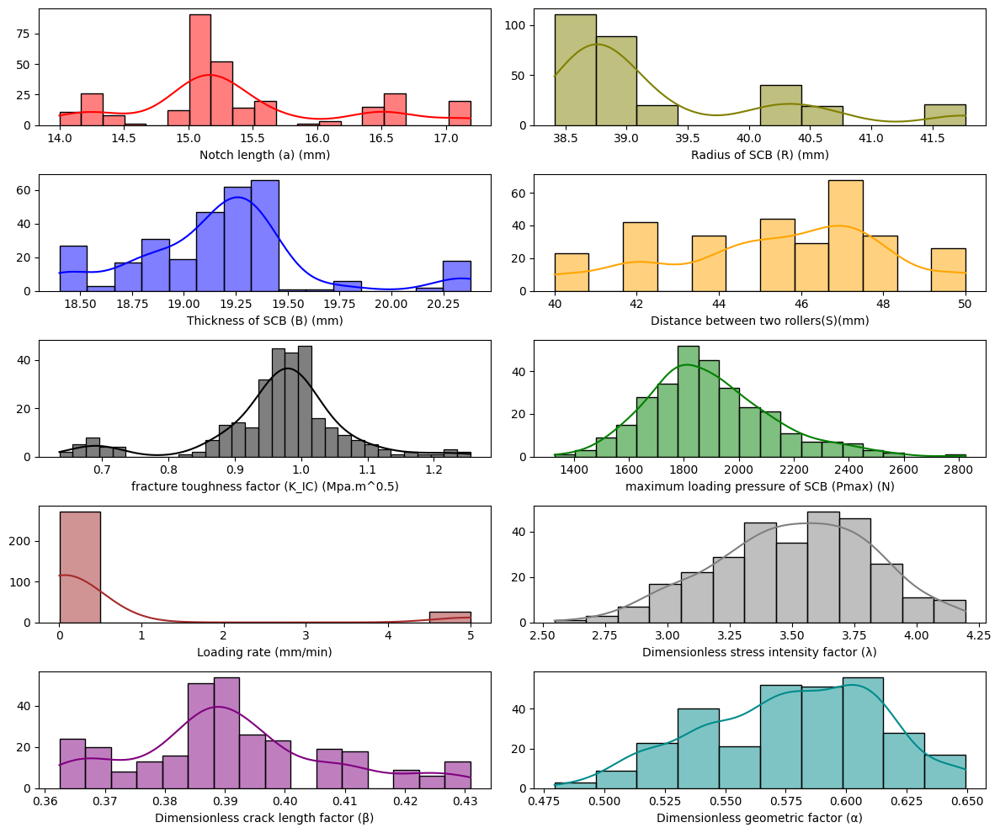

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# Remove extra spaces from columns names
df.columns = df.columns.str.strip()


target_columns =["Notch length (a) (mm)",
                        "Radius of SCB (R) (mm)",
                        "Thickness of SCB (B) (mm)",
                        "Distance between two rollers(S)(mm)",
                        "fracture toughness factor (K_IC) (Mpa.m^0.5)",
                        "maximum loading pressure of SCB (Pmax) (N)",
                        "Loading rate (mm/min)",
                        "Dimensionless stress intensity factor (λ)",
                        "Dimensionless crack length factor (β)",
                        "Dimensionless geometric factor (α)"
 ]

# create subplots
fig, axes =plt.subplots(5,2, figsize=(12,10))
colors =["red", "olive", "blue","orange", "black", "green", "brown","gray","purple","darkcyan"]

# Drawing scatter plots
for ax, col, color in zip(axes.flatten(), target_columns, colors):
  sns.histplot(df[col], color=color, kde=True, ax=ax)
  ax.set_xlabel(col)
  ax.set_ylabel('')
plt.tight_layout()
plt.show()

Box plot


/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:700: 

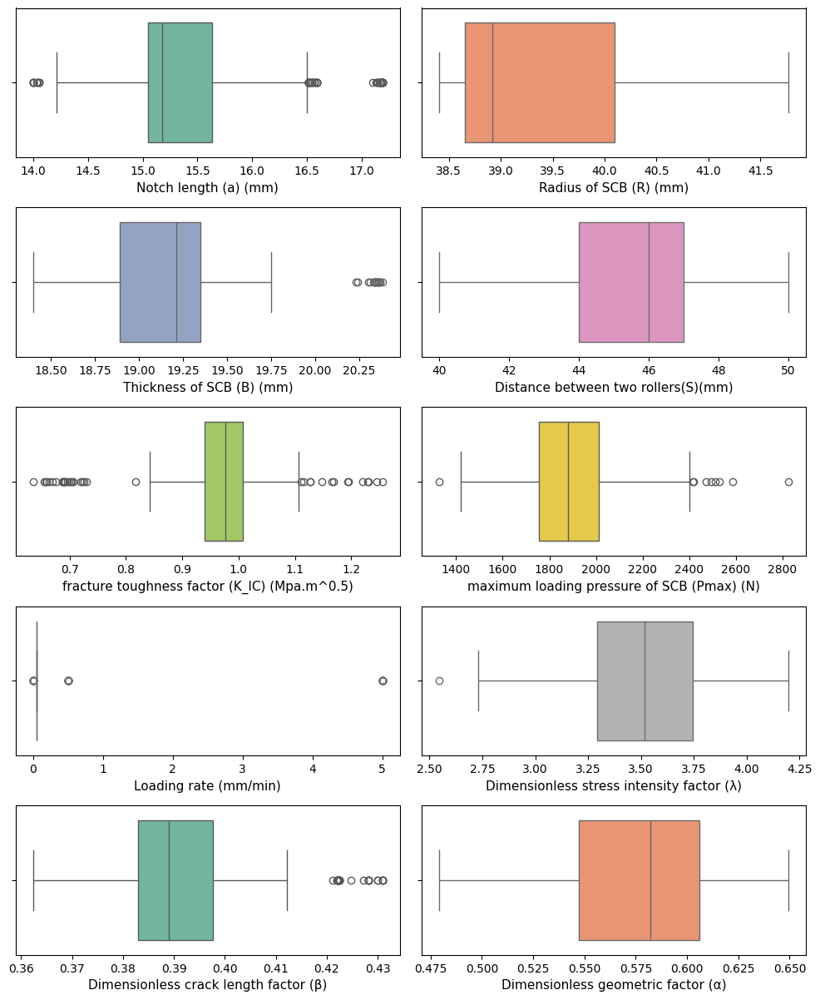

In [ ]:
columns_with_outliers =["Notch length (a) (mm)",
                        "Radius of SCB (R) (mm)",
                        "Thickness of SCB (B) (mm)",
                        "Distance between two rollers(S)(mm)",
                        "fracture toughness factor (K_IC) (Mpa.m^0.5)",
                        "maximum loading pressure of SCB (Pmax) (N)",
                        "Loading rate (mm/min)",
                        "Dimensionless stress intensity factor (λ)",
                        "Dimensionless crack length factor (β)",
                        "Dimensionless geometric factor (α)"
 ]

n_cols=2
n_rows = -(-len(columns_with_outliers)// n_cols)

fig, axes= plt.subplots( n_rows, n_cols,  figsize=(10,2.5* n_rows))
axes = axes.flatten()

colors = sns.color_palette("Set2", len(columns_with_outliers))


for i, col in enumerate( columns_with_outliers):
  sns.boxplot(x=df[col], ax=axes[i], color=colors[i])
  axes[i].set_title("")
  axes[i].set_xlabel(col, fontsize=11)

for j in range(i+1, len(axes)):
  fig.delaxes(axes[j])


plt.tight_layout(rect=[0,0,1,0.97])
plt.show()

numbsr of outliers

In [ ]:
import numpy as np

for column in df.select_dtypes(include=np.number).columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers_count = df[(df[column] < lower_bound) | (df[column] > upper_bound)][column].count()

    if outliers_count > 0:
        print(f"\nOutliers count for column '{column}': {outliers_count}")
    else:
        print(f"\nNo outliers found for column '{column}'0")


Outliers count for column 'Notch length (a) (mm)': 57

No outliers found for column 'Radius of SCB (R) (mm)'0

Outliers count for column 'Thickness of SCB (B) (mm)': 20

No outliers found for column 'Distance between two rollers(S)(mm)'0

No outliers found for column 'Dimensionless geometric factor (α)'0

Outliers count for column 'Dimensionless crack length factor (β)': 28

Outliers count for column 'Loading rate (mm/min)': 75

Outliers count for column 'maximum loading pressure of SCB (Pmax) (N)': 9

Outliers count for column 'Dimensionless stress intensity factor (λ)': 1

Outliers count for column 'fracture toughness factor (K_IC) (Mpa.m^0.5)': 38


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Caping laboratory features

 Notch length (a) (mm): 57 Corrected outlier data (lower_bound =14.176, upper_bound =16.506)


/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


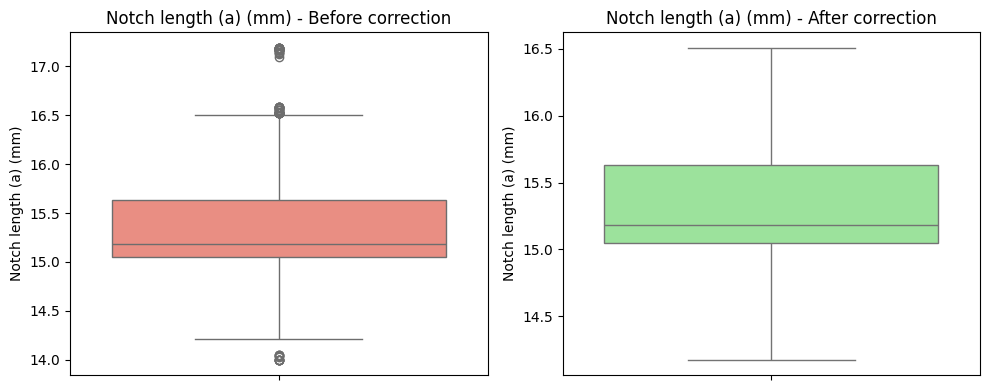

 Radius of SCB (R) (mm): No outlier data 


/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


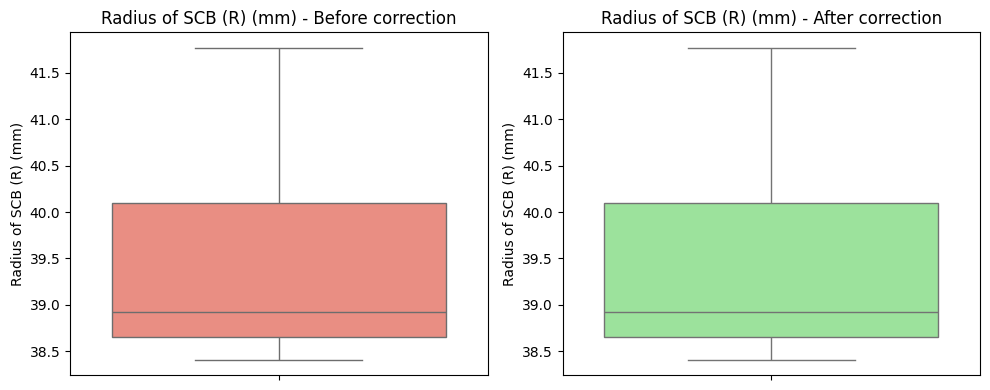

 Thickness of SCB (B) (mm): 20 Corrected outlier data (lower_bound =18.200, upper_bound =20.040)


/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


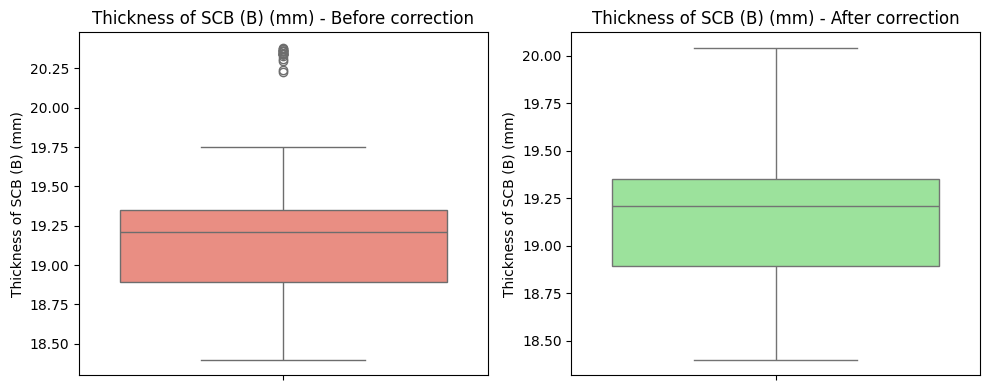

 Distance between two rollers(S)(mm): No outlier data 


/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


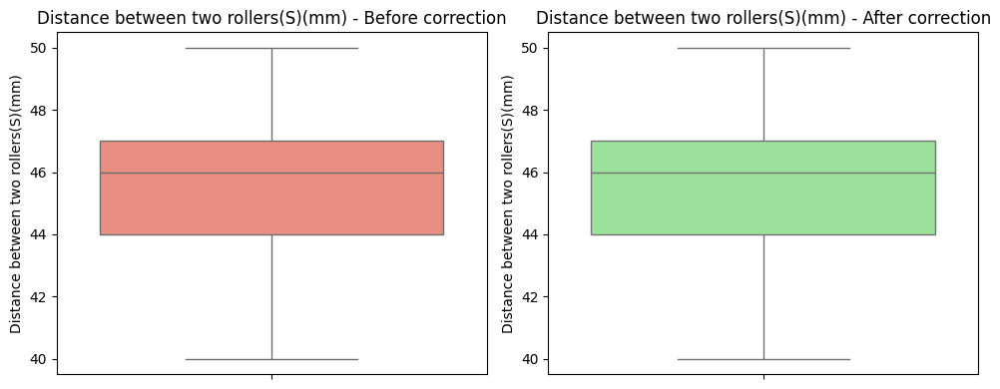

 Dimensionless geometric factor (α): No outlier data 


/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


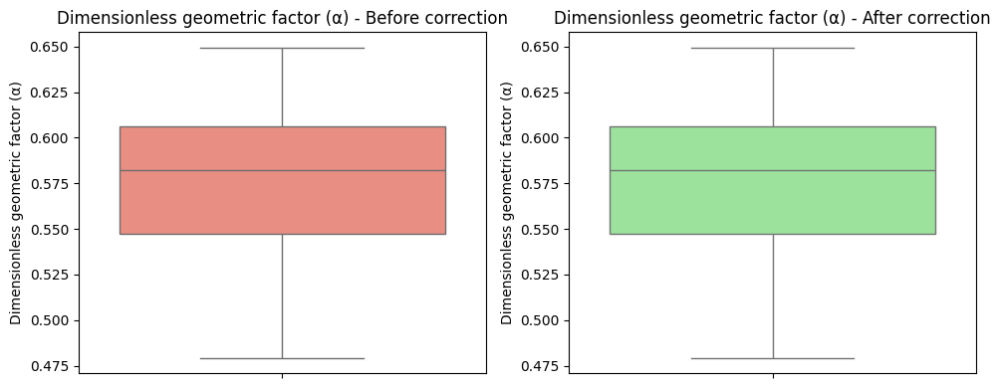

 Dimensionless crack length factor (β): 28 Corrected outlier data (lower_bound =0.361, upper_bound =0.420)


/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


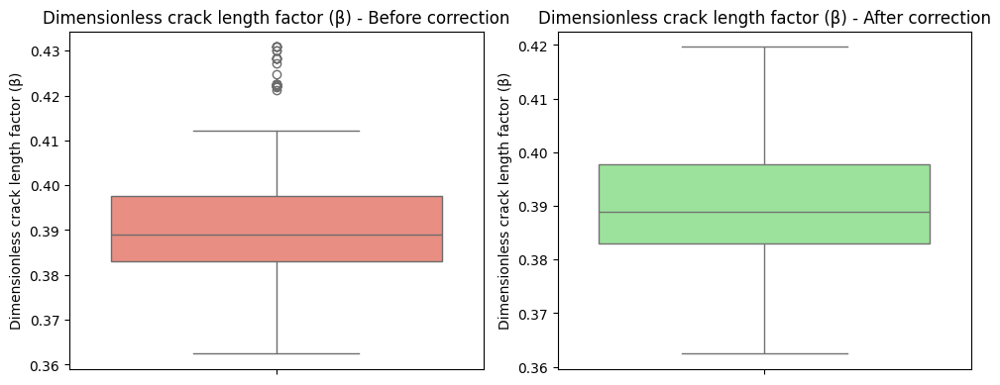

 Dimensionless stress intensity factor (λ): 1 Corrected outlier data (lower_bound =2.620, upper_bound =4.418)


/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


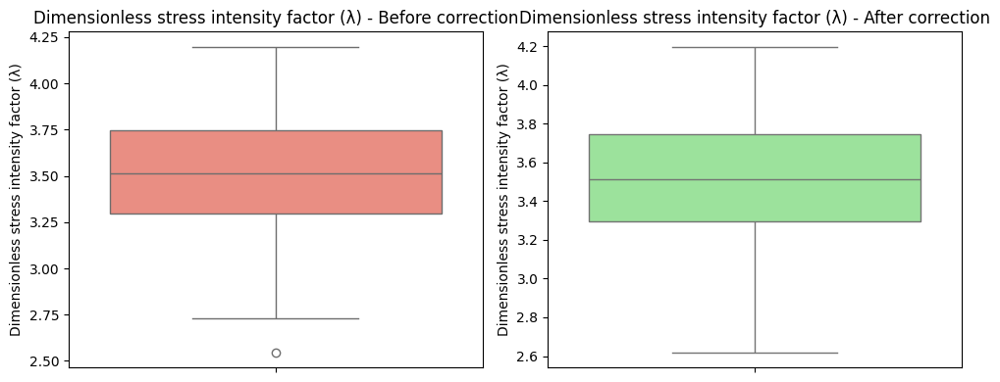

In [ ]:
# Smart function to correct outliers by drawing a graph
def smart_cap_outliers_with_plot(df, show_plots=True, exclude_cols=None):
    df_capped = df.copy()
    numeric_cols = df.select_dtypes(include=[np.number]).columns

    # If there are any columns to exclude, remove them.
    if exclude_cols is not None:
        numeric_cols = [col for col in numeric_cols if col not in exclude_cols]

    for col in numeric_cols:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        num_lower_outliers = (df[col] < lower_bound).sum()
        num_upper_outliers = (df[col] > upper_bound).sum()

        # If there are outliers, correction should be made.
        if num_lower_outliers > 0 or num_upper_outliers > 0:
            df_capped[col] = np.where(df[col] < lower_bound, lower_bound, df[col])
            df_capped[col] = np.where(df_capped[col] > upper_bound, upper_bound, df_capped[col])
            print(f" {col}: {num_lower_outliers + num_upper_outliers} Corrected outlier data "
                  f"(lower_bound ={lower_bound:.3f}, upper_bound ={upper_bound:.3f})")
        else:
            print(f" {col}: No outlier data ")

        # Show boxplot before and after correction
        if show_plots:
            fig, axes = plt.subplots(1, 2, figsize=(10, 4))
            sns.boxplot(y=df[col], ax=axes[0], color='salmon')
            sns.boxplot(y=df_capped[col], ax=axes[1], color='lightgreen')
            axes[0].set_title(f"{col} - Before correction")
            axes[1].set_title(f"{col} - After correction")
            plt.tight_layout()
            plt.show()

    return df_capped

df_c = smart_cap_outliers_with_plot(df, exclude_cols=['Loading rate (mm/min)',
                                                      'maximum loading pressure of SCB (Pmax) (N)',
                                                      "fracture toughness factor (K_IC) (Mpa.m^0.5)"])


Pearson and Spearman plot

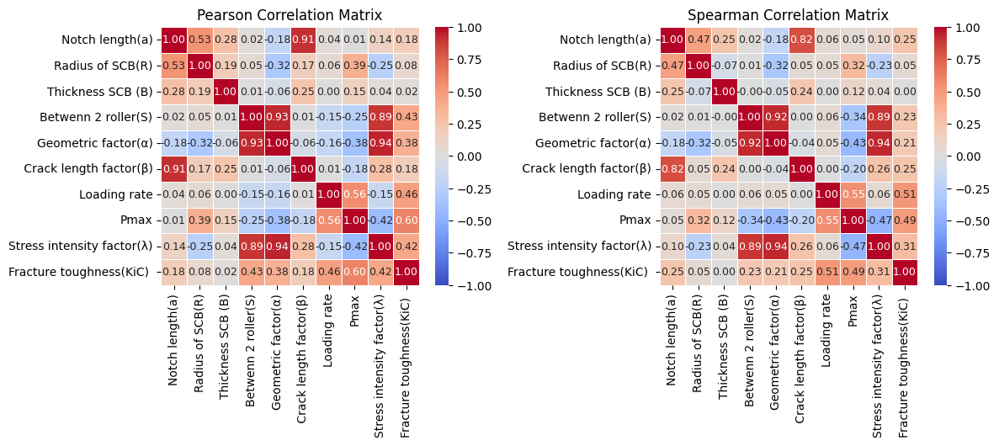

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# Custom labels for columns and rows
labels = ['Notch length(a)',
          'Radius of SCB(R)',
          'Thickness SCB (B)',
          'Betwenn 2 roller(S)',
          'Geometric factor(α)',
          ' Crack length factor(β)',
          'Loading rate',
          'Pmax',
          'Stress intensity factor(λ)',
          'Fracture toughness(KiC) '
]

# Calculating correlation matrices
pearson_corr = df_c.corr(method='pearson')
spearman_corr = df_c.corr(method='spearman')

# Draw a shape with the proper aspect ratio for accurate alignment
fig, axes = plt.subplots(1, 2, figsize=(12,5))

# Pearson
sns.heatmap(
    pearson_corr,
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    cmap='coolwarm',
    square=True,
    xticklabels=labels,
    yticklabels=labels,
    vmin=-1,
    vmax=1,
    ax=axes[0],
    cbar=True,
    annot_kws={"size": 9}
)
axes[0].set_title('Pearson Correlation Matrix', fontsize=12)
axes[0].tick_params(axis='x', labelrotation=90)
axes[0].tick_params(axis='y', labelrotation=0)

# Spearman
sns.heatmap(
    spearman_corr,
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    cmap='coolwarm',
    square=True,
    xticklabels=labels,
    yticklabels=labels,
    vmin=-1,
    vmax=1,
    ax=axes[1],
    cbar=True,
    annot_kws={"size": 9}
)
axes[1].set_title('Spearman Correlation Matrix', fontsize=12)
axes[1].tick_params(axis='x', labelrotation=90)
axes[1].tick_params(axis='y', labelrotation=0)

plt.tight_layout()
plt.savefig("correlation_matrix_tight.png", dpi=300, bbox_inches='tight')
plt.show()

Remove unnecessary features

In [ ]:
# Remove unnecessary features from df_c
# Remove extra spaces from column names
df_c.columns = df_c.columns.str.strip()

# List of columns to be removed
columns_to_drop = [
    "Dimensionless stress intensity factor (λ)",
    "Dimensionless crack length factor (β)",
    "Dimensionless geometric factor (α)"
    ]

# Remove spaces from the column list
columns_to_drop = [col.strip() for col in columns_to_drop]

# Check which columns actually exist in df_c
existing_columns = df_c.columns.tolist()
columns_to_drop_in_df = [col for col in columns_to_drop if col in existing_columns]

print("Columns to drop (that exist in df_c):", columns_to_drop_in_df)
print("All existing columns in df_c:", df_c.columns.tolist())

# # Delete existing columns
df_c = df_c.drop(columns=columns_to_drop_in_df, errors='ignore')

print(" Columns after dropping unnecessary features:", df_c.shape)
print(" Remaining columns:", df_c.columns.tolist())


Columns to drop (that exist in df_c): ['Dimensionless stress intensity factor (λ)', 'Dimensionless crack length factor (β)', 'Dimensionless geometric factor (α)']
All existing columns in df_c: ['Notch length (a) (mm)', 'Radius of SCB (R) (mm)', 'Thickness of SCB (B) (mm)', 'Distance between two rollers(S)(mm)', 'Dimensionless geometric factor (α)', 'Dimensionless crack length factor (β)', 'Loading rate (mm/min)', 'maximum loading pressure of SCB (Pmax) (N)', 'Dimensionless stress intensity factor (λ)', 'fracture toughness factor (K_IC) (Mpa.m^0.5)']
 Columns after dropping unnecessary features: (300, 7)
 Remaining columns: ['Notch length (a) (mm)', 'Radius of SCB (R) (mm)', 'Thickness of SCB (B) (mm)', 'Distance between two rollers(S)(mm)', 'Loading rate (mm/min)', 'maximum loading pressure of SCB (Pmax) (N)', 'fracture toughness factor (K_IC) (Mpa.m^0.5)']


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Separate features and target

In [ ]:
# Split first
from sklearn.model_selection import train_test_split
# 1. Separate features and target
X = df_c.drop(columns=["maximum loading pressure of SCB (Pmax) (N)"], axis=1).values  # Features
y = df_c["maximum loading pressure of SCB (Pmax) (N)"].values.reshape(-1, 1)          # Target (reshaped to 2D)

# Step 1: Separate test data (10%)
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.10, random_state=42)

print(f"temp:{len(X_temp)}, Test: {len(X_test)}")

temp:270, Test: 30


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


SVR model

Running Grid Search ...
Fitting 5 folds for each of 48 candidates, totalling 240 fits
Grid Search Time: 3.18 seconds

Best Parameters Found:
   C: 10
   epsilon: 0.01
   gamma: 0.01
   kernel: rbf
Best CV MSE = 0.0062

Running 5-Fold Cross Validation with best SVR parameters...
 Fold 1: Train R²=0.9949, Val R²=0.9864
 Fold 2: Train R²=0.9950, Val R²=0.9925
 Fold 3: Train R²=0.9957, Val R²=0.9968
 Fold 4: Train R²=0.9968, Val R²=0.9927
 Fold 5: Train R²=0.9955, Val R²=0.9901

Mean Train R²: 0.9956
Mean Val   R²: 0.9917
5-Fold CV Time: 0.07 seconds

Generating Learning Curve (matching the original buggy validation method)...
  size=  54 | Train RMSE=21.9179 | Val RMSE=50.8111
  size=  81 | Train RMSE=18.6102 | Val RMSE=44.1971
  size= 108 | Train RMSE=16.4568 | Val RMSE=29.9716
  size= 135 | Train RMSE=15.0698 | Val RMSE=24.8544
  size= 162 | Train RMSE=14.5182 | Val RMSE=25.3735
  size= 189 | Train RMSE=15.1960 | Val RMSE=21.6675
  size= 216 | Train RMSE=15.0179 | Val RMSE=21.0002
  siz

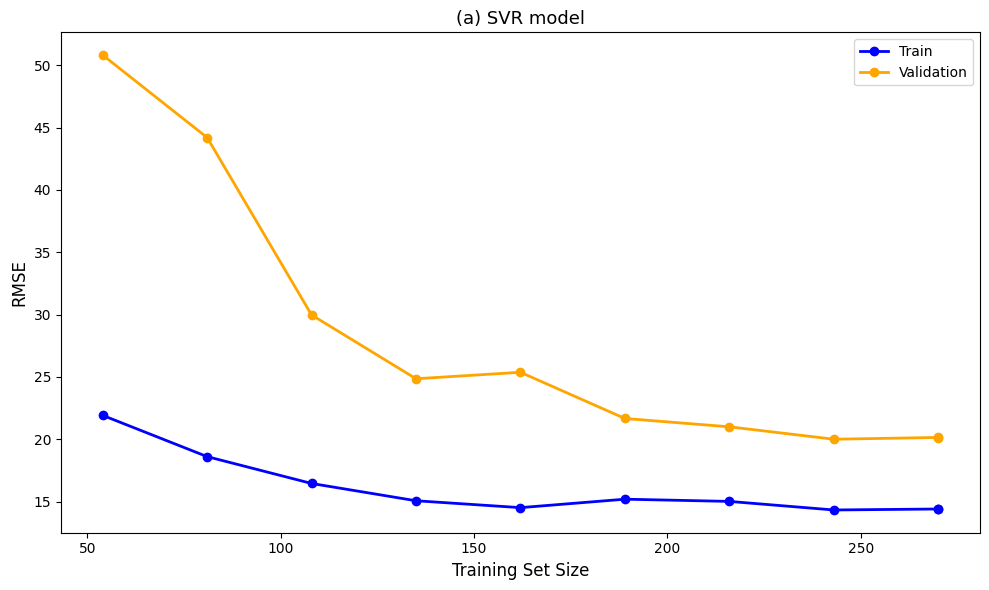


Final Evaluation (exactly matching original code)

Final Train Performance (on all X_temp):
   MSE  = 207.2329
   MAE  = 7.6903
   RMSE = 14.3956
   R²   = 0.9958

Final Validation Performance (on all X_temp):
   MSE  = 404.6523
   MAE  = 10.2642
   RMSE = 20.1160
   R2   = 0.9907

Test Performance:
   MSE  = 336.2272
   MAE  = 10.7387
   RMSE = 18.3365
   R²   = 0.9951

****************
SVR Computational Cost
******************
Grid Search Time : 3.1786 s
5-Fold CV Time : 0.0657 s
test time : 0.0028s
Final Training Time : 0.0035 s
Total Training Time : 3.2478 s
Total Training Time : 0.0541 min


In [ ]:
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import matplotlib.pyplot as plt
import time


# GridSearchCV
# Base model
svr = SVR()
# Hyperparameter search space
param_grid = {
    'kernel': ['rbf'],
    'C': [0.1, 1, 10],
    'gamma': ['scale', 'auto', 0.01, 0.1],
    'epsilon': [0.01, 0.1, 0.5, 1.0]
}

X_scaler_grid = StandardScaler()
y_scaler_grid = StandardScaler()

X_temp_scaled_for_grid = X_scaler_grid.fit_transform(X_temp)
y_temp_scaled_for_grid = y_scaler_grid.fit_transform(y_temp)

start_grid_time = time.perf_counter()
grid_search = GridSearchCV(
    estimator=svr,
    param_grid=param_grid,
    scoring='neg_mean_squared_error',
    cv=5,
    n_jobs=-1,
    verbose=1
)

print("Running Grid Search ...")
grid_search.fit(X_temp_scaled_for_grid, y_temp_scaled_for_grid.ravel())
end_grid_time = time.perf_counter()
grid_search_time = end_grid_time - start_grid_time
print(f"Grid Search Time: {grid_search_time:.2f} seconds")

best_params = grid_search.best_params_
print("\nBest Parameters Found:")
for k, v in best_params.items():
    print(f"   {k}: {v}")
print(f"Best CV MSE = {-grid_search.best_score_:.4f}")

# 5-Fold Cross Validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_results = {"train": [], "val": []}
start_cv_time = time.perf_counter()
print("\nRunning 5-Fold Cross Validation with best SVR parameters...")

for fold, (train_idx, val_idx) in enumerate(kf.split(X_temp)):
    X_tr, X_val = X_temp[train_idx], X_temp[val_idx]
    y_tr, y_val = y_temp[train_idx], y_temp[val_idx]

    # Separate normalization in each fold
    X_scaler_fold = StandardScaler()
    y_scaler_fold = StandardScaler()

    X_tr_scaled = X_scaler_fold.fit_transform(X_tr)
    y_tr_scaled = y_scaler_fold.fit_transform(y_tr)
    X_val_scaled = X_scaler_fold.transform(X_val)
    y_val_scaled = y_scaler_fold.transform(y_val)

    # Make a copy of best_svr to train on each fold,
    # otherwise, it gets continually refitted
    model_fold = SVR(**best_params)
    model_fold.fit(X_tr_scaled, y_tr_scaled.ravel())

    # Train and Val prediction
    y_tr_pred = y_scaler_fold.inverse_transform(
        model_fold.predict(X_tr_scaled).reshape(-1, 1)
    )
    y_val_pred = y_scaler_fold.inverse_transform(
        model_fold.predict(X_val_scaled).reshape(-1, 1)
    )
    y_tr_true = y_scaler_fold.inverse_transform(y_tr_scaled)
    y_val_true = y_scaler_fold.inverse_transform(y_val_scaled)

    # Metrics
    train_r2 = r2_score(y_tr_true, y_tr_pred)
    val_r2 = r2_score(y_val_true, y_val_pred)

    print(f" Fold {fold+1}: Train R²={train_r2:.4f}, Val R²={val_r2:.4f}")

    cv_results["train"].append(train_r2)
    cv_results["val"].append(val_r2)

print(f"\nMean Train R²: {np.mean(cv_results['train']):.4f}")
print(f"Mean Val   R²: {np.mean(cv_results['val']):.4f}")

end_cv_time = time.perf_counter()
cv_time = end_cv_time - start_cv_time
print(f"5-Fold CV Time: {cv_time:.2f} seconds")

# Learning Curve

print("\nGenerating Learning Curve (matching the original buggy validation method)...")

train_sizes_abs = np.linspace(0.2, 1.0, 9)
train_sizes = (train_sizes_abs * len(X_temp)).astype(int)

train_rmse_list = []
val_rmse_list = []

for size in train_sizes:
    rng = np.random.RandomState(42)
    indices = rng.choice(len(X_temp), size=size, replace=False)

    X_sub = X_temp[indices]
    y_sub = y_temp[indices]

    X_scaler = StandardScaler()
    y_scaler = StandardScaler()

    X_sub_scaled = X_scaler.fit_transform(X_sub)
    y_sub_scaled = y_scaler.fit_transform(y_sub)

    model = SVR(**best_params)
    model.fit(X_sub_scaled, y_sub_scaled.ravel())

    # Train RMSE
    y_sub_pred = y_scaler.inverse_transform(
        model.predict(X_sub_scaled).reshape(-1, 1)
    )
    train_rmse = np.sqrt(mean_squared_error(y_sub, y_sub_pred))
    train_rmse_list.append(train_rmse)

    # Validation
    y_val_pred_scaled = model.predict(X_val_scaled)
    y_val_pred = y_scaler.inverse_transform(y_val_pred_scaled.reshape(-1, 1))
    y_val_true = y_scaler.inverse_transform(y_val_scaled)

    val_rmse = np.sqrt(mean_squared_error(y_val_true, y_val_pred))
    val_rmse_list.append(val_rmse)

    print(f"  size={size:4d} | Train RMSE={train_rmse:.4f} | Val RMSE={val_rmse:.4f}")

final_X_scaler = StandardScaler()
final_y_scaler = StandardScaler()

X_final_train_scaled = final_X_scaler.fit_transform(X_temp)
y_final_train_scaled = final_y_scaler.fit_transform(y_temp)

final_svr_model = SVR(**best_params)
final_svr_model.fit(X_final_train_scaled, y_final_train_scaled.ravel())

# Train X_temp
start_train_time = time.time()
y_pred_final_train = final_y_scaler.inverse_transform(
    final_svr_model.predict(X_final_train_scaled).reshape(-1, 1)
)
end_train_time = time.time()
train_time = end_train_time - start_train_time
y_true_final_train = final_y_scaler.inverse_transform(y_final_train_scaled)
final_train_rmse = np.sqrt(mean_squared_error(y_true_final_train, y_pred_final_train))

# Validation
y_pred_final_validation_scaled = final_svr_model.predict(X_val_scaled)
y_pred_final_validation = final_y_scaler.inverse_transform(y_pred_final_validation_scaled.reshape(-1, 1))
y_true_final_validation = final_y_scaler.inverse_transform(y_val_scaled)

final_val_rmse = np.sqrt(mean_squared_error(y_true_final_validation, y_pred_final_validation))

print(f"  Full X_temp Train RMSE = {final_train_rmse:.4f}")
print(f"  Validation RMSE (original method) = {final_val_rmse:.4f}")

train_sizes = np.append(train_sizes, len(X_temp))
train_rmse_list.append(final_train_rmse)
val_rmse_list.append(final_val_rmse)

# Draw Learning Curve

plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_rmse_list, 'o-', color='blue', linewidth=2, label='Train')
plt.plot(train_sizes, val_rmse_list, 'o-', color='orange', linewidth=2, label='Validation')
plt.title('(a) SVR model', fontsize=13)
plt.xlabel('Training Set Size', fontsize=12)
plt.ylabel('RMSE', fontsize=12)
plt.legend(loc='best')
plt.tight_layout()
plt.show()


#  Final Evaluation
print("\n" + "="*60)
print("Final Evaluation (exactly matching original code)")
print("="*60)

# Train
mse_final_train = mean_squared_error(y_true_final_train, y_pred_final_train)
mae_final_train = mean_absolute_error(y_true_final_train, y_pred_final_train)
rmse_final_train = np.sqrt(mse_final_train)
r2_final_train = r2_score(y_true_final_train, y_pred_final_train)

print(f"\nFinal Train Performance (on all X_temp):")
print(f"   MSE  = {mse_final_train:.4f}")
print(f"   MAE  = {mae_final_train:.4f}")
print(f"   RMSE = {rmse_final_train:.4f}")
print(f"   R²   = {r2_final_train:.4f}")

# Validation
mse_final_validation = mean_squared_error(y_true_final_validation, y_pred_final_validation)
mae_final_validation = mean_absolute_error(y_true_final_validation, y_pred_final_validation)
rmse_final_validation = np.sqrt(mse_final_validation)
r2_final_validation = r2_score(y_true_final_validation, y_pred_final_validation)

print(f"\nFinal Validation Performance (on all X_temp):")
print(f"   MSE  = {mse_final_validation:.4f}")
print(f"   MAE  = {mae_final_validation:.4f}")
print(f"   RMSE = {rmse_final_validation:.4f}")
print(f"   R2   = {r2_final_validation:.4f}")

# Test
X_test_scaled = final_X_scaler.transform(X_test)
y_test_scaled = final_y_scaler.transform(y_test)
start_test_time = time.perf_counter()
y_pred_test = final_y_scaler.inverse_transform(
    final_svr_model.predict(X_test_scaled).reshape(-1, 1)
)
end_test_time = time.perf_counter()
test_time = end_test_time - start_test_time
y_true_test = final_y_scaler.inverse_transform(y_test_scaled)

mse_test = mean_squared_error(y_true_test, y_pred_test)
mae_test = mean_absolute_error(y_true_test, y_pred_test)
rmse_test = np.sqrt(mse_test)
r2_test = r2_score(y_true_test, y_pred_test)

print(f"\nTest Performance:")
print(f"   MSE  = {mse_test:.4f}")
print(f"   MAE  = {mae_test:.4f}")
print(f"   RMSE = {rmse_test:.4f}")
print(f"   R²   = {r2_test:.4f}")
total_time = (
    grid_search_time +
    cv_time +
    train_time
    )
print("\n****************")
print("SVR Computational Cost")
print("******************")

print(f"Grid Search Time : {grid_search_time:.4f} s")
print(f"5-Fold CV Time : {cv_time:.4f} s")
print(f"test time : {test_time:.4f}s" )
print(f"Final Training Time : {train_time:.4f} s")
print(f"Total Training Time : {total_time:.4f} s")
print(f"Total Training Time : {total_time/60:.4f} min")

Actual vs Predicted and Residuals SVR

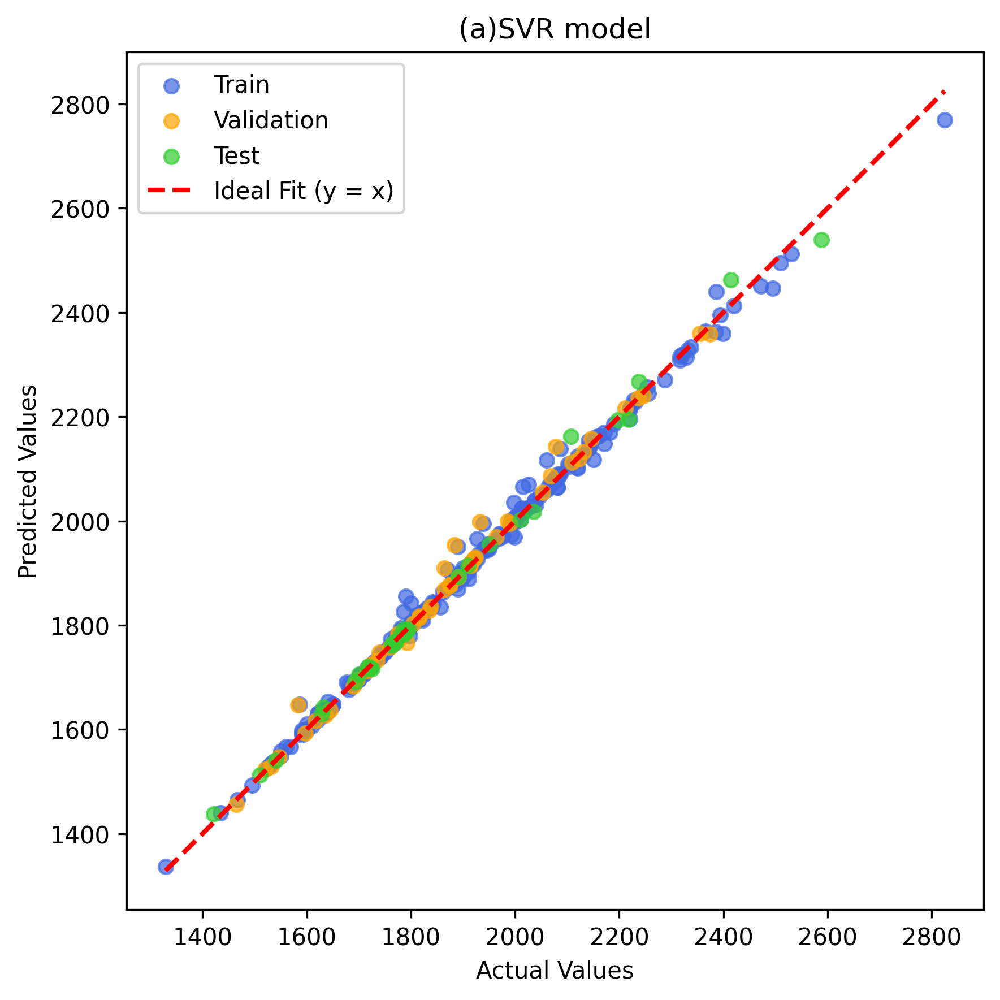

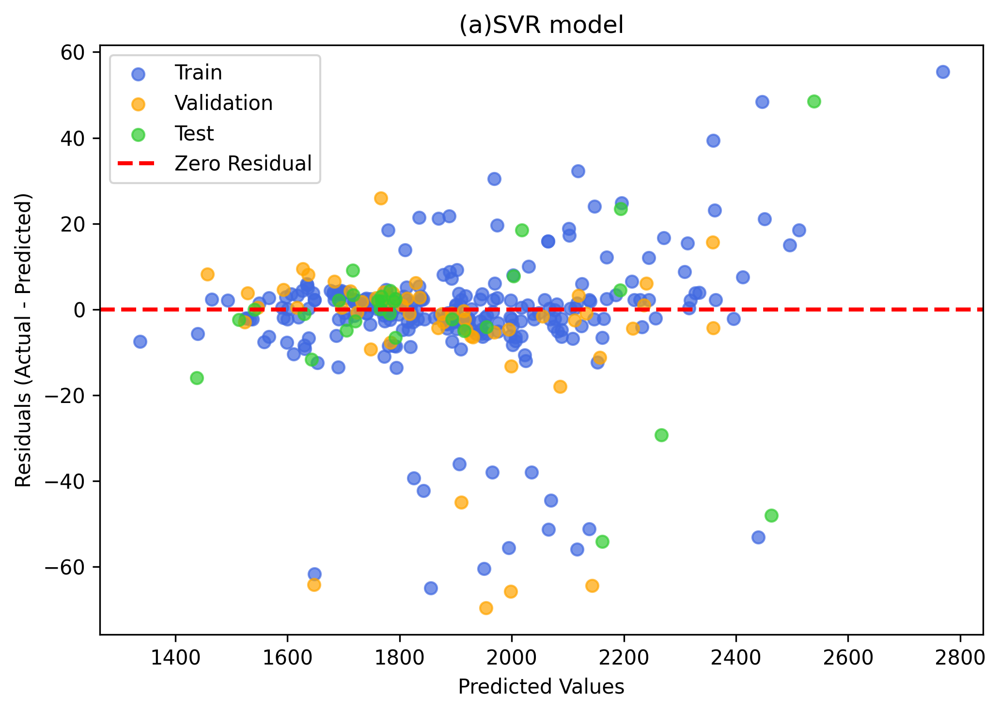

In [ ]:
# Actual vs Predicted (Train / Val / Test)

def plot_combined_predictions(y_true_train, y_pred_train,
                              y_true_val, y_pred_val,
                              y_true_test, y_pred_test):
    # Convert to 1D array
    y_true_train, y_pred_train = np.ravel(y_true_train), np.ravel(y_pred_train)
    y_true_val,   y_pred_val   = np.ravel(y_true_val),   np.ravel(y_pred_val)
    y_true_test,  y_pred_test  = np.ravel(y_true_test),  np.ravel(y_pred_test)

    plt.figure(figsize=(6,6),dpi=300)
    plt.scatter(y_true_train, y_pred_train, color='royalblue', alpha=0.7, label='Train')
    plt.scatter(y_true_val,   y_pred_val,   color='orange', alpha=0.7, label='Validation')
    plt.scatter(y_true_test,  y_pred_test,  color='limegreen', alpha=0.7, label='Test')

    # Ideal line y = x
    all_true = np.concatenate([y_true_train, y_true_val, y_true_test])
    plt.plot([all_true.min(), all_true.max()],
             [all_true.min(), all_true.max()], 'r--', lw=2, label='Ideal Fit (y = x)')

    plt.title("(a)SVR model")
    plt.xlabel("Actual Values")
    plt.ylabel("Predicted Values")
    plt.legend()
    plt.grid(False)
    plt.tight_layout()
    plt.show()



# Residuals (Train / Val / Test)

def plot_combined_residuals(y_true_train, y_pred_train,
                            y_true_val, y_pred_val,
                            y_true_test, y_pred_test):
    y_true_train, y_pred_train = np.ravel(y_true_train), np.ravel(y_pred_train)
    y_true_val,   y_pred_val   = np.ravel(y_true_val),   np.ravel(y_pred_val)
    y_true_test,  y_pred_test  = np.ravel(y_true_test),  np.ravel(y_pred_test)

    residuals_train = y_true_train - y_pred_train
    residuals_val   = y_true_val   - y_pred_val
    residuals_test  = y_true_test  - y_pred_test

    plt.figure(figsize=(7,5),dpi=300)
    plt.scatter(y_pred_train, residuals_train, color='royalblue', alpha=0.7, label='Train')
    plt.scatter(y_pred_val,   residuals_val,   color='orange', alpha=0.7, label='Validation')
    plt.scatter(y_pred_test,  residuals_test,  color='limegreen', alpha=0.7, label='Test')

    plt.axhline(0, color='red', linestyle='--', lw=2, label='Zero Residual')
    plt.title("(a)SVR model")
    plt.xlabel("Predicted Values")
    plt.ylabel("Residuals (Actual - Predicted)")
    plt.legend()
    plt.grid(False)
    plt.tight_layout()
    plt.show()

plot_combined_predictions(
    y_true_final_train, y_pred_final_train,
    y_true_final_validation, y_pred_final_validation,
    y_true_test, y_pred_test
)

plot_combined_residuals(
    y_true_final_train, y_pred_final_train,
    y_true_final_validation, y_pred_final_validation,
    y_true_test, y_pred_test
)


GPR model

Running Grid Search ...
Fitting 5 folds for each of 8 candidates, totalling 40 fits


/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


Grid Search Time = 37.7673 seconds
Grid Search Time = 0.6295 minutes

Best Parameters Found:
   alpha: 0.1
   kernel: 1**2 * RBF(length_scale=5) + WhiteKernel(noise_level=5)
   n_restarts_optimizer: 3
   normalize_y: True
Best CV MSE = 0.0093

Running 5-Fold Cross Validation with best GPR parameters...


/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


 Fold 1: Train R²=0.9917, Val R²=0.9837


/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


... (21 outputs left out)

/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


  size= 270 | Train RMSE=18.0316 | Val RMSE=19.3348

Adding final point exactly like the original code...


/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


  Full X_temp Train RMSE = 18.0316
  Validation RMSE (original method) = 19.3348


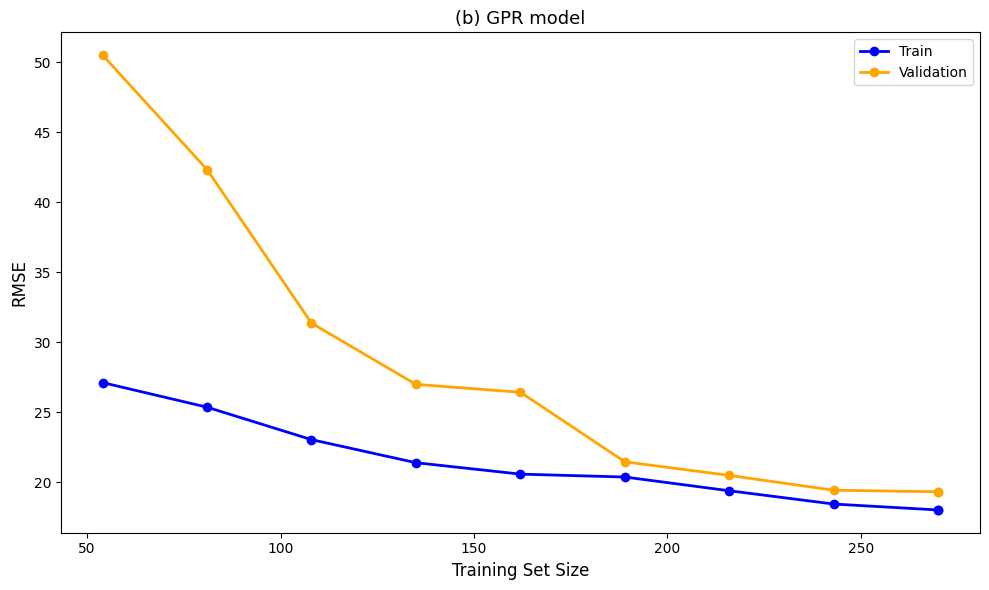


Final Evaluation (exactly matching original code)

Final Train Performance (on all X_temp):
   MSE  = 325.1375
   MAE  = 13.3837
   RMSE = 18.0316
   R²   = 0.9934

Final Validation Performance (on all X_temp):
   MSE  = 373.8347
   MAE  = 13.3245
   RMSE = 19.3348
   R2   = 0.9914

Test Performance:
   MSE  = 305.5068
   MAE  = 12.0161
   RMSE = 17.4788
   R²   = 0.9955

GPR Computational Cost
Grid Search Time      : 37.7673 s
5-Fold CV Time        : 129.0536 s
test time             : 0.0036s
Final Training Time   : 0.0044 s
Total Training Time   : 166.8253 s
Total Training Time   : 2.7804 min


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (
    RBF, Matern, RationalQuadratic, WhiteKernel,
    ConstantKernel, DotProduct)
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import matplotlib.pyplot as plt
import time

# 1. GridSearchCV
gpr = GaussianProcessRegressor()

kernel_options = [
    ConstantKernel(1.0) * RBF(length_scale=5.0) + WhiteKernel(noise_level=5.0),
    ConstantKernel(1.0) * Matern(length_scale=5.0, nu=1.5) + WhiteKernel(noise_level=5.0),
]

param_grid = {
    'kernel': kernel_options,
    'alpha': [1e-1],
    'n_restarts_optimizer': [3, 5],
    'normalize_y': [True, False]
}

X_scaler_grid = StandardScaler()
y_scaler_grid = StandardScaler()

X_temp_scaled_for_grid = X_scaler_grid.fit_transform(X_temp)
y_temp_scaled_for_grid = y_scaler_grid.fit_transform(y_temp)

start_grid_time = time.perf_counter()
grid_search = GridSearchCV(
    estimator=gpr,
    param_grid=param_grid,
    scoring='neg_mean_squared_error',
    cv=5,
    n_jobs=-1,
    verbose=1
)

print("Running Grid Search ...")
grid_search.fit(X_temp_scaled_for_grid, y_temp_scaled_for_grid.ravel())
end_grid_time = time.perf_counter()
grid_search_time = end_grid_time - start_grid_time
print(f"Grid Search Time = {grid_search_time:.4f} seconds")
print(f"Grid Search Time = {grid_search_time/60:.4f} minutes")

best_params = grid_search.best_params_
print("\nBest Parameters Found:")
for k, v in best_params.items():
    print(f"   {k}: {v}")
print(f"Best CV MSE = {-grid_search.best_score_:.4f}")


# 5-Fold Cross Validation

kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_results = {"train": [], "val": []}

start_cv_evaluation_time = time.perf_counter()
print("\nRunning 5-Fold Cross Validation with best GPR parameters...")

for fold, (train_idx, val_idx) in enumerate(kf.split(X_temp)):
    X_tr, X_val = X_temp[train_idx], X_temp[val_idx]
    y_tr, y_val = y_temp[train_idx], y_temp[val_idx]

    # Separate normalization in each fold
    X_scaler_fold = StandardScaler()
    y_scaler_fold = StandardScaler()

    X_tr_scaled = X_scaler_fold.fit_transform(X_tr)
    y_tr_scaled = y_scaler_fold.fit_transform(y_tr)
    X_val_scaled = X_scaler_fold.transform(X_val)
    y_val_scaled = y_scaler_fold.transform(y_val)

    model_fold = GaussianProcessRegressor(**best_params)
    model_fold.fit(X_tr_scaled, y_tr_scaled.ravel())

    y_tr_pred = y_scaler_fold.inverse_transform(
        model_fold.predict(X_tr_scaled).reshape(-1, 1)
    )
    y_val_pred = y_scaler_fold.inverse_transform(
        model_fold.predict(X_val_scaled).reshape(-1, 1)
    )
    y_tr_true = y_scaler_fold.inverse_transform(y_tr_scaled)
    y_val_true = y_scaler_fold.inverse_transform(y_val_scaled)

    train_r2 = r2_score(y_tr_true, y_tr_pred)
    val_r2 = r2_score(y_val_true, y_val_pred)

    print(f" Fold {fold+1}: Train R²={train_r2:.4f}, Val R²={val_r2:.4f}")

    cv_results["train"].append(train_r2)
    cv_results["val"].append(val_r2)

print(f"\nMean Train R²: {np.mean(cv_results['train']):.4f}")
print(f"Mean Val   R²: {np.mean(cv_results['val']):.4f}")
end_cv_time = time.perf_counter()
cv_time = end_cv_time - start_cv_time


# Learning Curve

print("\nGenerating Learning Curve (matching original structure)...")

train_sizes_abs = np.linspace(0.2, 1.0, 9)
train_sizes = (train_sizes_abs * len(X_temp)).astype(int)

train_rmse_list = []
val_rmse_list = []

for size in train_sizes:
    rng = np.random.RandomState(42)
    indices = rng.choice(len(X_temp), size=size, replace=False)

    X_sub = X_temp[indices]
    y_sub = y_temp[indices]

    X_scaler = StandardScaler()
    y_scaler = StandardScaler()

    X_sub_scaled = X_scaler.fit_transform(X_sub)
    y_sub_scaled = y_scaler.fit_transform(y_sub)

    model = GaussianProcessRegressor(**best_params)
    model.fit(X_sub_scaled, y_sub_scaled.ravel())

    # Train RMSE
    y_sub_pred = y_scaler.inverse_transform(
        model.predict(X_sub_scaled).reshape(-1, 1)
    )
    train_rmse = np.sqrt(mean_squared_error(y_sub, y_sub_pred))
    train_rmse_list.append(train_rmse)

    # Validation
    y_val_pred_scaled = model.predict(X_val_scaled)
    y_val_pred = y_scaler.inverse_transform(y_val_pred_scaled.reshape(-1, 1))
    y_val_true = y_scaler.inverse_transform(y_val_scaled)

    val_rmse = np.sqrt(mean_squared_error(y_val_true, y_val_pred))
    val_rmse_list.append(val_rmse)

    print(f"  size={size:4d} | Train RMSE={train_rmse:.4f} | Val RMSE={val_rmse:.4f}")

print("\nAdding final point exactly like the original code...")

final_X_scaler = StandardScaler()
final_y_scaler = StandardScaler()

X_final_train_scaled = final_X_scaler.fit_transform(X_temp)
y_final_train_scaled = final_y_scaler.fit_transform(y_temp)

final_gpr_model = GaussianProcessRegressor(**best_params)
final_gpr_model.fit(X_final_train_scaled, y_final_train_scaled.ravel())

# Train X_temp
start_train_time = time.perf_counter()
y_pred_final_train = final_y_scaler.inverse_transform(
    final_gpr_model.predict(X_final_train_scaled).reshape(-1, 1)
)
end_train_time = time.perf_counter()
train_time = end_train_time - start_train_time
y_true_final_train = final_y_scaler.inverse_transform(y_final_train_scaled)
final_train_rmse = np.sqrt(mean_squared_error(y_true_final_train, y_pred_final_train))

# Validation
y_pred_final_validation_scaled = final_gpr_model.predict(X_val_scaled)
y_pred_final_validation = final_y_scaler.inverse_transform(y_pred_final_validation_scaled.reshape(-1, 1))
y_true_final_validation = final_y_scaler.inverse_transform(y_val_scaled)

final_val_rmse = np.sqrt(mean_squared_error(y_true_final_validation, y_pred_final_validation))

print(f"  Full X_temp Train RMSE = {final_train_rmse:.4f}")
print(f"  Validation RMSE (original method) = {final_val_rmse:.4f}")

train_sizes = np.append(train_sizes, len(X_temp))
train_rmse_list.append(final_train_rmse)
val_rmse_list.append(final_val_rmse)

# Learning Curve

plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_rmse_list, 'o-', color='blue', linewidth=2, label='Train')
plt.plot(train_sizes, val_rmse_list, 'o-', color='orange', linewidth=2, label='Validation')
plt.title('(b) GPR model', fontsize=13)
plt.xlabel('Training Set Size', fontsize=12)
plt.ylabel('RMSE', fontsize=12)
plt.legend(loc='best')
plt.tight_layout()
plt.show()


# Final Evaluation

print("\n" + "="*60)
print("Final Evaluation (exactly matching original code)")
print("="*60)

# Train
mse_final_train = mean_squared_error(y_true_final_train, y_pred_final_train)
mae_final_train = mean_absolute_error(y_true_final_train, y_pred_final_train)
rmse_final_train = np.sqrt(mse_final_train)
r2_final_train = r2_score(y_true_final_train, y_pred_final_train)

print(f"\nFinal Train Performance (on all X_temp):")
print(f"   MSE  = {mse_final_train:.4f}")
print(f"   MAE  = {mae_final_train:.4f}")
print(f"   RMSE = {rmse_final_train:.4f}")
print(f"   R²   = {r2_final_train:.4f}")

# Validation
mse_final_validation = mean_squared_error(y_true_final_validation, y_pred_final_validation)
mae_final_validation = mean_absolute_error(y_true_final_validation, y_pred_final_validation)
rmse_final_validation = np.sqrt(mse_final_validation)
r2_final_validation = r2_score(y_true_final_validation, y_pred_final_validation)

print(f"\nFinal Validation Performance (on all X_temp):")
print(f"   MSE  = {mse_final_validation:.4f}")
print(f"   MAE  = {mae_final_validation:.4f}")
print(f"   RMSE = {rmse_final_validation:.4f}")
print(f"   R2   = {r2_final_validation:.4f}")

# Test
X_test_scaled = final_X_scaler.transform(X_test)
y_test_scaled = final_y_scaler.transform(y_test)

start_test_time = time.perf_counter()
y_pred_test = final_y_scaler.inverse_transform(
    final_gpr_model.predict(X_test_scaled).reshape(-1, 1)
)
end_test_time = time.perf_counter()
test_time = end_test_time - start_test_time
y_true_test = final_y_scaler.inverse_transform(y_test_scaled)

mse_test = mean_squared_error(y_true_test, y_pred_test)
mae_test = mean_absolute_error(y_true_test, y_pred_test)
rmse_test = np.sqrt(mse_test)
r2_test = r2_score(y_true_test, y_pred_test)

print(f"\nTest Performance:")
print(f"   MSE  = {mse_test:.4f}")
print(f"   MAE  = {mae_test:.4f}")
print(f"   RMSE = {rmse_test:.4f}")
print(f"   R²   = {r2_test:.4f}")

total_time = (
    grid_search_time +
    cv_time +
    train_time
)

print("\n===================================")
print("GPR Computational Cost")
print("===================================")

print(f"Grid Search Time      : {grid_search_time:.4f} s")
print(f"5-Fold CV Time        : {cv_time:.4f} s")
print(f"test time             : {test_time:.4f}s" )
print(f"Final Training Time   : {train_time:.4f} s")
print(f"Total Training Time   : {total_time:.4f} s")
print(f"Total Training Time   : {total_time/60:.4f} min")

Actual vs Predicted and Residuals plot

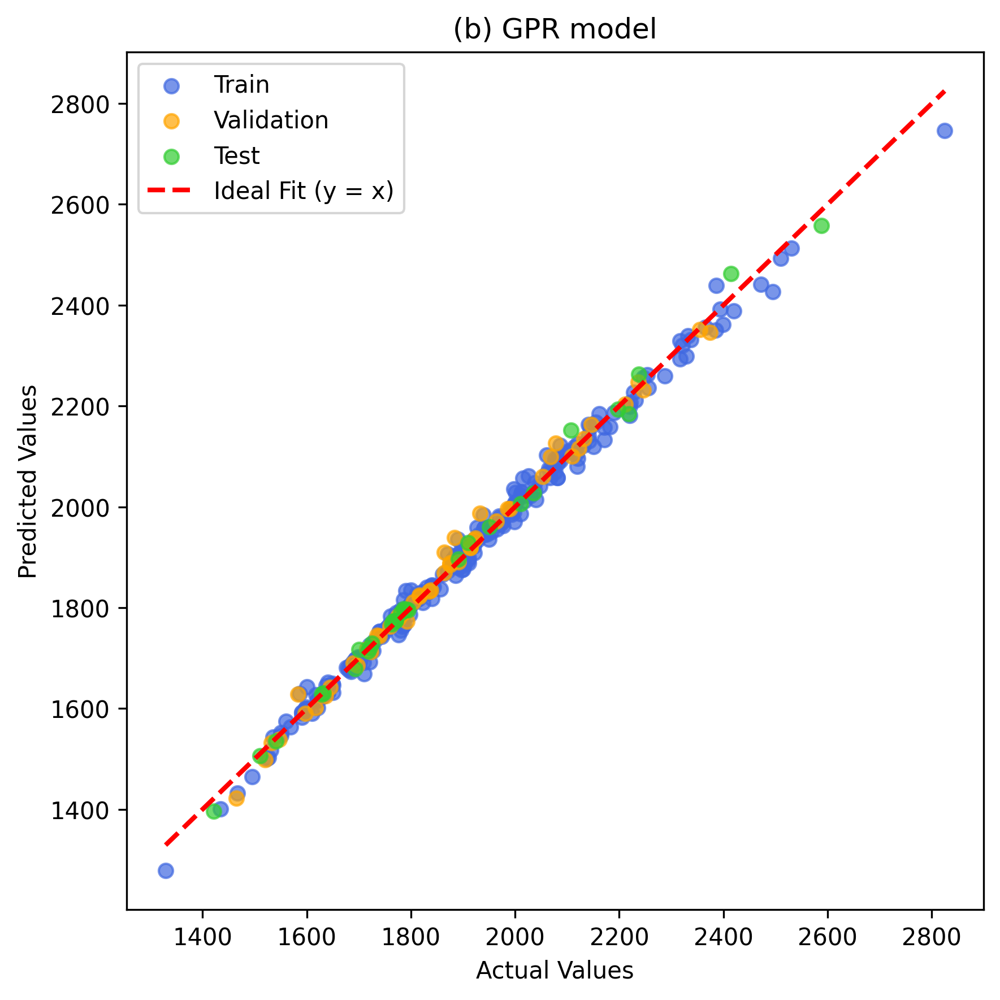

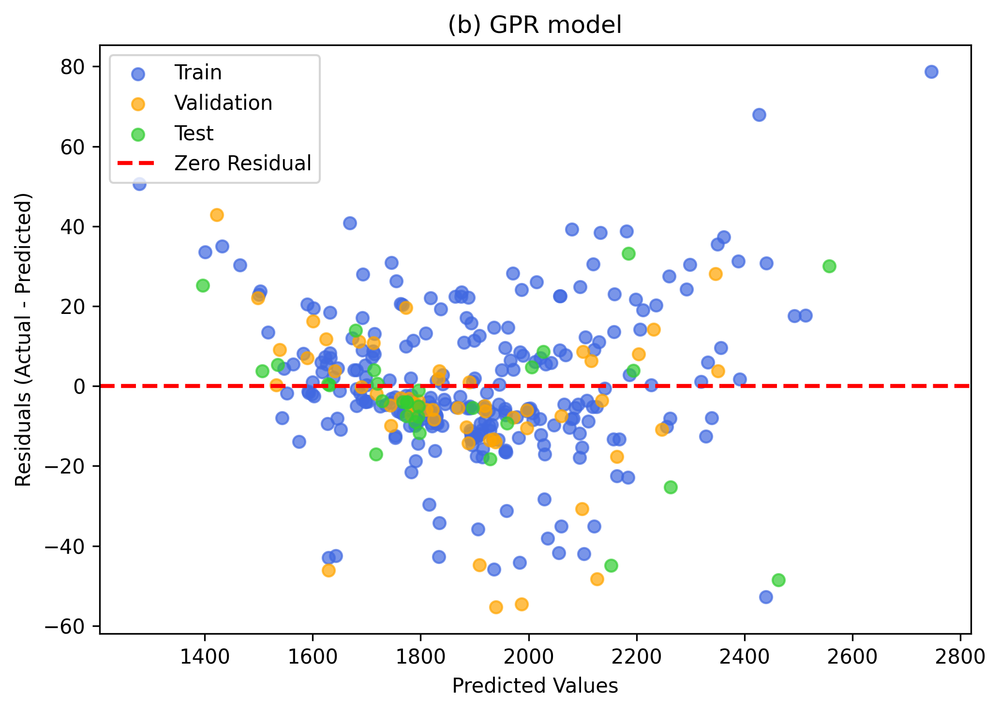

In [ ]:
# Actual vs Predicted (Train / Val / Test)

def plot_combined_predictions(y_true_train, y_pred_train,
                              y_true_val, y_pred_val,
                              y_true_test, y_pred_test):

    y_true_train, y_pred_train = np.ravel(y_true_train), np.ravel(y_pred_train)
    y_true_val,   y_pred_val   = np.ravel(y_true_val),   np.ravel(y_pred_val)
    y_true_test,  y_pred_test  = np.ravel(y_true_test),  np.ravel(y_pred_test)

    plt.figure(figsize=(6,6), dpi=300)
    plt.scatter(y_true_train, y_pred_train, color='royalblue', alpha=0.7, label='Train')
    plt.scatter(y_true_val,   y_pred_val,   color='orange', alpha=0.7, label='Validation')
    plt.scatter(y_true_test,  y_pred_test,  color='limegreen', alpha=0.7, label='Test')


    all_true = np.concatenate([y_true_train, y_true_val, y_true_test])
    plt.plot([all_true.min(), all_true.max()],
             [all_true.min(), all_true.max()], 'r--', lw=2, label='Ideal Fit (y = x)')

    plt.title("(b) GPR model")
    plt.xlabel("Actual Values")
    plt.ylabel("Predicted Values")
    plt.legend()
    plt.grid(False)
    plt.tight_layout()
    plt.show()



# Residuals (Train / Val / Test)

def plot_combined_residuals(y_true_train, y_pred_train,
                            y_true_val, y_pred_val,
                            y_true_test, y_pred_test):
    y_true_train, y_pred_train = np.ravel(y_true_train), np.ravel(y_pred_train)
    y_true_val,   y_pred_val   = np.ravel(y_true_val),   np.ravel(y_pred_val)
    y_true_test,  y_pred_test  = np.ravel(y_true_test),  np.ravel(y_pred_test)

    residuals_train = y_true_train - y_pred_train
    residuals_val   = y_true_val   - y_pred_val
    residuals_test  = y_true_test  - y_pred_test

    plt.figure(figsize=(7,5), dpi=300)
    plt.scatter(y_pred_train, residuals_train, color='royalblue', alpha=0.7, label='Train')
    plt.scatter(y_pred_val,   residuals_val,   color='orange', alpha=0.7, label='Validation')
    plt.scatter(y_pred_test,  residuals_test,  color='limegreen', alpha=0.7, label='Test')

    plt.axhline(0, color='red', linestyle='--', lw=2, label='Zero Residual')
    plt.title("(b) GPR model")
    plt.xlabel("Predicted Values")
    plt.ylabel("Residuals (Actual - Predicted)")
    plt.legend()
    plt.grid(False)
    plt.tight_layout()
    plt.show()

plot_combined_predictions(
    y_true_final_train, y_pred_final_train,
    y_true_final_validation, y_pred_final_validation,
    y_true_test, y_pred_test
)

plot_combined_residuals(
    y_true_final_train, y_pred_final_train,
    y_true_final_validation, y_pred_final_validation,
    y_true_test, y_pred_test
)

RFR model

Running Grid Search ...
Fitting 5 folds for each of 72 candidates, totalling 360 fits
Grid Search took 59.29 seconds.

Best Parameters Found:
   bootstrap: True
   ccp_alpha: 0.0003
   max_depth: 6
   max_features: 0.7
   min_samples_leaf: 3
   min_samples_split: 6
   n_estimators: 100
Best CV MSE = 0.2026

Running 5-Fold Cross Validation with best RF parameters...
 Fold 1: Train R²=0.9111, Val R²=0.6735
 Fold 2: Train R²=0.9053, Val R²=0.7644
 Fold 3: Train R²=0.8991, Val R²=0.7617
 Fold 4: Train R²=0.9012, Val R²=0.8406
 Fold 5: Train R²=0.9032, Val R²=0.8385

Mean Train R²: 0.9040
Mean Val   R²: 0.7757

Generating Learning Curve (Train = full X_temp structure, Val = last fold) ...
  size=  43 | Train RMSE=90.7534 | Val RMSE (last fold)=140.7784
  size=  64 | Train RMSE=68.4371 | Val RMSE (last fold)=126.4248
  size=  86 | Train RMSE=63.7966 | Val RMSE (last fold)=113.6268
  size= 108 | Train RMSE=72.9675 | Val RMSE (last fold)=104.7709
  size= 129 | Train RMSE=71.3002 | Val RMSE (la

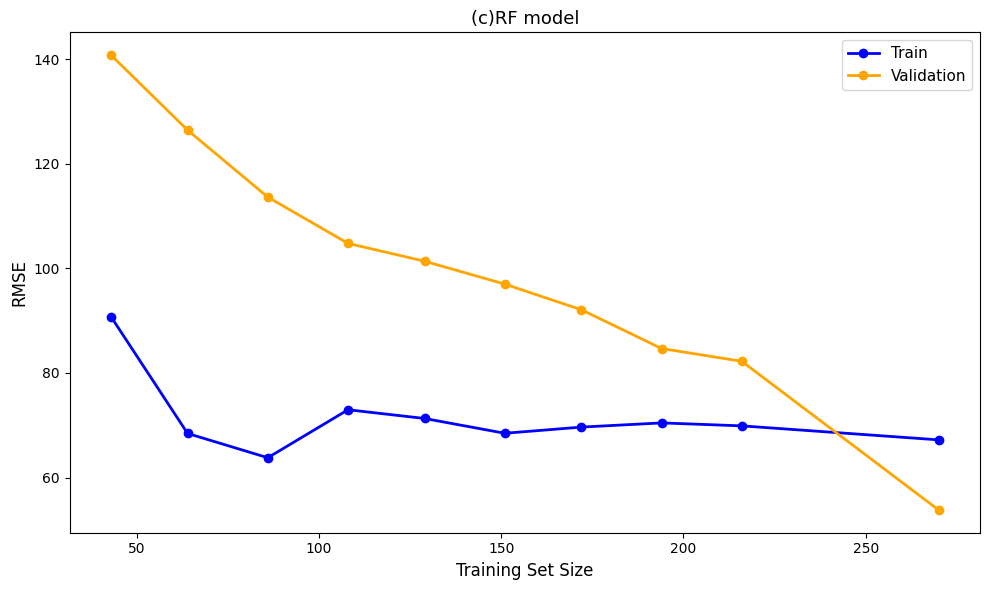


Final Model Training on Full X_temp and Evaluation

Final Train Performance (on all X_temp):
   MSE  = 4875.5060
   MAE  = 50.5229
   RMSE = 69.8248
   R²   = 0.9010

Final Validation Performance
   MSE  = 3091.0923
   MAE  = 43.4499
   RMSE = 55.5976
   R²   = 0.9306

Test Performance:
   MSE  = 9848.5066
   MAE  = 73.8785
   RMSE = 99.2396
   R²   = 0.8553

RFR Computational Cost
Grid Search Time      : 59.2894 s
5-Fold CV Time        : 0.8902 s
test time             : 0.0096s
Final Training Time   : 0.0104 s
Total Training Time   : 60.1900 s
Total Training Time   : 1.0032 min


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import matplotlib.pyplot as plt
import time

# GridSearchCV

rf = RandomForestRegressor(
     random_state=42,
    n_jobs=1
)

param_grid = {
    'n_estimators': [100],
    'max_depth': [2, 4, 6],
    'min_samples_split': [6, 8],
    'min_samples_leaf': [3, 5, 8],
    'max_features': [0.5, 0.7],
    'bootstrap': [True],
    'ccp_alpha': [0.0003, 0.001]
}

X_scaler_grid = StandardScaler()
y_scaler_grid = StandardScaler()

X_temp_scaled_for_grid = X_scaler_grid.fit_transform(X_temp)
y_temp_scaled_for_grid = y_scaler_grid.fit_transform(y_temp)

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    scoring='neg_mean_squared_error',
    cv=5,
    n_jobs=-1,
    verbose=1
)

print("Running Grid Search ...")
start_grid_time = time.perf_counter()
grid_search.fit(X_temp_scaled_for_grid, y_temp_scaled_for_grid.ravel())
end_grid_time = time.perf_counter()
grid_search_time = end_grid_time - start_grid_time
print(f"Grid Search took {grid_search_time:.2f} seconds.")
best_params = grid_search.best_params_
print("\nBest Parameters Found:")
for k, v in best_params.items():
    print(f"   {k}: {v}")
print(f"Best CV MSE = {-grid_search.best_score_:.4f}")

#  5-Fold Cross Validation
start_cv_time = time.perf_counter()
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_results = {"train": [], "val": []}

print("\nRunning 5-Fold Cross Validation with best RF parameters...")

last_fold_data = {}

for fold, (train_idx, val_idx) in enumerate(kf.split(X_temp)):
    X_tr, X_val = X_temp[train_idx], X_temp[val_idx]
    y_tr, y_val = y_temp[train_idx], y_temp[val_idx]

    X_scaler_fold = StandardScaler()
    y_scaler_fold = StandardScaler()

    X_tr_scaled = X_scaler_fold.fit_transform(X_tr)
    y_tr_scaled = y_scaler_fold.fit_transform(y_tr)
    X_val_scaled = X_scaler_fold.transform(X_val)
    y_val_scaled = y_scaler_fold.transform(y_val)

    model_fold = RandomForestRegressor(**best_params)
    model_fold.fit(X_tr_scaled, y_tr_scaled.ravel())

    y_tr_pred = y_scaler_fold.inverse_transform(
        model_fold.predict(X_tr_scaled).reshape(-1, 1)
    )
    y_val_pred = y_scaler_fold.inverse_transform(
        model_fold.predict(X_val_scaled).reshape(-1, 1)
    )
    y_tr_true = y_scaler_fold.inverse_transform(y_tr_scaled)
    y_val_true = y_scaler_fold.inverse_transform(y_val_scaled)

    train_r2 = r2_score(y_tr_true, y_tr_pred)
    val_r2 = r2_score(y_val_true, y_val_pred)

    print(f" Fold {fold+1}: Train R²={train_r2:.4f}, Val R²={val_r2:.4f}")

    cv_results["train"].append(train_r2)
    cv_results["val"].append(val_r2)

    if fold == 4:
        last_fold_data = {
            "X_tr": X_tr,
            "y_tr": y_tr,
            "X_val": X_val,
            "y_val": y_val,
            "train_idx": train_idx,
            "val_idx": val_idx
        }

print(f"\nMean Train R²: {np.mean(cv_results['train']):.4f}")
print(f"Mean Val   R²: {np.mean(cv_results['val']):.4f}")
end_cv_time = time.perf_counter()
cv_time = end_cv_time - start_cv_time
# Learning Curve

print("\nGenerating Learning Curve (Train = full X_temp structure, Val = last fold) ...")

X_val_fixed = last_fold_data["X_val"]
y_val_fixed = last_fold_data["y_val"]

mask = np.ones(len(X_temp), dtype=bool)
mask[last_fold_data["val_idx"]] = False
X_available = X_temp[mask]
y_available = y_temp[mask]

#Train
train_sizes_abs = np.linspace(0.2, 1.0, 9)
train_sizes = (train_sizes_abs * len(X_available)).astype(int)

train_rmse_list = []
val_rmse_list = []

for size in train_sizes:

    rng = np.random.RandomState(42)
    indices = rng.choice(len(X_available), size=size, replace=False)

    X_sub = X_available[indices]
    y_sub = y_available[indices]


    X_scaler = StandardScaler()
    y_scaler = StandardScaler()

    X_sub_scaled = X_scaler.fit_transform(X_sub)
    y_sub_scaled = y_scaler.fit_transform(y_sub)

    X_val_scaled = X_scaler.transform(X_val_fixed)
    y_val_scaled = y_scaler.transform(y_val_fixed)

    model = RandomForestRegressor(**best_params)
    model.fit(X_sub_scaled, y_sub_scaled.ravel())

    # ----- Train RMSE -----
    y_sub_pred = y_scaler.inverse_transform(
        model.predict(X_sub_scaled).reshape(-1, 1)
    )
    train_rmse = np.sqrt(mean_squared_error(y_sub, y_sub_pred))
    train_rmse_list.append(train_rmse)

    # ----- Validation RMSE -----
    y_val_pred = y_scaler.inverse_transform(
        model.predict(X_val_scaled).reshape(-1, 1)
    )
    val_rmse = np.sqrt(mean_squared_error(y_val_fixed, y_val_pred))
    val_rmse_list.append(val_rmse)

    print(f"  size={size:4d} | Train RMSE={train_rmse:.4f} | Val RMSE (last fold)={val_rmse:.4f}")

# ----------X_temp Train ----------
print("\nAdding final point: Full X_temp as Train + Last fold as Validation")

final_X_scaler = StandardScaler()
final_y_scaler = StandardScaler()

X_full_scaled = final_X_scaler.fit_transform(X_temp)
y_full_scaled = final_y_scaler.fit_transform(y_temp)

X_val_final_scaled = final_X_scaler.transform(X_val_fixed)

final_model = RandomForestRegressor(**best_params)
final_model.fit(X_full_scaled, y_full_scaled.ravel())

# Train RMSE X_temp
y_full_pred = final_y_scaler.inverse_transform(
    final_model.predict(X_full_scaled).reshape(-1, 1)
)
final_train_rmse = np.sqrt(mean_squared_error(y_temp, y_full_pred))

# Val RMSE
y_val_final_pred = final_y_scaler.inverse_transform(
    final_model.predict(X_val_final_scaled).reshape(-1, 1)
)
final_val_rmse = np.sqrt(mean_squared_error(y_val_fixed, y_val_final_pred))

print(f"  Full X_temp Train RMSE = {final_train_rmse:.4f}")
print(f"  Last Fold Val   RMSE = {final_val_rmse:.4f}")

train_sizes = np.append(train_sizes, len(X_temp))
train_rmse_list.append(final_train_rmse)
val_rmse_list.append(final_val_rmse)


# رسم Learning Curve با RMSE

plt.figure(figsize=(10, 6))

plt.plot(train_sizes, train_rmse_list, 'o-', color='blue', linewidth=2, label='Train')
plt.plot(train_sizes, val_rmse_list, 'o-', color='orange', linewidth=2, label='Validation')

plt.title('(c)RF model', fontsize=13)
plt.xlabel('Training Set Size', fontsize=12)
plt.ylabel('RMSE', fontsize=12)
plt.legend(loc='best', fontsize=11)
plt.tight_layout()
plt.show()


# Final Model Training & Test Evaluation

print("\n" + "="*60)
print("Final Model Training on Full X_temp and Evaluation")
print("="*60)

# final scalers
final_X_scaler = StandardScaler()
final_y_scaler = StandardScaler()

X_final_train_scaled = final_X_scaler.fit_transform(X_temp)
y_final_train_scaled = final_y_scaler.fit_transform(y_temp)

X_test_scaled = final_X_scaler.transform(X_test)
y_test_scaled = final_y_scaler.transform(y_test)

final_rf_model = RandomForestRegressor(**best_params,
    random_state=42,
    n_jobs=1
                                       )
final_rf_model.fit(X_final_train_scaled, y_final_train_scaled.ravel())

# ----- Final Train (X_temp) -----
start_train_time = time.perf_counter()
y_pred_final_train = final_y_scaler.inverse_transform(
    final_rf_model.predict(X_final_train_scaled).reshape(-1, 1)
)
end_train_time = time.perf_counter()
train_time = end_train_time - start_train_time
y_true_final_train = final_y_scaler.inverse_transform(y_final_train_scaled)

mse_final_train = mean_squared_error(y_true_final_train, y_pred_final_train)
mae_final_train = mean_absolute_error(y_true_final_train, y_pred_final_train)
rmse_final_train = np.sqrt(mse_final_train)
r2_final_train = r2_score(y_true_final_train, y_pred_final_train)

print(f"\nFinal Train Performance (on all X_temp):")
print(f"   MSE  = {mse_final_train:.4f}")
print(f"   MAE  = {mae_final_train:.4f}")
print(f"   RMSE = {rmse_final_train:.4f}")
print(f"   R²   = {r2_final_train:.4f}")

# ----- Validation -----
X_val_last_scaled = final_X_scaler.transform(last_fold_data["X_val"])
y_pred_last_val = final_y_scaler.inverse_transform(
    final_rf_model.predict(X_val_last_scaled).reshape(-1, 1)
)
y_true_last_val = last_fold_data["y_val"]

mse_last_val = mean_squared_error(y_true_last_val, y_pred_last_val)
mae_last_val = mean_absolute_error(y_true_last_val, y_pred_last_val)
rmse_last_val = np.sqrt(mse_last_val)
r2_last_val = r2_score(y_true_last_val, y_pred_last_val)

print(f"\nFinal Validation Performance")
print(f"   MSE  = {mse_last_val:.4f}")
print(f"   MAE  = {mae_last_val:.4f}")
print(f"   RMSE = {rmse_last_val:.4f}")
print(f"   R²   = {r2_last_val:.4f}")

# ----- Test -----
start_test_time = time.perf_counter()
y_pred_test = final_y_scaler.inverse_transform(
    final_rf_model.predict(X_test_scaled).reshape(-1, 1)
)
end_test_time = time.perf_counter()
test_time = end_test_time - start_test_time
y_true_test = final_y_scaler.inverse_transform(y_test_scaled)

mse_test = mean_squared_error(y_true_test, y_pred_test)
mae_test = mean_absolute_error(y_true_test, y_pred_test)
rmse_test = np.sqrt(mse_test)
r2_test = r2_score(y_true_test, y_pred_test)

print(f"\nTest Performance:")
print(f"   MSE  = {mse_test:.4f}")
print(f"   MAE  = {mae_test:.4f}")
print(f"   RMSE = {rmse_test:.4f}")
print(f"   R²   = {r2_test:.4f}")

total_time = (
    grid_search_time +
    cv_time +
    train_time
)

print("\n===================================")
print("RFR Computational Cost")
print("===================================")

print(f"Grid Search Time      : {grid_search_time:.4f} s")
print(f"5-Fold CV Time        : {cv_time:.4f} s")
print(f"test time             : {test_time:.4f}s" )
print(f"Final Training Time   : {train_time:.4f} s")
print(f"Total Training Time   : {total_time:.4f} s")
print(f"Total Training Time   : {total_time/60:.4f} min")

 Actual vs Predicted and Residuals plot of RF

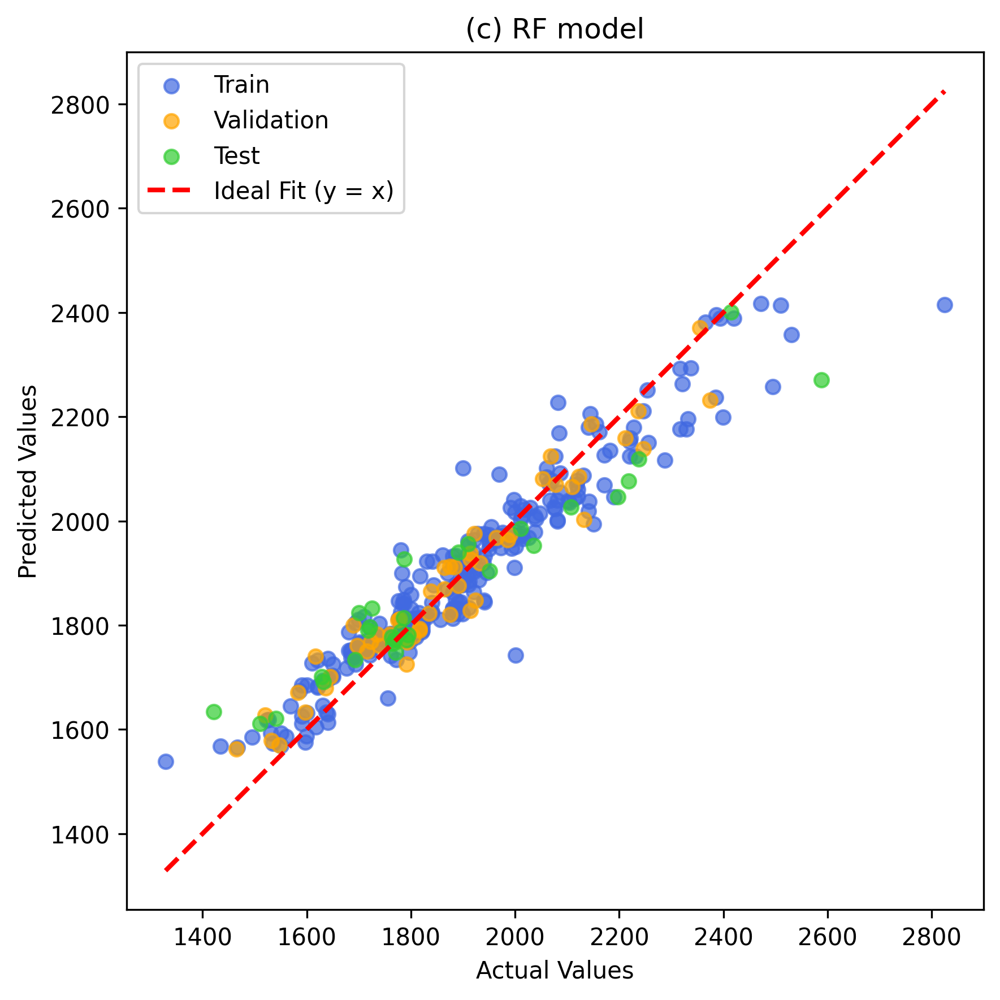

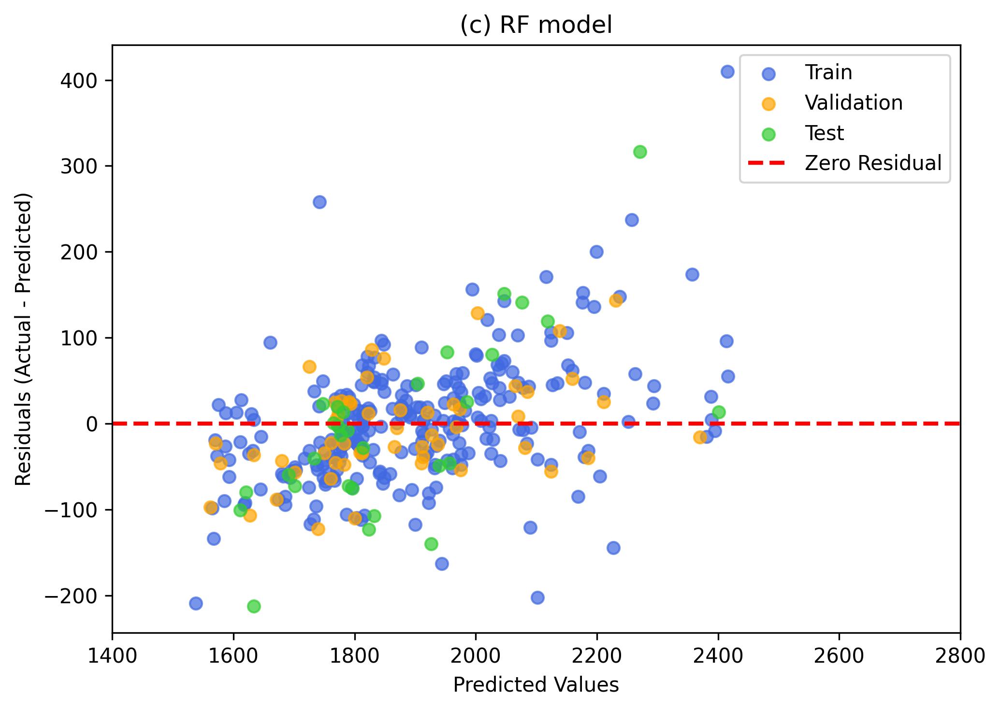

In [ ]:
# Actual vs Predicted (Train / Val / Test)

def plot_combined_predictions(y_true_train, y_pred_train,
                              y_true_val, y_pred_val,
                              y_true_test, y_pred_test):

    y_true_train, y_pred_train = np.ravel(y_true_train), np.ravel(y_pred_train)
    y_true_val,   y_pred_val   = np.ravel(y_true_val),   np.ravel(y_pred_val)
    y_true_test,  y_pred_test  = np.ravel(y_true_test),  np.ravel(y_pred_test)

    plt.figure(figsize=(6,6),dpi=300)
    plt.scatter(y_true_train, y_pred_train, color='royalblue', alpha=0.7, label='Train')
    plt.scatter(y_true_val,   y_pred_val,   color='orange', alpha=0.7, label='Validation')
    plt.scatter(y_true_test,  y_pred_test,  color='limegreen', alpha=0.7, label='Test')


    all_true = np.concatenate([y_true_train, y_true_val, y_true_test])
    plt.plot([all_true.min(), all_true.max()],
             [all_true.min(), all_true.max()], 'r--', lw=2, label='Ideal Fit (y = x)')

    plt.title("(c) RF model")
    plt.xlabel("Actual Values")
    plt.ylabel("Predicted Values")
    plt.legend()
    plt.grid(False)
    plt.tight_layout()
    plt.show()



# Residuals (Train / Val / Test)

def plot_combined_residuals(y_true_train, y_pred_train,
                            y_true_val, y_pred_val,
                            y_true_test, y_pred_test):
    y_true_train, y_pred_train = np.ravel(y_true_train), np.ravel(y_pred_train)
    y_true_val,   y_pred_val   = np.ravel(y_true_val),   np.ravel(y_pred_val)
    y_true_test,  y_pred_test  = np.ravel(y_true_test),  np.ravel(y_pred_test)

    residuals_train = y_true_train - y_pred_train
    residuals_val   = y_true_val   - y_pred_val
    residuals_test  = y_true_test  - y_pred_test

    plt.figure(figsize=(7,5),dpi=300)
    plt.scatter(y_pred_train, residuals_train, color='royalblue', alpha=0.7, label='Train')
    plt.scatter(y_pred_val,   residuals_val,   color='orange', alpha=0.7, label='Validation')
    plt.scatter(y_pred_test,  residuals_test,  color='limegreen', alpha=0.7, label='Test')
    plt.xlim(1400, 2800)
    plt.axhline(0, color='red', linestyle='--', lw=2, label='Zero Residual')
    plt.title("(c) RF model")
    plt.xlabel("Predicted Values")
    plt.ylabel("Residuals (Actual - Predicted)")
    plt.legend()
    plt.grid(False)
    plt.tight_layout()
    plt.show()

plot_combined_predictions(
    y_true_final_train, y_pred_final_train,
    y_true_final_validation, y_pred_final_validation,
    y_true_test, y_pred_test
)

plot_combined_residuals(
    y_true_final_train, y_pred_final_train,
    y_true_final_validation, y_pred_final_validation,
    y_true_test, y_pred_test
)

SHAP PLOT

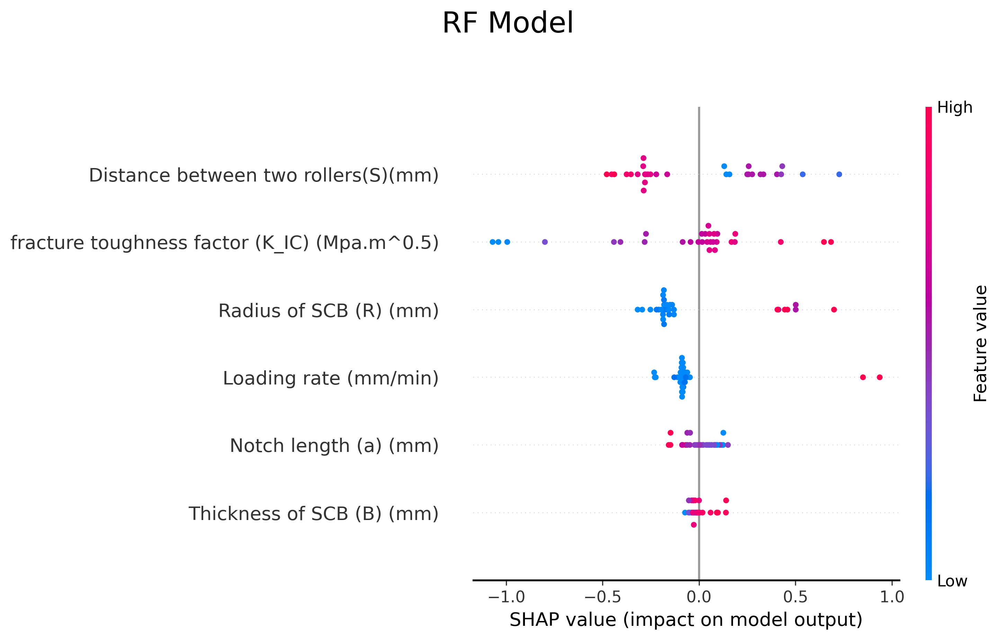

In [ ]:
import matplotlib.pyplot as plt
import shap

# ---------------- Paper Settings ----------------
plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 18,
    "axes.labelsize": 16,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "figure.dpi": 300,
    "savefig.dpi": 300,
    "axes.linewidth": 1.3
})

# Feature names
feature_names = df_c.drop(columns=["maximum loading pressure of SCB (Pmax) (N)"]).columns.tolist()

shap.initjs()

# SHAP explainer
explainer = shap.TreeExplainer(final_rf_model)
shap_values = explainer.shap_values(X_test_scaled)

# ---------------- SHAP PLOT ----------------
plt.figure(figsize=(12, 8))
plt.suptitle("RF Model", fontsize=20, y=1.03)

shap.summary_plot(
    shap_values,
    X_test_scaled,
    feature_names=feature_names,
    show=False,
    plot_size=(10, 6)
)

plt.savefig("RF_SHAP_SUMMARY.png", bbox_inches="tight")
plt.show()


XGB model

Running Grid Search ...
Fitting 5 folds for each of 27 candidates, totalling 135 fits


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



Best Parameters Found:
   colsample_bytree: 0.4
   learning_rate: 0.15
   max_depth: 3
   min_child_weight: 3
   n_estimators: 150
   reg_alpha: 0
   reg_lambda: 2
   subsample: 0.8
Best CV MSE = 0.0650

Running 5-Fold Cross Validation with best XGB parameters...
 Fold 1: Train R²=0.9930, Val R²=0.8984
 Fold 2: Train R²=0.9935, Val R²=0.8914
 Fold 3: Train R²=0.9938, Val R²=0.9105
 Fold 4: Train R²=0.9928, Val R²=0.9379
 Fold 5: Train R²=0.9921, Val R²=0.9476

Mean Train R²: 0.9930
Mean Val   R²: 0.9172

Generating Learning Curve (Correct Method)...


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


  size=  43 | Train RMSE=12.3130 | Val RMSE=113.1464
  size=  64 | Train RMSE=12.8422 | Val RMSE=104.1068
  size=  86 | Train RMSE=11.9080 | Val RMSE=93.2702
  size= 108 | Train RMSE=15.5553 | Val RMSE=67.9228
  size= 129 | Train RMSE=17.1179 | Val RMSE=62.7401
  size= 151 | Train RMSE=18.5506 | Val RMSE=65.3923
  size= 172 | Train RMSE=17.8488 | Val RMSE=51.8057


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


  size= 194 | Train RMSE=19.5558 | Val RMSE=50.0629
  size= 216 | Train RMSE=20.1426 | Val RMSE=49.7823

Adding final point: Full X_temp as Train + Last fold as Validation
  Full X_temp Train RMSE = 19.2847
  Last Fold Val   RMSE = 16.5011


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


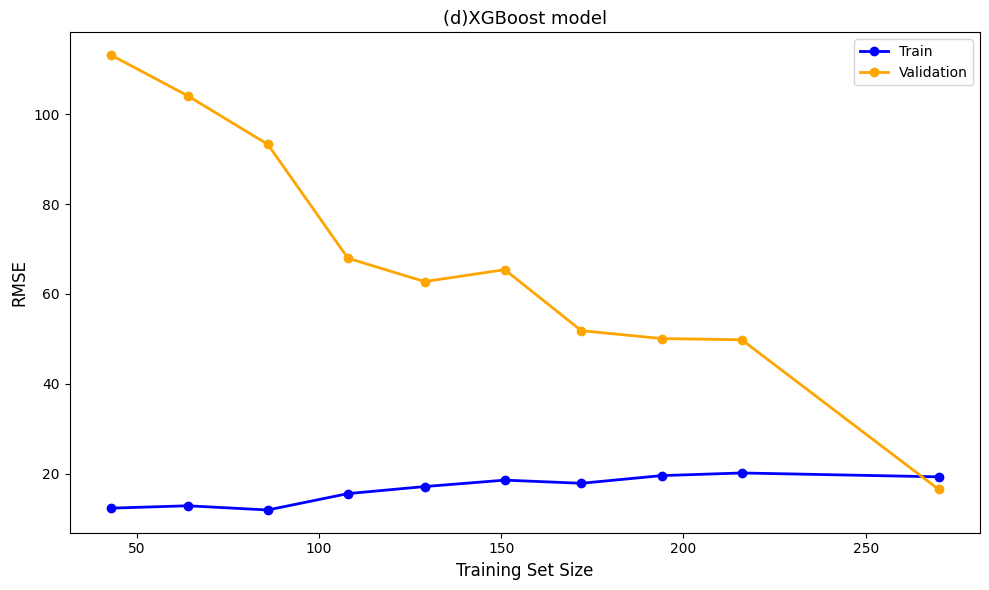


Final Evaluation (Correct Method)

Final Train Performance (on all X_temp):
   MSE  = 371.8985
   MAE  = 14.5213
   RMSE = 19.2847
   R²   = 0.9924

Final Validation Performance (Last Fold - Correct):
   MSE  = 272.2850
   MAE  = 12.8799
   RMSE = 16.5011
   R²   = 0.9939

Test Performance:
   MSE  = 3081.2044
   MAE  = 40.5662
   RMSE = 55.5086
   R²   = 0.9547

XGB Computational Cost
Grid Search Time      : 8.1343 s
5-Fold CV Time        : 0.1773 s
Final Training Time   : 0.0300 s
Test Prediction Time  : 0.0009 s
Total Training Time   : 8.3416 s
Total Training Time   : 0.1390 min


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. GridSearchCV
# ============================================================
xgb = XGBRegressor(random_state=42)

param_grid = {
    'n_estimators': [50, 100, 150],
    'learning_rate': [0.05, 0.1, 0.15],
    'max_depth': [3, 4, 5],
    'subsample': [0.8],
    'colsample_bytree': [0.4],
    'reg_alpha': [0],
    'reg_lambda': [2],
    'min_child_weight': [3],
}

X_scaler_grid = StandardScaler()
y_scaler_grid = StandardScaler()

X_temp_scaled_for_grid = X_scaler_grid.fit_transform(X_temp)
y_temp_scaled_for_grid = y_scaler_grid.fit_transform(y_temp)

start_grid_time = time.perf_counter()
grid_search = GridSearchCV(
    estimator=xgb,
    param_grid=param_grid,
    scoring='neg_mean_squared_error',
    cv=5,
    n_jobs=-1,
    verbose=1
)

print("Running Grid Search ...")
grid_search.fit(X_temp_scaled_for_grid, y_temp_scaled_for_grid.ravel())
end_grid_time = time.perf_counter()
grid_search_time = end_grid_time - start_grid_time

best_params = grid_search.best_params_
print("\nBest Parameters Found:")
for k, v in best_params.items():
    print(f"   {k}: {v}")
print(f"Best CV MSE = {-grid_search.best_score_:.4f}")

# ============================================================
# 2. 5-Fold Cross Validation
# ============================================================
start_cv_time = time.perf_counter()
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_results = {"train": [], "val": []}

print("\nRunning 5-Fold Cross Validation with best XGB parameters...")

last_fold_data = {}

for fold, (train_idx, val_idx) in enumerate(kf.split(X_temp)):
    X_tr, X_val = X_temp[train_idx], X_temp[val_idx]
    y_tr, y_val = y_temp[train_idx], y_temp[val_idx]

    X_scaler_fold = StandardScaler()
    y_scaler_fold = StandardScaler()

    X_tr_scaled = X_scaler_fold.fit_transform(X_tr)
    y_tr_scaled = y_scaler_fold.fit_transform(y_tr)
    X_val_scaled = X_scaler_fold.transform(X_val)
    y_val_scaled = y_scaler_fold.transform(y_val)

    model_fold = XGBRegressor(**best_params, random_state=42)
    model_fold.fit(X_tr_scaled, y_tr_scaled.ravel())

    y_tr_pred = y_scaler_fold.inverse_transform(
        model_fold.predict(X_tr_scaled).reshape(-1, 1)
    )
    y_val_pred = y_scaler_fold.inverse_transform(
        model_fold.predict(X_val_scaled).reshape(-1, 1)
    )
    y_tr_true = y_scaler_fold.inverse_transform(y_tr_scaled)
    y_val_true = y_scaler_fold.inverse_transform(y_val_scaled)

    train_r2 = r2_score(y_tr_true, y_tr_pred)
    val_r2 = r2_score(y_val_true, y_val_pred)

    print(f" Fold {fold+1}: Train R²={train_r2:.4f}, Val R²={val_r2:.4f}")

    cv_results["train"].append(train_r2)
    cv_results["val"].append(val_r2)

    # ذخیره آخرین فولد
    if fold == 4:
        last_fold_data = {
            "X_val": X_val,
            "y_val": y_val,
            "val_idx": val_idx
        }

print(f"\nMean Train R²: {np.mean(cv_results['train']):.4f}")
print(f"Mean Val   R²: {np.mean(cv_results['val']):.4f}")
end_cv_time = time.perf_counter()
cv_time = end_cv_time - start_cv_time
# ============================================================
# 3. Learning Curve (روش صحیح)
#    - Validation همیشه = آخرین فولد (ثابت)
#    - Train نهایی = کل X_temp
#    - معیار = RMSE
# ============================================================
print("\nGenerating Learning Curve (Correct Method)...")

X_val_fixed = last_fold_data["X_val"]
y_val_fixed = last_fold_data["y_val"]

# داده‌های قابل استفاده برای Train = کل داده‌ها منهای validation آخرین فولد
mask = np.ones(len(X_temp), dtype=bool)
mask[last_fold_data["val_idx"]] = False
X_available = X_temp[mask]
y_available = y_temp[mask]

train_sizes_abs = np.linspace(0.2, 1.0, 9)
train_sizes = (train_sizes_abs * len(X_available)).astype(int)

train_rmse_list = []
val_rmse_list = []

for size in train_sizes:
    rng = np.random.RandomState(42)
    indices = rng.choice(len(X_available), size=size, replace=False)

    X_sub = X_available[indices]
    y_sub = y_available[indices]

    X_scaler = StandardScaler()
    y_scaler = StandardScaler()

    X_sub_scaled = X_scaler.fit_transform(X_sub)
    y_sub_scaled = y_scaler.fit_transform(y_sub)

    X_val_scaled = X_scaler.transform(X_val_fixed)

    model = XGBRegressor(**best_params, random_state=42)
    model.fit(X_sub_scaled, y_sub_scaled.ravel())

    # Train RMSE
    y_sub_pred = y_scaler.inverse_transform(
        model.predict(X_sub_scaled).reshape(-1, 1)
    )
    train_rmse = np.sqrt(mean_squared_error(y_sub, y_sub_pred))
    train_rmse_list.append(train_rmse)

    # Validation RMSE (همیشه آخرین فولد - با اسکیلر صحیح)
    y_val_pred = y_scaler.inverse_transform(
        model.predict(X_val_scaled).reshape(-1, 1)
    )
    val_rmse = np.sqrt(mean_squared_error(y_val_fixed, y_val_pred))
    val_rmse_list.append(val_rmse)

    print(f"  size={size:4d} | Train RMSE={train_rmse:.4f} | Val RMSE={val_rmse:.4f}")

# ---------- نقطه نهایی: کل X_temp ----------
print("\nAdding final point: Full X_temp as Train + Last fold as Validation")

final_X_scaler = StandardScaler()
final_y_scaler = StandardScaler()

X_full_scaled = final_X_scaler.fit_transform(X_temp)
y_full_scaled = final_y_scaler.fit_transform(y_temp)

X_val_final_scaled = final_X_scaler.transform(X_val_fixed)

final_model = XGBRegressor(**best_params, random_state=42)
final_model.fit(X_full_scaled, y_full_scaled.ravel())

# Train RMSE روی کل X_temp
y_full_pred = final_y_scaler.inverse_transform(
    final_model.predict(X_full_scaled).reshape(-1, 1)
)
final_train_rmse = np.sqrt(mean_squared_error(y_temp, y_full_pred))

# Val RMSE
y_val_final_pred = final_y_scaler.inverse_transform(
    final_model.predict(X_val_final_scaled).reshape(-1, 1)
)
final_val_rmse = np.sqrt(mean_squared_error(y_val_fixed, y_val_final_pred))

print(f"  Full X_temp Train RMSE = {final_train_rmse:.4f}")
print(f"  Last Fold Val   RMSE = {final_val_rmse:.4f}")

train_sizes = np.append(train_sizes, len(X_temp))
train_rmse_list.append(final_train_rmse)
val_rmse_list.append(final_val_rmse)

# ============================================================
# رسم Learning Curve
# ============================================================
plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_rmse_list, 'o-', color='blue', linewidth=2, label='Train')
plt.plot(train_sizes, val_rmse_list, 'o-', color='orange', linewidth=2, label='Validation')
plt.title('(d)XGBoost model', fontsize=13)
plt.xlabel('Training Set Size', fontsize=12)
plt.ylabel('RMSE', fontsize=12)
plt.legend(loc='best')
plt.tight_layout()
plt.show()


# ============================================================
# Final Evaluation
# ============================================================
print("\n" + "="*60)
print("Final Evaluation (Correct Method)")
print("="*60)

final_X_scaler = StandardScaler()
final_y_scaler = StandardScaler()

X_final_train_scaled = final_X_scaler.fit_transform(X_temp)
y_final_train_scaled = final_y_scaler.fit_transform(y_temp)

X_test_scaled = final_X_scaler.transform(X_test)
y_test_scaled = final_y_scaler.transform(y_test)

# ----- Final Training (زمان واقعی آموزش) -----
start_train_time = time.perf_counter()
final_xgb_model = XGBRegressor(**best_params, random_state=42)
final_xgb_model.fit(X_final_train_scaled, y_final_train_scaled.ravel())
end_train_time = time.perf_counter()
train_time = end_train_time - start_train_time

# ----- Final Train Performance -----
y_pred_final_train = final_y_scaler.inverse_transform(
    final_xgb_model.predict(X_final_train_scaled).reshape(-1, 1)
)
y_true_final_train = final_y_scaler.inverse_transform(y_final_train_scaled)

mse_final_train = mean_squared_error(y_true_final_train, y_pred_final_train)
mae_final_train = mean_absolute_error(y_true_final_train, y_pred_final_train)
rmse_final_train = np.sqrt(mse_final_train)
r2_final_train = r2_score(y_true_final_train, y_pred_final_train)

print(f"\nFinal Train Performance (on all X_temp):")
print(f"   MSE  = {mse_final_train:.4f}")
print(f"   MAE  = {mae_final_train:.4f}")
print(f"   RMSE = {rmse_final_train:.4f}")
print(f"   R²   = {r2_final_train:.4f}")

# ----- Validation = آخرین فولد -----
X_val_last_scaled = final_X_scaler.transform(last_fold_data["X_val"])
y_pred_last_val = final_y_scaler.inverse_transform(
    final_xgb_model.predict(X_val_last_scaled).reshape(-1, 1)
)
y_true_last_val = last_fold_data["y_val"]

mse_last_val = mean_squared_error(y_true_last_val, y_pred_last_val)
mae_last_val = mean_absolute_error(y_true_last_val, y_pred_last_val)
rmse_last_val = np.sqrt(mse_last_val)
r2_last_val = r2_score(y_true_last_val, y_pred_last_val)

print(f"\nFinal Validation Performance (Last Fold - Correct):")
print(f"   MSE  = {mse_last_val:.4f}")
print(f"   MAE  = {mae_last_val:.4f}")
print(f"   RMSE = {rmse_last_val:.4f}")
print(f"   R²   = {r2_last_val:.4f}")

# ----- Test -----
start_test_time = time.perf_counter()
y_pred_test = final_y_scaler.inverse_transform(
    final_xgb_model.predict(X_test_scaled).reshape(-1, 1)
)
end_test_time = time.perf_counter()
test_time = end_test_time - start_test_time

y_true_test = final_y_scaler.inverse_transform(y_test_scaled)

mse_test = mean_squared_error(y_true_test, y_pred_test)
mae_test = mean_absolute_error(y_true_test, y_pred_test)
rmse_test = np.sqrt(mse_test)
r2_test = r2_score(y_true_test, y_pred_test)

print(f"\nTest Performance:")
print(f"   MSE  = {mse_test:.4f}")
print(f"   MAE  = {mae_test:.4f}")
print(f"   RMSE = {rmse_test:.4f}")
print(f"   R²   = {r2_test:.4f}")

# ----- محاسبه زمان کل -----
total_time = grid_search_time + cv_time + train_time

print("\n===================================")
print("XGB Computational Cost")
print("===================================")
print(f"Grid Search Time      : {grid_search_time:.4f} s")
print(f"5-Fold CV Time        : {cv_time:.4f} s")
print(f"Final Training Time   : {train_time:.4f} s")
print(f"Test Prediction Time  : {test_time:.4f} s")
print(f"Total Training Time   : {total_time:.4f} s")
print(f"Total Training Time   : {total_time/60:.4f} min")

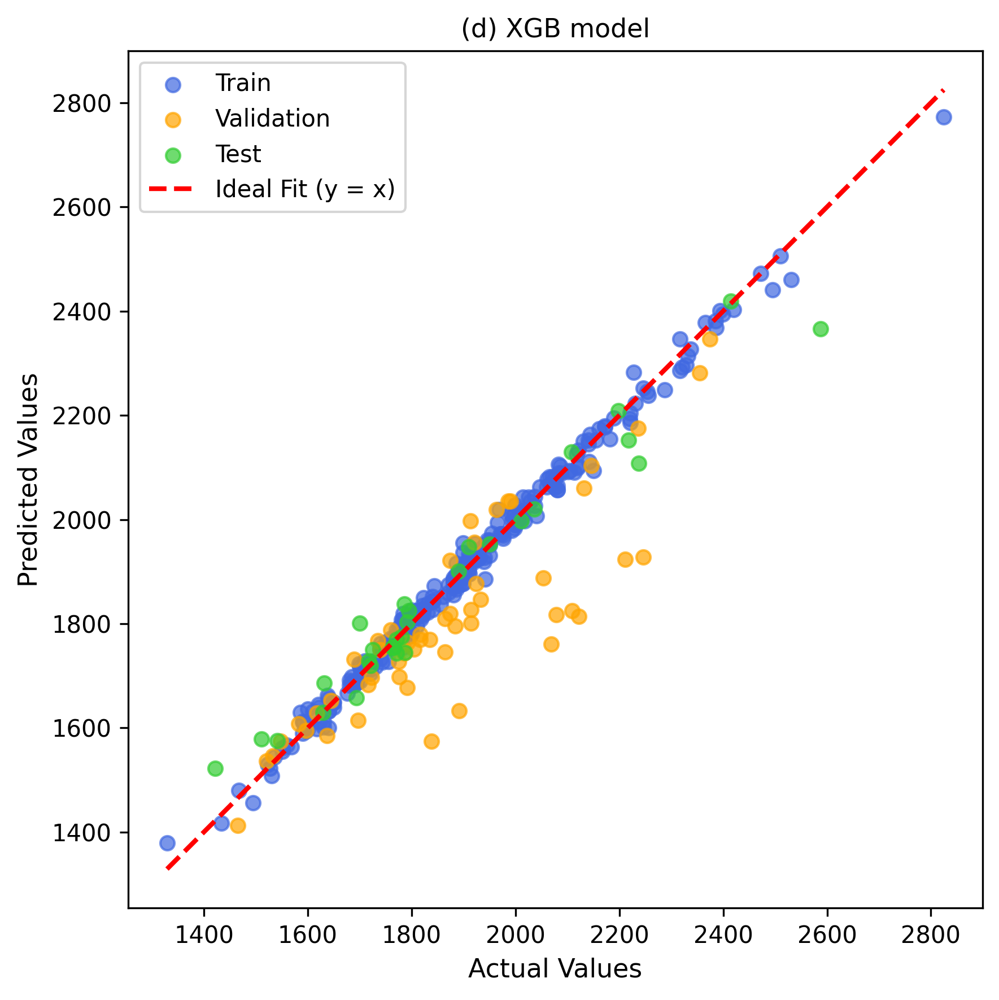

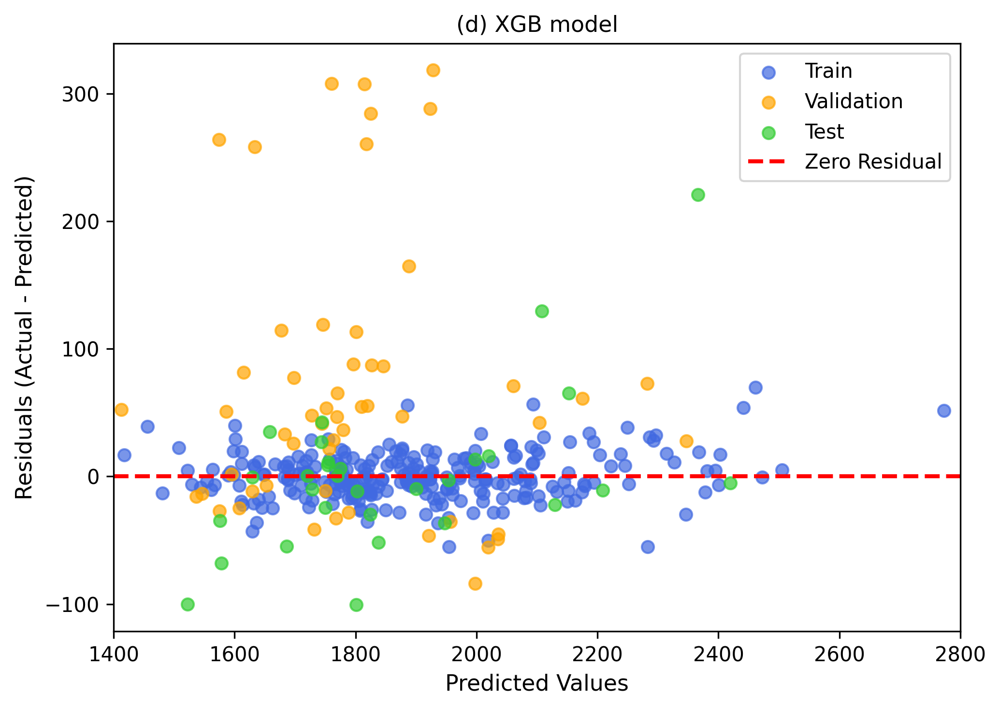

In [ ]:
# Actual vs Predicted (Train / Val / Test)

def plot_combined_predictions(y_true_train, y_pred_train,
                              y_true_val, y_pred_val,
                              y_true_test, y_pred_test):

    y_true_train, y_pred_train = np.ravel(y_true_train), np.ravel(y_pred_train)
    y_true_val,   y_pred_val   = np.ravel(y_true_val),   np.ravel(y_pred_val)
    y_true_test,  y_pred_test  = np.ravel(y_true_test),  np.ravel(y_pred_test)

    plt.figure(figsize=(6,6),dpi=300)
    plt.scatter(y_true_train, y_pred_train, color='royalblue', alpha=0.7, label='Train')
    plt.scatter(y_true_val,   y_pred_val,   color='orange', alpha=0.7, label='Validation')
    plt.scatter(y_true_test,  y_pred_test,  color='limegreen', alpha=0.7, label='Test')


    all_true = np.concatenate([y_true_train, y_true_val, y_true_test])
    plt.plot([all_true.min(), all_true.max()],
             [all_true.min(), all_true.max()], 'r--', lw=2, label='Ideal Fit (y = x)')

    plt.title("(d) XGB model")
    plt.xlabel("Actual Values")
    plt.ylabel("Predicted Values")
    plt.legend()
    plt.grid(False)
    plt.tight_layout()
    plt.show()



# Residuals (Train / Val / Test)

def plot_combined_residuals(y_true_train, y_pred_train,
                            y_true_val, y_pred_val,
                            y_true_test, y_pred_test):
    y_true_train, y_pred_train = np.ravel(y_true_train), np.ravel(y_pred_train)
    y_true_val,   y_pred_val   = np.ravel(y_true_val),   np.ravel(y_pred_val)
    y_true_test,  y_pred_test  = np.ravel(y_true_test),  np.ravel(y_pred_test)

    residuals_train = y_true_train - y_pred_train
    residuals_val   = y_true_val   - y_pred_val
    residuals_test  = y_true_test  - y_pred_test

    plt.figure(figsize=(7,5),dpi=300)
    plt.scatter(y_pred_train, residuals_train, color='royalblue', alpha=0.7, label='Train')
    plt.scatter(y_pred_val,   residuals_val,   color='orange', alpha=0.7, label='Validation')
    plt.scatter(y_pred_test,  residuals_test,  color='limegreen', alpha=0.7, label='Test')
    plt.xlim(1400, 2800)
    plt.axhline(0, color='red', linestyle='--', lw=2, label='Zero Residual')
    plt.title("(d) XGB model")
    plt.xlabel("Predicted Values")
    plt.ylabel("Residuals (Actual - Predicted)")
    plt.legend()
    plt.grid(False)
    plt.tight_layout()
    plt.show()

plot_combined_predictions(
    y_true_final_train, y_pred_final_train,
    y_true_final_validation, y_pred_final_validation,
    y_true_test, y_pred_test
)

plot_combined_residuals(
    y_true_final_train, y_pred_final_train,
    y_true_final_validation, y_pred_final_validation,
    y_true_test, y_pred_test
)

SHAP PLOT

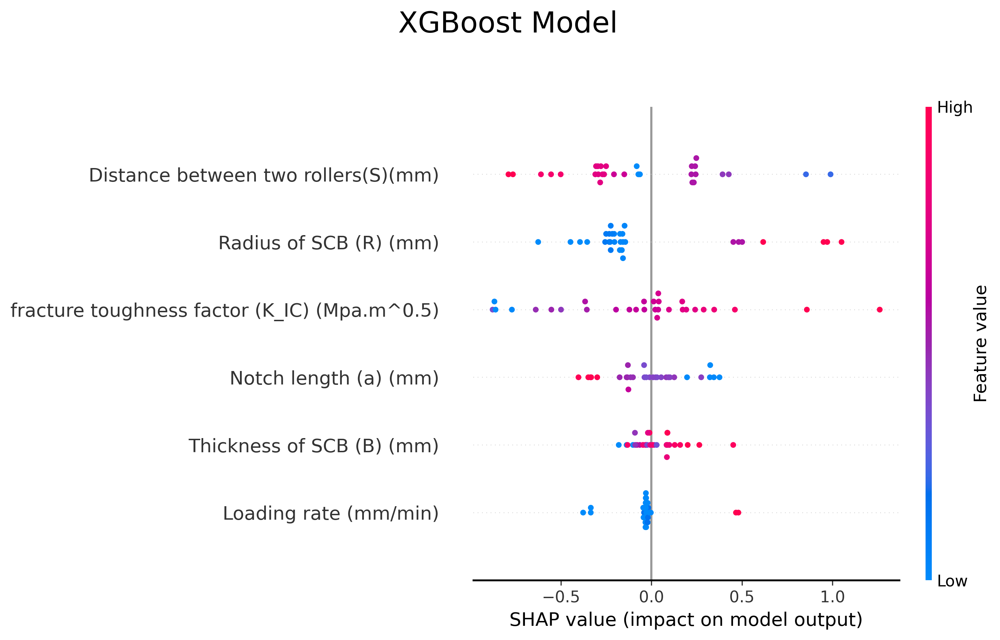

In [ ]:
import matplotlib.pyplot as plt
import shap

# ---------------- Paper Settings ----------------
plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 18,
    "axes.labelsize": 16,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "figure.dpi": 300,
    "savefig.dpi": 300,
    "axes.linewidth": 1.3
})


# Feature names - Moved here to ensure it's defined
feature_names = df_c.drop(columns=["maximum loading pressure of SCB (Pmax) (N)"]).columns.tolist()

shap.initjs()

# SHAP explainer for XGBoost model
explainer_xgb = shap.TreeExplainer(final_xgb_model)
shap_values_xgb = explainer_xgb.shap_values(X_test_scaled)

# ---------------- SHAP PLOT ----------------
plt.figure(figsize=(12, 8))
plt.suptitle("XGBoost Model", fontsize=20, y=1.03) # Common title

shap.summary_plot(
    shap_values_xgb,
    X_test_scaled,
    feature_names=feature_names,
    show=False,
    plot_size=(10, 6)
)

plt.savefig("XGB_SHAP_SUMMARY.png", bbox_inches="tight")
plt.show()

MLP model

Running Grid Search with 5-Fold CV
   layers=[5], lr=0.001, alpha=1e-05 → RMSE=119.703
   layers=[5], lr=0.001, alpha=0.0001 → RMSE=151.253
   layers=[5], lr=0.01, alpha=1e-05 → RMSE=33.172
   layers=[5], lr=0.01, alpha=0.0001 → RMSE=32.220
   layers=[10], lr=0.001, alpha=1e-05 → RMSE=87.267
   layers=[10], lr=0.001, alpha=0.0001 → RMSE=68.062
   layers=[10], lr=0.01, alpha=1e-05 → RMSE=19.815
   layers=[10], lr=0.01, alpha=0.0001 → RMSE=19.826
   layers=[10, 5], lr=0.001, alpha=1e-05 → RMSE=72.564
   layers=[10, 5], lr=0.001, alpha=0.0001 → RMSE=68.464
   layers=[10, 5], lr=0.01, alpha=1e-05 → RMSE=21.636
   layers=[10, 5], lr=0.01, alpha=0.0001 → RMSE=18.722
   layers=[5, 5], lr=0.001, alpha=1e-05 → RMSE=80.526
   layers=[5, 5], lr=0.001, alpha=0.0001 → RMSE=102.336
   layers=[5, 5], lr=0.01, alpha=1e-05 → RMSE=26.145
   layers=[5, 5], lr=0.01, alpha=0.0001 → RMSE=23.656
   layers=[5, 10], lr=0.001, alpha=1e-05 → RMSE=70.623
   layers=[5, 10], lr=0.001, alpha=0.0001 → RMSE=87.413
   

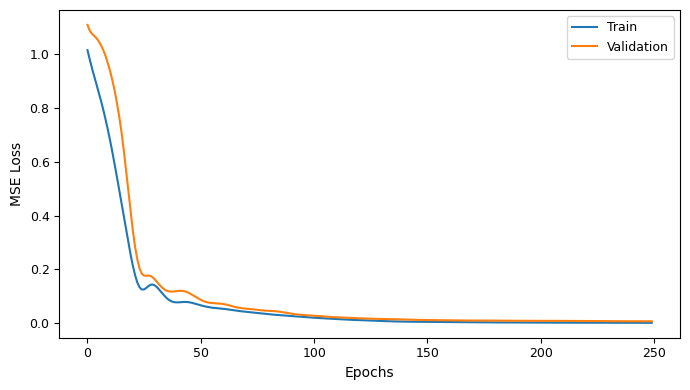


Generating Learning Curve vs Training Set Size ...
  size=  48 | Train RMSE=6.1891 | Val RMSE=53.4781
  size=  74 | Train RMSE=4.9718 | Val RMSE=35.4333
  size= 100 | Train RMSE=5.6444 | Val RMSE=38.9879
  size= 126 | Train RMSE=8.3481 | Val RMSE=33.1286
  size= 152 | Train RMSE=8.1666 | Val RMSE=20.5395
  size= 178 | Train RMSE=9.9124 | Val RMSE=29.0294
  size= 204 | Train RMSE=7.9873 | Val RMSE=20.3339
  size= 230 | Train RMSE=7.8398 | Val RMSE=24.3354
  Full Train size=243 | Train RMSE=8.3338 | Val RMSE=18.6730


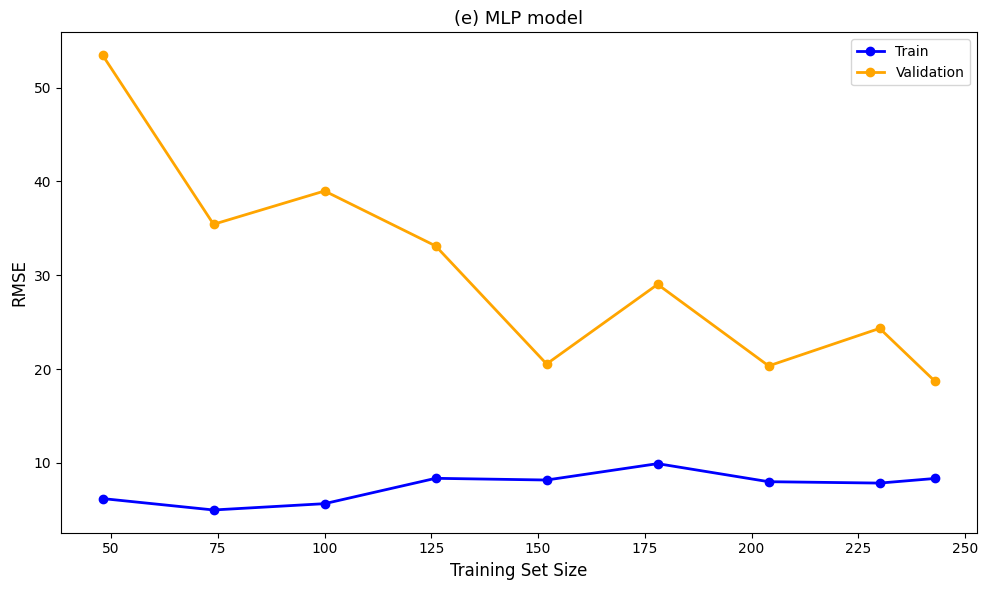


TIMING SUMMARY
Grid Search + 5-Fold CV Time : 33.61 seconds
Final Model Training Time    : 0.34 seconds
Test Prediction Time         : 0.0014 seconds
Total Training Time          : 33.94 seconds
Total Training Time          : 0.57 minutes


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import KFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random
import time

# ============================================================
# 1. Fix Random Seeds
# ============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

# ============================================================
# 2. MLP Model
# ============================================================
class MLP(nn.Module):
    def __init__(self, input_dim, hidden_layers, activation):
        super().__init__()
        layers = []
        prev_dim = input_dim
        act_fn = nn.ReLU() if activation == 'relu' else nn.Tanh()
        for h in hidden_layers:
            layers.append(nn.Linear(prev_dim, h))
            layers.append(act_fn)
            prev_dim = h
        layers.append(nn.Linear(prev_dim, 1))
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)

# ============================================================
# 3. GRID SEARCH HYPERPARAMETERS
# ============================================================
hidden_layer_options = [
    [5],
    [10],
    [10, 5],
    [5, 5],
    [5, 10],
    [10, 10]
]

lr_options = [0.001, 0.01]
alpha_options = [1e-5, 1e-4]

epochs = 250
activation = "relu"

kf = KFold(n_splits=5, shuffle=True, random_state=42)

best_val_rmse = float("inf")
best_config = None

# ============================================================
# 4. GRID SEARCH WITH K-FOLD  (+ Timing)
# ============================================================
print("Running Grid Search with 5-Fold CV")
start_grid = time.time()

for hidden_layers in hidden_layer_options:
    for lr in lr_options:
        for alpha in alpha_options:

            fold_rmses = []

            for train_idx, val_idx in kf.split(X):

                X_train = X[train_idx]
                y_train = y[train_idx]
                X_val = X[val_idx]
                y_val = y[val_idx]

                X_scaler = StandardScaler().fit(X_train)
                y_scaler = StandardScaler().fit(y_train)

                X_train_s = X_scaler.transform(X_train)
                X_val_s = X_scaler.transform(X_val)
                y_train_s = y_scaler.transform(y_train)
                y_val_s = y_scaler.transform(y_val)

                X_train_t = torch.tensor(X_train_s, dtype=torch.float32)
                y_train_t = torch.tensor(y_train_s, dtype=torch.float32)
                X_val_t = torch.tensor(X_val_s, dtype=torch.float32)
                y_val_t = torch.tensor(y_val_s, dtype=torch.float32)

                model = MLP(X.shape[1], hidden_layers, activation)
                optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=alpha)
                criterion = nn.MSELoss()

                for epoch in range(epochs):
                    model.train()
                    optimizer.zero_grad()
                    pred = model(X_train_t)
                    loss = criterion(pred, y_train_t)
                    loss.backward()
                    optimizer.step()

                model.eval()
                with torch.no_grad():
                    pred_val = model(X_val_t).numpy()
                pred_val_real = y_scaler.inverse_transform(pred_val)
                y_val_real = y_scaler.inverse_transform(y_val_s)

                rmse = mean_squared_error(y_val_real, pred_val_real) ** 0.5
                fold_rmses.append(rmse)

            mean_rmse = np.mean(fold_rmses)
            print(f"   layers={hidden_layers}, lr={lr}, alpha={alpha} → RMSE={mean_rmse:.3f}")

            if mean_rmse < best_val_rmse:
                best_val_rmse = mean_rmse
                best_config = (hidden_layers, lr, alpha)

end_grid = time.time()
grid_search_time = end_grid - start_grid

print("\nBest Config Found:")
print(f"   Hidden Layers = {best_config[0]}")
print(f"   LR            = {best_config[1]}")
print(f"   Alpha         = {best_config[2]}")
print(f"   RMSE          = {best_val_rmse:.3f}")
print(f"\nGrid Search + 5-Fold CV Time: {grid_search_time:.2f} seconds")

# ============================================================
# 5. FINAL TRAIN / VAL / TEST SPLIT
# ============================================================
X_trainval, X_test, y_trainval, y_test = train_test_split(X, y, test_size=0.1, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_trainval, y_trainval, test_size=0.1, random_state=42)

# Fit scaler ONLY on train
X_scaler = StandardScaler().fit(X_train)
y_scaler = StandardScaler().fit(y_train)

X_train_s = X_scaler.transform(X_train)
X_val_s = X_scaler.transform(X_val)
X_test_s = X_scaler.transform(X_test)

y_train_s = y_scaler.transform(y_train)
y_val_s = y_scaler.transform(y_val)
y_test_s = y_scaler.transform(y_test)

X_train_t = torch.tensor(X_train_s, dtype=torch.float32)
y_train_t = torch.tensor(y_train_s, dtype=torch.float32)
X_val_t = torch.tensor(X_val_s, dtype=torch.float32)
y_val_t = torch.tensor(y_val_s, dtype=torch.float32)
X_test_t = torch.tensor(X_test_s, dtype=torch.float32)
y_test_t = torch.tensor(y_test_s, dtype=torch.float32)

# ============================================================
# 6. Final Model Training (with epoch losses)  (+ Timing)
# ============================================================
hidden_layers, best_lr, best_alpha = best_config

start_train = time.time()

model = MLP(X_train_t.shape[1], hidden_layers, activation)
optimizer = optim.Adam(model.parameters(), lr=best_lr, weight_decay=best_alpha)
criterion = nn.MSELoss()

train_losses, val_losses = [], []

for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()
    pred = model(X_train_t)
    loss = criterion(pred, y_train_t)
    loss.backward()
    optimizer.step()
    train_losses.append(loss.item())

    model.eval()
    with torch.no_grad():
        pred_val = model(X_val_t)
        val_losses.append(criterion(pred_val, y_val_t).item())

end_train = time.time()
final_train_time = end_train - start_train

# ============================================================
# 7. Evaluation  (+ Test Timing)
# ============================================================
def evaluate(real, pred, name):
    mse = mean_squared_error(real, pred)
    mae = mean_absolute_error(real, pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(real, pred)
    print(f"\n{name}:")
    print(f"MSE={mse:.4f}, MAE={mae:.4f}, RMSE={rmse:.4f}, R²={r2:.4f}")
    return rmse, r2

start_test = time.time()

model.eval()
with torch.no_grad():
    y_pred_train = y_scaler.inverse_transform(model(X_train_t).numpy())
    y_pred_val = y_scaler.inverse_transform(model(X_val_t).numpy())
    y_pred_test = y_scaler.inverse_transform(model(X_test_t).numpy())

end_test = time.time()
test_time = end_test - start_test

y_train_real = y_scaler.inverse_transform(y_train_s)
y_val_real = y_scaler.inverse_transform(y_val_s)
y_test_real = y_scaler.inverse_transform(y_test_s)

train_rmse, train_r2 = evaluate(y_train_real, y_pred_train, "Train")
val_rmse, val_r2 = evaluate(y_val_real, y_pred_val, "Val")
test_rmse, test_r2 = evaluate(y_test_real, y_pred_test, "Test")

# ============================================================
# 8. Epoch-based Learning Curve (Loss vs Epochs)
# ============================================================
plt.figure(figsize=(7, 4))
plt.plot(train_losses, label="Train")
plt.plot(val_losses, label="Validation")
plt.xlabel("Epochs", fontsize=10)
plt.ylabel("MSE Loss", fontsize=10)
plt.legend(fontsize=9)
plt.tick_params(axis='both', labelsize=9)
plt.tight_layout()
plt.show()

# ============================================================
# 9. Learning Curve vs Training Set Size (RMSE)
# ============================================================
print("\nGenerating Learning Curve vs Training Set Size ...")

train_sizes_abs = np.linspace(0.2, 0.95, 8)
train_sizes = (train_sizes_abs * len(X_train)).astype(int)

train_rmse_list = []
val_rmse_list = []

for size in train_sizes:
    rng = np.random.RandomState(42)
    indices = rng.choice(len(X_train), size=size, replace=False)

    X_sub = X_train[indices]
    y_sub = y_train[indices]

    X_scaler_sub = StandardScaler().fit(X_sub)
    y_scaler_sub = StandardScaler().fit(y_sub)

    X_sub_s = X_scaler_sub.transform(X_sub)
    y_sub_s = y_scaler_sub.transform(y_sub)
    X_val_s_sub = X_scaler_sub.transform(X_val)

    X_sub_t = torch.tensor(X_sub_s, dtype=torch.float32)
    y_sub_t = torch.tensor(y_sub_s, dtype=torch.float32)
    X_val_t_sub = torch.tensor(X_val_s_sub, dtype=torch.float32)

    model_sub = MLP(X_sub_t.shape[1], hidden_layers, activation)
    optimizer_sub = optim.Adam(model_sub.parameters(), lr=best_lr, weight_decay=best_alpha)
    criterion = nn.MSELoss()

    for epoch in range(epochs):
        model_sub.train()
        optimizer_sub.zero_grad()
        pred = model_sub(X_sub_t)
        loss = criterion(pred, y_sub_t)
        loss.backward()
        optimizer_sub.step()

    model_sub.eval()
    with torch.no_grad():
        pred_train = y_scaler_sub.inverse_transform(model_sub(X_sub_t).numpy())
        pred_val = y_scaler_sub.inverse_transform(model_sub(X_val_t_sub).numpy())

    y_sub_real = y_scaler_sub.inverse_transform(y_sub_s)

    train_rmse_sub = np.sqrt(mean_squared_error(y_sub_real, pred_train))
    val_rmse_sub = np.sqrt(mean_squared_error(y_val, pred_val))

    train_rmse_list.append(train_rmse_sub)
    val_rmse_list.append(val_rmse_sub)

    print(f"  size={size:4d} | Train RMSE={train_rmse_sub:.4f} | Val RMSE={val_rmse_sub:.4f}")

train_sizes = np.append(train_sizes, len(X_train))
train_rmse_list.append(train_rmse)
val_rmse_list.append(val_rmse)

print(f"  Full Train size={len(X_train)} | Train RMSE={train_rmse:.4f} | Val RMSE={val_rmse:.4f}")

# ============================================================
# Draw Learning Curve vs Training Size
# ============================================================
plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_rmse_list, 'o-', color='blue', linewidth=2, label='Train')
plt.plot(train_sizes, val_rmse_list, 'o-', color='orange', linewidth=2, label='Validation')
plt.title('(e) MLP model', fontsize=13)
plt.xlabel('Training Set Size', fontsize=12)
plt.ylabel('RMSE', fontsize=12)
plt.legend(loc='best')
plt.tight_layout()
plt.show()

# ============================================================
# 10. Print Timing Summary
# ============================================================
total_train_time = grid_search_time + final_train_time

print("\n" + "="*60)
print("TIMING SUMMARY")
print("="*60)
print(f"Grid Search + 5-Fold CV Time : {grid_search_time:.2f} seconds")
print(f"Final Model Training Time    : {final_train_time:.2f} seconds")
print(f"Test Prediction Time         : {test_time:.4f} seconds")
print(f"Total Training Time          : {total_train_time:.2f} seconds")
print(f"Total Training Time          : {total_train_time/60:.2f} minutes")
print("="*60)

In [ ]:
# Complete prediction output

train_results = pd.DataFrame({
    "Dataset": "Train",
    "Actual": y_true_final_train.ravel(),
    "Predicted": y_pred_final_train.ravel()
})

test_results = pd.DataFrame({
    "Dataset": "Test",
    "Actual": y_true_test.ravel(),
    "Predicted": y_pred_test.ravel()
})

all_predictions = pd.concat(
    [train_results, test_results],
    ignore_index=True
)

all_predictions["Error"] = (
    all_predictions["Actual"] -
    all_predictions["Predicted"]
)

all_predictions["Absolute_Error"] = (
    np.abs(all_predictions["Error"])
)

all_predictions.to_excel(
    "MLP_All_Predictions.xlsx",
    index=False
)

print("All predictions exported successfully.")

All predictions exported successfully.


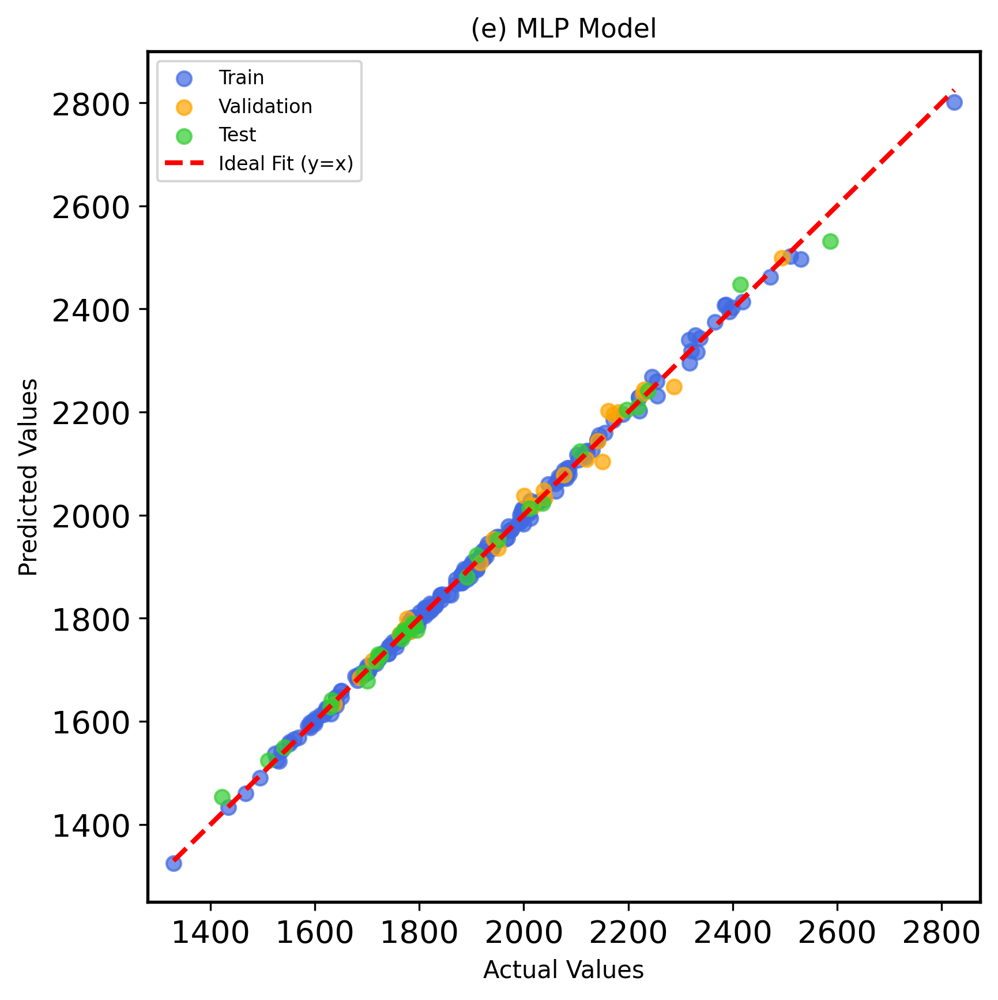

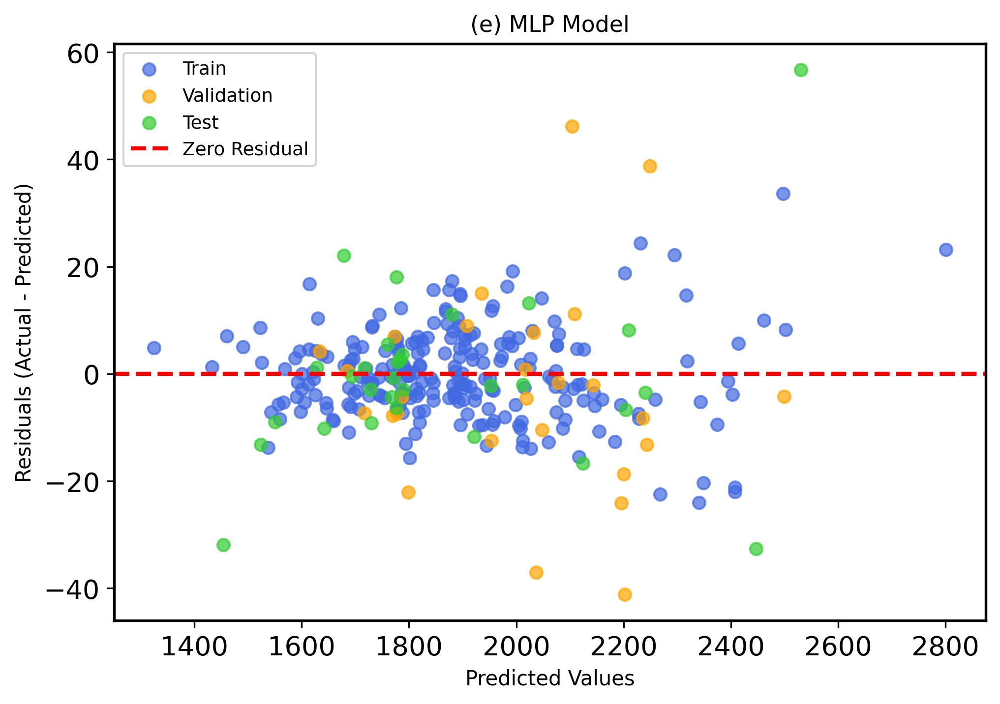

In [ ]:
def plot_mlp_predictions(y_train_real, y_pred_train,
                         y_val_real, y_pred_val,
                         y_test_real, y_pred_test):

    y_train_real = np.ravel(y_train_real)
    y_pred_train = np.ravel(y_pred_train)
    y_val_real   = np.ravel(y_val_real)
    y_pred_val   = np.ravel(y_pred_val)
    y_test_real  = np.ravel(y_test_real)
    y_pred_test  = np.ravel(y_pred_test)

    plt.figure(figsize=(6,6), dpi=300)

    plt.scatter(y_train_real, y_pred_train, color='royalblue', alpha=0.7, label="Train")
    plt.scatter(y_val_real,   y_pred_val,   color='orange', alpha=0.7, label="Validation")
    plt.scatter(y_test_real,  y_pred_test,  color='limegreen', alpha=0.7, label="Test")
    all_true = np.concatenate([y_train_real, y_val_real, y_test_real])
    plt.plot([all_true.min(), all_true.max()],
             [all_true.min(), all_true.max()],
             "r--", lw=2, label="Ideal Fit (y=x)")
    padding = 50
    plt.xlim(all_true.min() - padding, all_true.max() + padding)

    plt.xlabel("Actual Values", fontsize=10)
    plt.ylabel("Predicted Values", fontsize=10)
    plt.title("(e) MLP Model", fontsize=11)
    plt.legend(fontsize=8, loc='upper left')
    plt.grid(False)
    plt.tight_layout()
    plt.show()


def plot_mlp_residuals(y_train_real, y_pred_train,
                       y_val_real, y_pred_val,
                       y_test_real, y_pred_test):

    y_train_real = np.ravel(y_train_real)
    y_pred_train = np.ravel(y_pred_train)
    y_val_real   = np.ravel(y_val_real)
    y_pred_val   = np.ravel(y_pred_val)
    y_test_real  = np.ravel(y_test_real)
    y_pred_test  = np.ravel(y_pred_test)

    res_train = y_train_real - y_pred_train
    res_val   = y_val_real   - y_pred_val
    res_test  = y_test_real  - y_pred_test

    plt.figure(figsize=(7,5), dpi=300)

    plt.scatter(y_pred_train, res_train, color="royalblue", alpha=0.7, label="Train")
    plt.scatter(y_pred_val,   res_val,   color="orange", alpha=0.7, label="Validation")
    plt.scatter(y_pred_test,  res_test,  color="limegreen", alpha=0.7, label="Test")

    plt.axhline(0, color='red', linestyle='--', lw=2, label='Zero Residual')

    plt.xlabel("Predicted Values",fontsize=10)
    plt.ylabel("Residuals (Actual - Predicted)",fontsize=10)
    plt.title("(e) MLP Model",fontsize=11)
    plt.legend(fontsize=9)
    plt.grid(False)
    plt.tight_layout()
    plt.show()

plot_mlp_predictions(
    y_train_real, y_pred_train,
    y_val_real,   y_pred_val,
    y_test_real,  y_pred_test
)

plot_mlp_residuals(
    y_train_real, y_pred_train,
    y_val_real,   y_pred_val,
    y_test_real,  y_pred_test
)


/tmp/ipython-input-1625053802.py:55: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(rect=[0, 0.05, 1, 1])


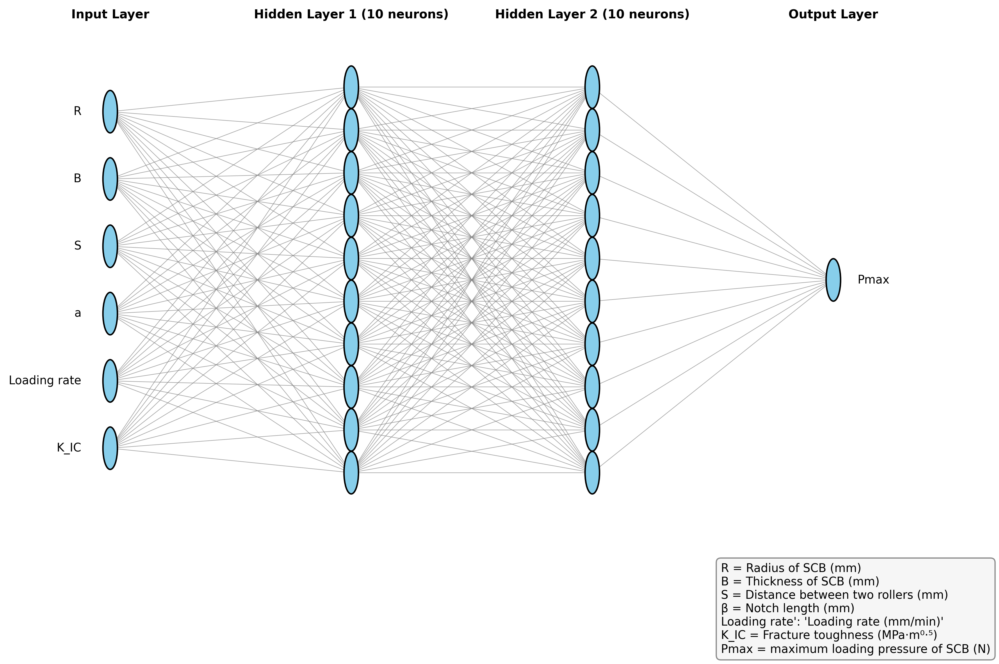

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def draw_mlp_topology_with_legend(input_labels, hidden_layers, output_label):
    layers = [len(input_labels)] + hidden_layers + [1]
    layer_labels = [input_labels] + [[''] * h for h in hidden_layers] + [[output_label]]
    max_neurons = max(layers)

    fig, ax = plt.subplots(figsize=(12, 7))
    ax.axis('off')

    # Drawing nodes (neurons)
    for i, (num_neurons, labels) in enumerate(zip(layers, layer_labels)):
        x = i * 1.5
        y_positions = np.linspace(1, 0, num_neurons + 2)[1:-1]
        for j, y in enumerate(y_positions):
            circle = plt.Circle((x, y), 0.045, color='skyblue', ec='black', lw=1.2, zorder=3)
            ax.add_patch(circle)
            if labels[j]:
                if i == 0:  # Inputs
                    ax.text(x - 0.18, y, labels[j], ha='right', va='center', fontsize=9.5)
                elif i == len(layers) - 1:  # Output
                    ax.text(x + 0.15, y, labels[j], ha='left', va='center', fontsize=9.5)

    #  Drawing connections between layers
    for i in range(len(layers) - 1):
        x1 = i * 1.5
        x2 = (i + 1) * 1.5
        y1s = np.linspace(1, 0, layers[i] + 2)[1:-1]
        y2s = np.linspace(1, 0, layers[i + 1] + 2)[1:-1]
        for y1 in y1s:
            for y2 in y2s:
                ax.plot([x1, x2], [y1, y2], color='gray', lw=0.5, alpha=0.7, zorder=1)

    # Labeling Layers
    layer_names = ['Input Layer', 'Hidden Layer 1 (10 neurons)', 'Hidden Layer 2 (10 neurons)', 'Output Layer']
    for i, name in enumerate(layer_names):
        x = i * 1.5
        ax.text(x, 1.05, name, ha='center', va='bottom', fontsize=10, fontweight='bold')

    # Legend
    legend_text = (
        "R = Radius of SCB (mm)\n"
        "B = Thickness of SCB (mm)\n"
        "S = Distance between two rollers (mm)\n"
        "β = Notch length (mm)\n"
        "Loading rate': 'Loading rate (mm/min)'\n"
        "K_IC = Fracture toughness (MPa·m⁰·⁵)\n"
        "Pmax = maximum loading pressure of SCB (N)"
    )

    ax.text(3.8, -0.1, legend_text, fontsize=9.5, va='top', ha='left',
            bbox=dict(boxstyle="round,pad=0.4", fc="whitesmoke", ec="gray", alpha=0.9))

    plt.tight_layout(rect=[0, 0.05, 1, 1])


    plt.show()


# Input features and model structure
input_features = ["R", "B", "S", "a", "Loading rate", "K_IC"]
hidden_layers = [10, 10]
output_label = "Pmax"
draw_mlp_topology_with_legend(input_features, hidden_layers, output_label)

ELM model

Running Grid Search ...

Best ELM Configuration:
   Hidden Neurons = 60
   Activation     = relu
   Best Val RMSE  = 21.6421
Grid Search Time  : 0.0670 seconds

Train Performance:
   MSE  = 235.2950
   MAE  = 11.7142
   RMSE = 15.3393
   R²   = 0.9952

Validation Performance:
   MSE  = 251.7676
   MAE  = 12.3793
   RMSE = 15.8672
   R²   = 0.9942

Test Performance:
   MSE  = 307.8553
   MAE  = 13.9861
   RMSE = 17.5458
   R²   = 0.9955

Generating Learning Curve vs Training Set Size ...
  size=  48 | Train RMSE=0.0000 | Val RMSE=73.5955
  size=  74 | Train RMSE=2.9055 | Val RMSE=48.3139
  size= 100 | Train RMSE=5.2479 | Val RMSE=37.5680
  size= 126 | Train RMSE=8.3820 | Val RMSE=37.1523
  size= 152 | Train RMSE=14.6472 | Val RMSE=40.0540
  size= 178 | Train RMSE=10.6117 | Val RMSE=30.9104
  size= 204 | Train RMSE=12.5326 | Val RMSE=26.8229
  size= 230 | Train RMSE=14.3182 | Val RMSE=39.9850
  Full Train size=243 | Train RMSE=15.3393 | Val RMSE=15.8672


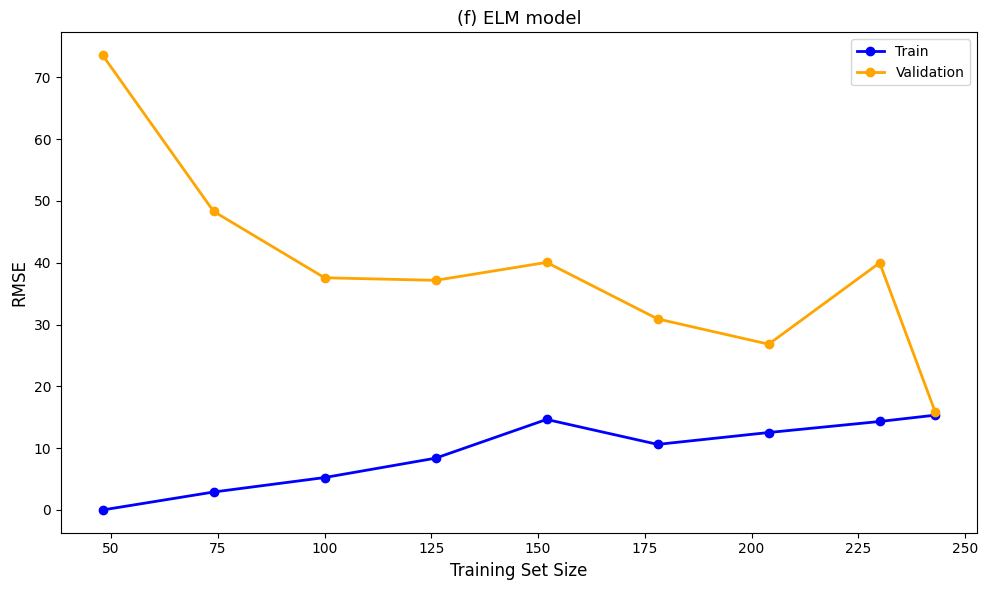

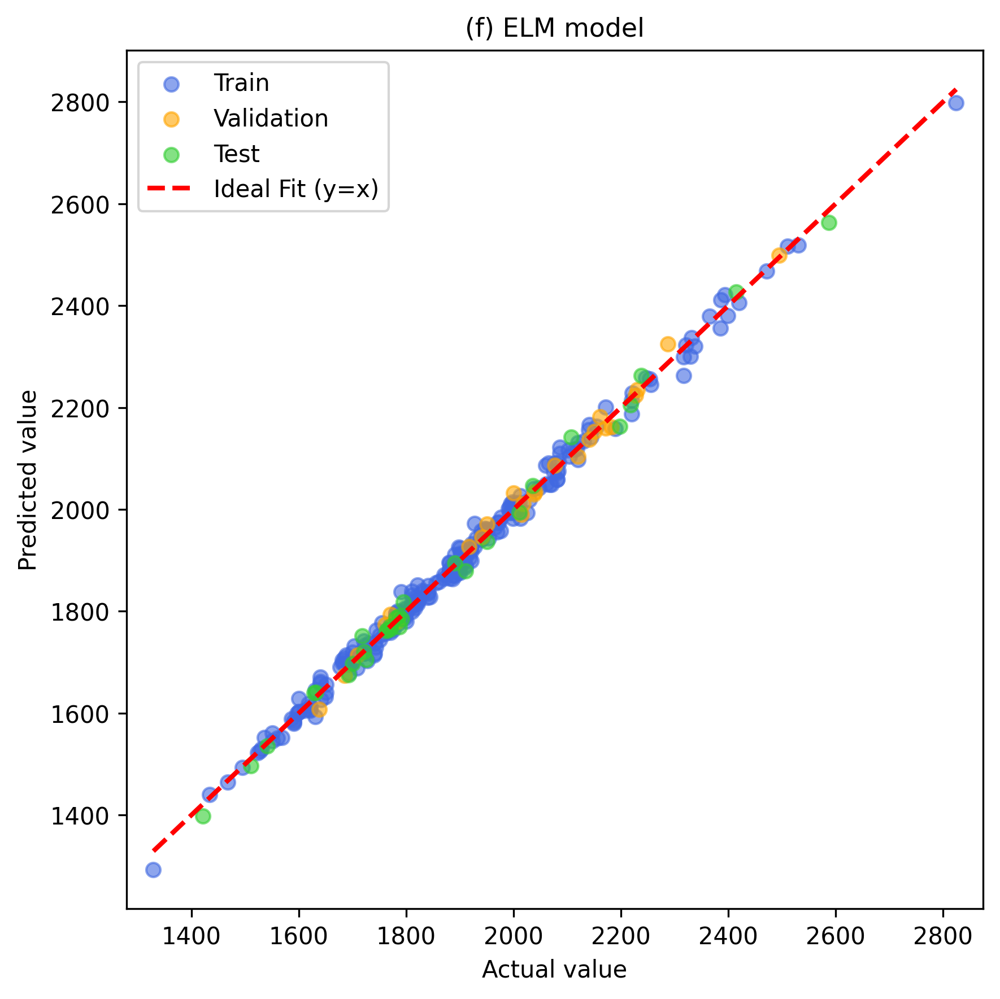

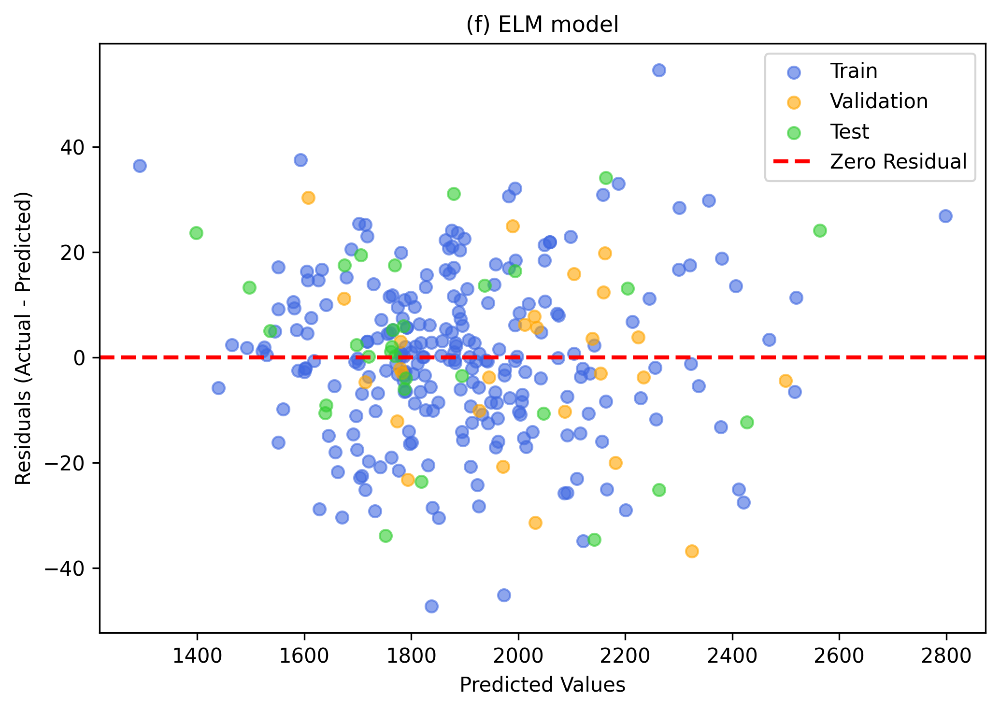


TIMING SUMMARY
Grid Search Time             : 0.0670 seconds
Final Model Training Time    : 0.0036 seconds
Test Prediction Time         : 0.0014 seconds
Total Training Time          : 0.0706 seconds
Total Training Time          : 0.0012 minutes


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random
import time

# ============================================================
# 1. Fixed random setting
# ============================================================
def set_seed(seed=42):
    np.random.seed(seed)
    random.seed(seed)

set_seed(42)

# ============================================================
# 2. Train/Val/Test split BEFORE scaling
# ============================================================
X_trainval, X_test, y_trainval, y_test = train_test_split(X, y, test_size=0.1, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_trainval, y_trainval, test_size=0.1, random_state=42)

# ============================================================
# 3. Fit scaler ONLY on training set
# ============================================================
X_scaler = StandardScaler().fit(X_train)
y_scaler = StandardScaler().fit(y_train)

X_train_s = X_scaler.transform(X_train)
X_val_s   = X_scaler.transform(X_val)
X_test_s  = X_scaler.transform(X_test)

y_train_s = y_scaler.transform(y_train)
y_val_s   = y_scaler.transform(y_val)
y_test_s  = y_scaler.transform(y_test)

# ============================================================
# 4. Definition of the ELM model
# ============================================================
class ELM:
    def __init__(self, input_dim, hidden_neurons, activation='sigmoid'):
        self.hidden_neurons = hidden_neurons
        self.activation = activation
        self.input_weights = np.random.randn(input_dim, hidden_neurons)
        self.biases = np.random.randn(hidden_neurons)

    def _activation(self, X):
        H = X @ self.input_weights + self.biases
        if self.activation == 'sigmoid':
            return 1 / (1 + np.exp(-H))
        elif self.activation == 'tanh':
            return np.tanh(H)
        elif self.activation == 'relu':
            return np.maximum(0, H)
        else:
            raise ValueError("Unsupported activation")

    def fit(self, X, y):
        H = self._activation(X)
        self.output_weights = np.linalg.pinv(H) @ y

    def predict(self, X):
        H = self._activation(X)
        return H @ self.output_weights

# ============================================================
# 5. Grid Search  (+ Timing)
# ============================================================
print("Running Grid Search ...")
start_grid = time.time()

hidden_neuron_options = [10, 20, 40, 60, 80]
activation_options = ["sigmoid", "tanh", "relu"]
param_grid = [(hn, act) for hn in hidden_neuron_options for act in activation_options]

best_rmse_val = float("inf")
best_config = None
results = []

for hidden_neurons, activation in param_grid:
    elm = ELM(input_dim=X_train_s.shape[1], hidden_neurons=hidden_neurons, activation=activation)
    elm.fit(X_train_s, y_train_s)

    y_pred_val_scaled = elm.predict(X_val_s)
    y_pred_val = y_scaler.inverse_transform(y_pred_val_scaled.reshape(-1, 1))
    y_val_true = y_scaler.inverse_transform(y_val_s)

    mse = mean_squared_error(y_val_true, y_pred_val)
    rmse = np.sqrt(mse)

    results.append({
        "hidden_neurons": hidden_neurons,
        "activation": activation,
        "RMSE": rmse
    })

    if rmse < best_rmse_val:
        best_rmse_val = rmse
        best_config = (hidden_neurons, activation)

end_grid = time.time()
grid_search_time = end_grid - start_grid

results_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
best_hidden, best_act = best_config

print(f"\nBest ELM Configuration:")
print(f"   Hidden Neurons = {best_hidden}")
print(f"   Activation     = {best_act}")
print(f"   Best Val RMSE  = {best_rmse_val:.4f}")
print(f"Grid Search Time  : {grid_search_time:.4f} seconds")

# ============================================================
# 6. Final training on Train+Val  (+ Timing)
# ============================================================
start_train = time.time()

X_final_train = np.vstack((X_train_s, X_val_s))
y_final_train = np.vstack((y_train_s, y_val_s))

elm_best = ELM(input_dim=X_train_s.shape[1], hidden_neurons=best_hidden, activation=best_act)
elm_best.fit(X_final_train, y_final_train)

end_train = time.time()
final_train_time = end_train - start_train

# Predictions
start_test = time.time()

y_pred_train = y_scaler.inverse_transform(elm_best.predict(X_train_s).reshape(-1, 1))
y_pred_val   = y_scaler.inverse_transform(elm_best.predict(X_val_s).reshape(-1, 1))
y_pred_test  = y_scaler.inverse_transform(elm_best.predict(X_test_s).reshape(-1, 1))

end_test = time.time()
test_time = end_test - start_test

y_train_true = y_scaler.inverse_transform(y_train_s)
y_val_true   = y_scaler.inverse_transform(y_val_s)
y_test_true  = y_scaler.inverse_transform(y_test_s)

# ============================================================
# 7. Metrics
# ============================================================
def evaluate(y_true, y_pred, name):
    mse = mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    print(f"\n{name} Performance:")
    print(f"   MSE  = {mse:.4f}")
    print(f"   MAE  = {mae:.4f}")
    print(f"   RMSE = {rmse:.4f}")
    print(f"   R²   = {r2:.4f}")
    return rmse

train_rmse = evaluate(y_train_true, y_pred_train, "Train")
val_rmse   = evaluate(y_val_true,   y_pred_val,   "Validation")
test_rmse  = evaluate(y_test_true,  y_pred_test,  "Test")

# ============================================================
# 8. Learning Curve (RMSE vs Training Set Size) - Fixed duplicate
# ============================================================
print("\nGenerating Learning Curve vs Training Set Size ...")

train_sizes_abs = np.linspace(0.2, 0.95, 8)          # تا ۹۵٪
train_sizes = (train_sizes_abs * len(X_train)).astype(int)

train_rmse_list = []
val_rmse_list = []

for size in train_sizes:
    rng = np.random.RandomState(42)
    indices = rng.choice(len(X_train), size=size, replace=False)

    X_sub = X_train[indices]
    y_sub = y_train[indices]

    X_scaler_sub = StandardScaler().fit(X_sub)
    y_scaler_sub = StandardScaler().fit(y_sub)

    X_sub_s = X_scaler_sub.transform(X_sub)
    y_sub_s = y_scaler_sub.transform(y_sub)
    X_val_s_sub = X_scaler_sub.transform(X_val)

    elm_sub = ELM(input_dim=X_sub_s.shape[1], hidden_neurons=best_hidden, activation=best_act)
    elm_sub.fit(X_sub_s, y_sub_s)

    y_pred_sub = y_scaler_sub.inverse_transform(elm_sub.predict(X_sub_s).reshape(-1, 1))
    y_pred_val_sub = y_scaler_sub.inverse_transform(elm_sub.predict(X_val_s_sub).reshape(-1, 1))

    y_sub_true = y_scaler_sub.inverse_transform(y_sub_s)

    train_rmse_sub = np.sqrt(mean_squared_error(y_sub_true, y_pred_sub))
    val_rmse_sub = np.sqrt(mean_squared_error(y_val, y_pred_val_sub))

    train_rmse_list.append(train_rmse_sub)
    val_rmse_list.append(val_rmse_sub)

    print(f"  size={size:4d} | Train RMSE={train_rmse_sub:.4f} | Val RMSE={val_rmse_sub:.4f}")

# نقطه نهایی (۱۰۰٪) - فقط یک‌بار
train_sizes = np.append(train_sizes, len(X_train))
train_rmse_list.append(train_rmse)
val_rmse_list.append(val_rmse)

print(f"  Full Train size={len(X_train)} | Train RMSE={train_rmse:.4f} | Val RMSE={val_rmse:.4f}")

# ============================================================
# رسم Learning Curve
# ============================================================
plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_rmse_list, 'o-', color='blue', linewidth=2, label='Train')
plt.plot(train_sizes, val_rmse_list, 'o-', color='orange', linewidth=2, label='Validation')
plt.title('(f) ELM model', fontsize=13)
plt.xlabel('Training Set Size', fontsize=12)
plt.ylabel('RMSE', fontsize=12)
plt.legend(loc='best')
plt.tight_layout()
plt.show()

# ============================================================
# 9. Actual vs Predicted
# ============================================================
plt.figure(figsize=(6, 6), dpi=300)
plt.scatter(y_train_true, y_pred_train, color='royalblue', alpha=0.6, label='Train')
plt.scatter(y_val_true, y_pred_val, color='orange', alpha=0.6, label='Validation')
plt.scatter(y_test_true, y_pred_test, color='limegreen', alpha=0.6, label='Test')

min_val = min(y_train_true.min(), y_val_true.min(), y_test_true.min())
max_val = max(y_train_true.max(), y_val_true.max(), y_test_true.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Ideal Fit (y=x)')

padding = 50
plt.xlim(min_val - padding, max_val + padding)
plt.title("(f) ELM model", fontsize=11)
plt.xlabel("Actual value", fontsize=10)
plt.ylabel("Predicted value", fontsize=10)
plt.legend()
plt.tight_layout()
plt.show()

# ============================================================
# 10. Residual plots
# ============================================================
res_train = y_train_true - y_pred_train
res_val   = y_val_true   - y_pred_val
res_test  = y_test_true  - y_pred_test

plt.figure(figsize=(7, 5), dpi=300)
plt.scatter(y_pred_train, res_train, color='royalblue', alpha=0.6, label='Train')
plt.scatter(y_pred_val, res_val, color='orange', alpha=0.6, label='Validation')
plt.scatter(y_pred_test, res_test, color='limegreen', alpha=0.6, label='Test')

plt.axhline(0, color='r', linestyle='--', lw=2, label='Zero Residual')
plt.title("(f) ELM model", fontsize=11)
plt.xlabel("Predicted Values", fontsize=10)
plt.ylabel("Residuals (Actual - Predicted)", fontsize=10)
plt.legend()
plt.tight_layout()
plt.show()

# ============================================================
# 11. Timing Summary
# ============================================================
total_train_time = grid_search_time + final_train_time

print("\n" + "="*60)
print("TIMING SUMMARY")
print("="*60)
print(f"Grid Search Time             : {grid_search_time:.4f} seconds")
print(f"Final Model Training Time    : {final_train_time:.4f} seconds")
print(f"Test Prediction Time         : {test_time:.4f} seconds")
print(f"Total Training Time          : {total_train_time:.4f} seconds")
print(f"Total Training Time          : {total_train_time/60:.4f} minutes")
print("="*60)

In [ ]:
# Complete prediction output

train_results = pd.DataFrame({
    "Dataset": "Train",
    "Actual": y_true_final_train.ravel(),
    "Predicted": y_pred_final_train.ravel()
})

test_results = pd.DataFrame({
    "Dataset": "Test",
    "Actual": y_true_test.ravel(),
    "Predicted": y_pred_test.ravel()
})

all_predictions = pd.concat(
    [train_results, test_results],
    ignore_index=True
)

all_predictions["Error"] = (
    all_predictions["Actual"] -
    all_predictions["Predicted"]
)

all_predictions["Absolute_Error"] = (
    np.abs(all_predictions["Error"])
)

all_predictions.to_excel(
    "ELM_All_Predictions.xlsx",
    index=False
)

print("All predictions exported successfully.")

All predictions exported successfully.



 Plotting ELM Learning Curve based on number of hidden neurons...


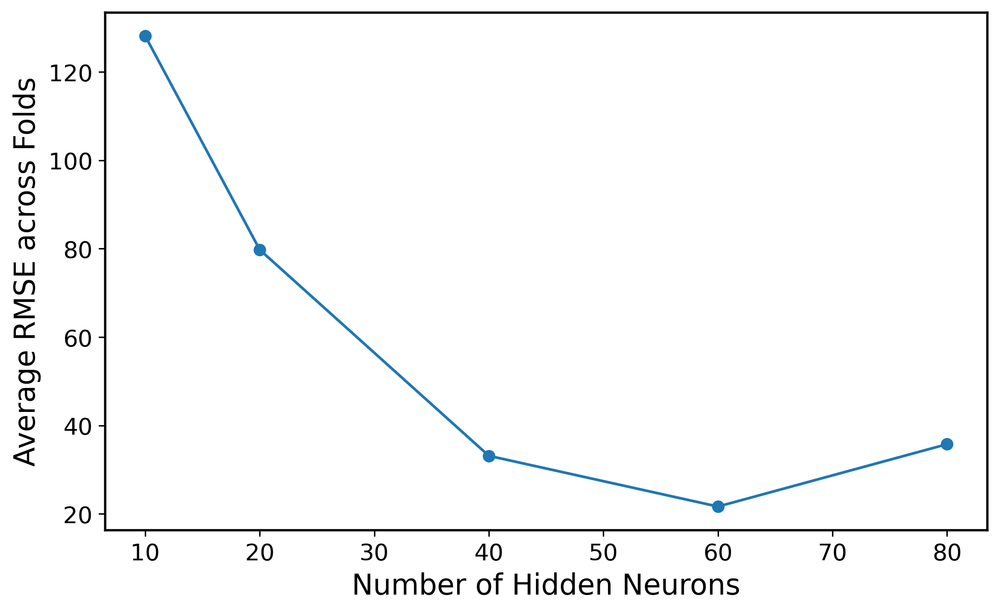

In [ ]:
# Plot Learning Curve based on hidden neurons for the best ELM activation
print("\n Plotting ELM Learning Curve based on number of hidden neurons...")

# Find the best activation from the overall best ELM config
best_elm_activation = best_config[1]

# Filter results for the best activation to analyze neuron effect
results_best_activation = results_df[results_df['activation'] == best_elm_activation].sort_values("hidden_neurons")

plt.figure(figsize=(8, 5))
plt.plot(results_best_activation['hidden_neurons'], results_best_activation['RMSE'], marker='o')
plt.xlabel("Number of Hidden Neurons")
plt.ylabel("Average RMSE across Folds")
plt.grid(False)
plt.tight_layout()
plt.show()

Stacking: SVR+MLP+Ridge

In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import random
import time
import matplotlib.pyplot as plt

from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# ============================================================
# 1. Reproducibility and data preparation
# ============================================================
SEED = 42

def set_seed(seed=42):
    # Cast to a native Python int to support Python 3.13 seed type validation
    safe_seed = int(seed) if seed is not None else None
    random.seed(safe_seed)
    np.random.seed(safe_seed)
    torch.manual_seed(safe_seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(safe_seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(SEED)

X_temp = np.asarray(X_temp)
X_test = np.asarray(X_test)
y_temp = np.asarray(y_temp).reshape(-1, 1)
y_test = np.asarray(y_test).reshape(-1, 1)

assert len(X_temp) == len(y_temp), "X_temp and y_temp lengths differ."
assert len(X_test) == len(y_test), "X_test and y_test lengths differ."
assert len(X_temp) >= 5, "At least 5 training samples are required."

print("X_temp samples:", len(X_temp))
print("X_test samples :", len(X_test))
print("Number of features:", X_temp.shape[1])


# ============================================================
# 2. Hyperparameters (kept unchanged)
# ============================================================
best_params = {
    "kernel": "rbf",
    "C": 10,
    "gamma": 0.01,
    "epsilon": 0.01
}

best_lr = 0.01
best_alpha = 0.0001
epochs = 250
ridge_alpha = 1.0

N_SPLITS = 5

# Learning-curve settings
LC_POINTS = 8
LC_REPEATS = 3


# ============================================================
# 3. MLP architecture
# ============================================================
class MLP(nn.Module):
    def __init__(self, input_dim):
        super().__init__()

        self.model = nn.Sequential(
            nn.Linear(input_dim, 10),
            nn.ReLU(),
            nn.Linear(10, 10),
            nn.ReLU(),
            nn.Linear(10, 1)
        )

    def forward(self, x):
        return self.model(x)


def train_mlp(X_s, y_s, seed=42):
    set_seed(seed)

    model = MLP(X_s.shape[1])

    optimizer = optim.Adam(
        model.parameters(),
        lr=best_lr,
        weight_decay=best_alpha
    )

    criterion = nn.MSELoss()

    Xt = torch.tensor(X_s, dtype=torch.float32)
    yt = torch.tensor(y_s, dtype=torch.float32)

    for _ in range(epochs):
        model.train()
        optimizer.zero_grad()

        loss = criterion(model(Xt), yt)
        loss.backward()
        optimizer.step()

    model.eval()
    return model


def predict_mlp(model, X_s):
    with torch.no_grad():
        Xt = torch.tensor(X_s, dtype=torch.float32)
        return model(Xt).cpu().numpy()


# ============================================================
# 4. Base-model fitting and prediction
# ============================================================
def fit_bases(X, y, seed=42):
    # Fit scalers ONLY on the current training subset
    xs = StandardScaler().fit(X)
    ys = StandardScaler().fit(y)

    Xs = xs.transform(X)
    y_scaled = ys.transform(y)

    svr = SVR(**best_params)
    svr.fit(Xs, y_scaled.ravel())

    mlp = train_mlp(Xs, y_scaled, seed=seed)

    return svr, mlp, xs, ys


def predict_bases(svr, mlp, xs, ys, X):
    Xs = xs.transform(X)

    p_svr_scaled = svr.predict(Xs).reshape(-1, 1)
    p_mlp_scaled = predict_mlp(mlp, Xs)

    # Return predictions in original target units
    p_svr = ys.inverse_transform(p_svr_scaled).ravel()
    p_mlp = ys.inverse_transform(p_mlp_scaled).ravel()

    return p_svr, p_mlp


# ============================================================
# 5. Metrics
# ============================================================
def calc_metrics(y_true, y_pred):
    y_true = np.asarray(y_true).ravel()
    y_pred = np.asarray(y_pred).ravel()

    return {
        "MSE": mean_squared_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred)
    }


def evaluate_all(name, y_true, y_pred):
    m = calc_metrics(y_true, y_pred)

    print(f"\n{name}:")
    print(f"  MSE  = {m['MSE']:.4f}")
    print(f"  MAE  = {m['MAE']:.4f}")
    print(f"  RMSE = {m['RMSE']:.4f}")
    print(f"  R2   = {m['R2']:.4f}")

    return m


# ============================================================
# 6. Generate leakage-free OOF predictions for Ridge
# ============================================================
def generate_oof_meta_features(X, y, n_splits=5, seed=42):
    """
    Each row of the returned meta-features is generated by
    base models that did NOT train on that row.

    The target y is used only to fit the base models inside
    the corresponding training folds.
    """

    n = len(X)
    n_splits = min(n_splits, n)

    if n_splits < 2:
        raise ValueError(
            "At least 2 samples are required for OOF predictions."
        )

    oof_svr = np.full(n, np.nan)
    oof_mlp = np.full(n, np.nan)

    kf = KFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=seed
    )

    for fold, (fit_idx, hold_idx) in enumerate(kf.split(X), start=1):

        X_fit, y_fit = X[fit_idx], y[fit_idx]
        X_hold = X[hold_idx]

        svr, mlp, xs, ys = fit_bases(
            X_fit,
            y_fit,
            seed=seed + fold
        )

        p_svr, p_mlp = predict_bases(
            svr, mlp, xs, ys, X_hold
        )

        oof_svr[hold_idx] = p_svr
        oof_mlp[hold_idx] = p_mlp

    if np.isnan(oof_svr).any() or np.isnan(oof_mlp).any():
        raise RuntimeError("Some OOF predictions were not generated.")

    return np.column_stack([oof_svr, oof_mlp])


# ============================================================
# 7. Correct 5-fold outer cross-validation
# ============================================================
kf = KFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=SEED
)

cv_results = {
    name: {"RMSE": [], "MAE": [], "R2": [], "MSE": []}
    for name in ["SVR", "MLP", "Stacking"]
}

# Store out-of-fold predictions for the whole X_temp
oof_predictions = {
    name: np.full(len(X_temp), np.nan)
    for name in ["SVR", "MLP", "Stacking"]
}

fold_indices = []

print("\n========== Correct 5-Fold CV ==========")

cv_start = time.time()

for fold, (tr_idx, val_idx) in enumerate(
    kf.split(X_temp), start=1
):
    X_tr, X_val = X_temp[tr_idx], X_temp[val_idx]
    y_tr, y_val = y_temp[tr_idx], y_temp[val_idx]

    # --------------------------------------------------------
    # A. Generate OOF meta-features using ONLY outer training
    # --------------------------------------------------------
    meta_oof_tr = generate_oof_meta_features(
        X_tr,
        y_tr,
        n_splits=N_SPLITS,
        seed=SEED + 100 * fold
    )

    # Train Ridge using out-of-fold predictions only
    ridge = Ridge(alpha=ridge_alpha)
    ridge.fit(meta_oof_tr, y_tr.ravel())

    # --------------------------------------------------------
    # B. Fit base models on the complete outer training fold
    # --------------------------------------------------------
    svr, mlp, xs, ys = fit_bases(
        X_tr,
        y_tr,
        seed=SEED + fold
    )

    # Outer validation predictions
    p_svr_val, p_mlp_val = predict_bases(
        svr, mlp, xs, ys, X_val
    )

    meta_val = np.column_stack([p_svr_val, p_mlp_val])
    p_stack_val = ridge.predict(meta_val)

    # Store genuinely out-of-fold predictions
    oof_predictions["SVR"][val_idx] = p_svr_val
    oof_predictions["MLP"][val_idx] = p_mlp_val
    oof_predictions["Stacking"][val_idx] = p_stack_val

    # --------------------------------------------------------
    # C. Descriptive outer-training metrics
    # --------------------------------------------------------
    p_svr_tr, p_mlp_tr = predict_bases(
        svr, mlp, xs, ys, X_tr
    )

    meta_tr_full = np.column_stack([p_svr_tr, p_mlp_tr])
    p_stack_tr = ridge.predict(meta_tr_full)

    train_predictions = {
        "SVR": p_svr_tr,
        "MLP": p_mlp_tr,
        "Stacking": p_stack_tr
    }

    # --------------------------------------------------------
    # D. Store validation metrics for each outer fold
    # --------------------------------------------------------
    for name, pred in [
        ("SVR", p_svr_val),
        ("MLP", p_mlp_val),
        ("Stacking", p_stack_val)
    ]:
        m = calc_metrics(y_val, pred)

        for metric in ["MSE", "RMSE", "MAE", "R2"]:
            cv_results[name][metric].append(m[metric])

    fold_indices.append((tr_idx.copy(), val_idx.copy()))

    print(
        f"Fold {fold}: "
        f"SVR R2={cv_results['SVR']['R2'][-1]:.4f} | "
        f"MLP R2={cv_results['MLP']['R2'][-1]:.4f} | "
        f"Stacking R2={cv_results['Stacking']['R2'][-1]:.4f}"
    )

cv_time = time.time() - cv_start


# ============================================================
# 8. Mean and standard deviation across outer folds
# ============================================================
print("\n========== 5-Fold CV Summary ==========")

cv_summary_rows = []

for name in ["SVR", "MLP", "Stacking"]:
    row = {"Model": name}

    for metric in ["RMSE", "MAE", "R2"]:
        values = np.asarray(cv_results[name][metric])

        row[f"{metric}_mean"] = values.mean()
        row[f"{metric}_std"] = values.std(ddof=1)

    cv_summary_rows.append(row)

cv_summary = pd.DataFrame(cv_summary_rows)

print(
    cv_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# Pooled outer OOF metrics:
# every X_temp sample is predicted by a model that did not
# train on that sample in the corresponding outer fold.
print("\n========== Pooled Outer-OOF Results ==========")

pooled_oof_metrics = {}

for name in ["SVR", "MLP", "Stacking"]:
    if np.isnan(oof_predictions[name]).any():
        raise RuntimeError(f"Missing outer OOF predictions: {name}")

    pooled_oof_metrics[name] = evaluate_all(
        f"{name} - Pooled Outer OOF",
        y_temp.ravel(),
        oof_predictions[name]
    )


# ============================================================
# 9. Final OOF-trained Stacking model
# ============================================================
print("\n========== Final Model Training ==========")

final_start = time.time()

# First train Ridge using OOF predictions from X_temp
final_meta_oof = generate_oof_meta_features(
    X_temp,
    y_temp,
    n_splits=N_SPLITS,
    seed=SEED + 1000
)

final_ridge = Ridge(alpha=ridge_alpha)
final_ridge.fit(final_meta_oof, y_temp.ravel())

# Then train the final base models on all X_temp
final_svr, final_mlp, final_xs, final_ys = fit_bases(
    X_temp,
    y_temp,
    seed=SEED
)

final_train_time = time.time() - final_start


# ============================================================
# 10. Final model evaluation
# ============================================================

# Train predictions: descriptive in-sample metrics.
# They are not independent performance estimates.
p_svr_train, p_mlp_train = predict_bases(
    final_svr, final_mlp,
    final_xs, final_ys, X_temp
)

p_stack_train = final_ridge.predict(
    np.column_stack([p_svr_train, p_mlp_train])
)

print("\n========== Final Training Metrics ==========")

m_svr_train = evaluate_all(
    "SVR Train (in-sample)",
    y_temp.ravel(), p_svr_train
)

m_mlp_train = evaluate_all(
    "MLP Train (in-sample)",
    y_temp.ravel(), p_mlp_train
)

m_stack_train = evaluate_all(
    "Stacking Train (in-sample)",
    y_temp.ravel(), p_stack_train
)


# ------------------------------------------------------------
# Validation summary = mean outer 5-fold CV performance
# ------------------------------------------------------------
print("\n========== Validation: Mean 5-Fold CV ==========")

for name in ["SVR", "MLP", "Stacking"]:
    print(f"\n{name}:")
    for metric in ["RMSE", "MAE", "R2"]:
        mean_value = np.mean(cv_results[name][metric])
        std_value = np.std(cv_results[name][metric], ddof=1)

        print(
            f"  {metric}: {mean_value:.4f} "
            f"+/- {std_value:.4f}"
        )


# ------------------------------------------------------------
# Test set: evaluated only after all model fitting is complete
# ------------------------------------------------------------
test_start = time.time()

p_svr_test, p_mlp_test = predict_bases(
    final_svr, final_mlp,
    final_xs, final_ys, X_test
)

p_stack_test = final_ridge.predict(
    np.column_stack([p_svr_test, p_mlp_test])
)

test_time = time.time() - test_start

print("\n========== Independent Test Results ==========")

m_svr_test = evaluate_all(
    "SVR Test", y_test.ravel(), p_svr_test
)

m_mlp_test = evaluate_all(
    "MLP Test", y_test.ravel(), p_mlp_test
)

m_stack_test = evaluate_all(
    "Stacking Test", y_test.ravel(), p_stack_test
)


# ============================================================
# 11. Comparable summary table
# ============================================================
summary_rows = []

train_metrics = {
    "SVR": m_svr_train,
    "MLP": m_mlp_train,
    "Stacking": m_stack_train
}

test_metrics = {
    "SVR": m_svr_test,
    "MLP": m_mlp_test,
    "Stacking": m_stack_test
}

for name in ["SVR", "MLP", "Stacking"]:
    summary_rows.append({
        "Model": name,

        # In-sample; descriptive only
        "Train_RMSE": train_metrics[name]["RMSE"],
        "Train_R2": train_metrics[name]["R2"],

        # Mean across five independent outer validation folds
        "CV_RMSE_mean": np.mean(cv_results[name]["RMSE"]),
        "CV_RMSE_std": np.std(
            cv_results[name]["RMSE"], ddof=1
        ),
        "CV_R2_mean": np.mean(cv_results[name]["R2"]),
        "CV_R2_std": np.std(
            cv_results[name]["R2"], ddof=1
        ),

        # Independent test set
        "Test_RMSE": test_metrics[name]["RMSE"],
        "Test_R2": test_metrics[name]["R2"]
    })

summary = pd.DataFrame(summary_rows)

print("\n========== FINAL SUMMARY TABLE ==========")
print(
    summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ============================================================
# 13. Timing and completion
# ============================================================
print("\n========== COMPUTATIONAL TIME ==========")
print(f"Outer CV time     : {cv_time:.2f} s")
print(f"Final training    : {final_train_time:.2f} s")
print(f"Test prediction   : {test_time:.4f} s")

print("\nSaved:")
print(" - stacking_summary.csv")
print(" - stacking_cv_summary.csv")
print(" - stacking_learning_curve.png")
print(" - stacking_learning_curve_data.csv")

print("\nDone.")

X_temp samples: 270
X_test samples : 30
Number of features: 6

========== Correct 5-Fold CV ==========


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Fold 1: SVR R2=0.9864 | MLP R2=0.9837 | Stacking R2=0.9909


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Fold 2: SVR R2=0.9925 | MLP R2=0.9914 | Stacking R2=0.9954


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

... (4 outputs left out)

Fold 5: SVR R2=0.9901 | MLP R2=0.9964 | Stacking R2=0.9945

========== 5-Fold CV Summary ==========
   Model  RMSE_mean  RMSE_std  MAE_mean  MAE_std  R2_mean  R2_std
     SVR    19.5954    7.3532   11.0879   2.7129   0.9917  0.0038
     MLP    20.5058    8.2478   13.1888   4.2187   0.9907  0.0049
Stacking    16.3691    5.8920   10.8543   2.7182   0.9941  0.0028

========== Pooled Outer-OOF Results ==========

SVR - Pooled Outer OOF:
  MSE  = 427.2346
  MAE  = 11.0879
  RMSE = 20.6697
  R2   = 0.9913

MLP - Pooled Outer OOF:
  MSE  = 474.9100
  MAE  = 13.1888
  RMSE = 21.7924
  R2   = 0.9904

Stacking - Pooled Outer OOF:
  MSE  = 295.7205
  MAE  = 10.8543
  RMSE = 17.1965
  R2   = 0.9940

========== Final Model Training ==========


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



========== Final Training Metrics ==========

SVR Train (in-sample):
  MSE  = 207.2329
  MAE  = 7.6903
  RMSE = 14.3956
  R2   = 0.9958

MLP Train (in-sample):
  MSE  = 104.0348
  MAE  = 7.5485
  RMSE = 10.1997
  R2   = 0.9979

Stacking Train (in-sample):
  MSE  = 158.4209
  MAE  = 7.8003
  RMSE = 12.5865
  R2   = 0.9968

========== Validation: Mean 5-Fold CV ==========

SVR:
  RMSE: 19.5954 +/- 7.3532
  MAE: 11.0879 +/- 2.7129
  R2: 0.9917 +/- 0.0038

MLP:
  RMSE: 20.5058 +/- 8.2478
  MAE: 13.1888 +/- 4.2187
  R2: 0.9907 +/- 0.0049

Stacking:
  RMSE: 16.3691 +/- 5.8920
  MAE: 10.8543 +/- 2.7182
  R2: 0.9941 +/- 0.0028

========== Independent Test Results ==========

SVR Test:
  MSE  = 336.2272
  MAE  = 10.7387
  RMSE = 18.3365
  R2   = 0.9951

MLP Test:
  MSE  = 262.2994
  MAE  = 11.4462
  RMSE = 16.1957
  R2   = 0.9961

Stacking Test:
  MSE  = 325.5148
  MAE  = 10.0354
  RMSE = 18.0420
  R2   = 0.9952

========== FINAL SUMMARY TABLE ==========
   Model  Train_RMSE  Train_R2  CV_RMSE

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



========== Learning Curve: 5-Fold CV ==========

----- Learning-curve repeat 1/3 -----


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Total development samples =   54 | Samples per training fold ~   43 | Samples per validation fold ~  11


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Total development samples =   85 | Samples per training fold ~   68 | Samples per validation fold ~  17


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

... (40 outputs left out)

Total development samples =  239 | Samples per training fold ~  191 | Samples per validation fold ~  48


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Total development samples =  270 | Samples per training fold ~  216 | Samples per validation fold ~  54

========== Learning Curve Summary ==========
 Development_Size  Train_RMSE_Mean  Train_RMSE_STD  Validation_RMSE_Mean  Validation_RMSE_STD  Validation_R2_Mean  Validation_R2_STD
               54          21.5902          7.6748               43.3950              20.4584              0.9359             0.0819
               85          17.4890          4.0087               34.5838              17.3843              0.9691             0.0231
              116          15.6721          2.9488               25.8351              11.9265              0.9846             0.0111
              147          13.2447          2.9797               24.3864              14.2059              0.9866             0.0126
              177          12.5525          1.7532               21.3878               6.5235              0.9887             0.0065
              208          11.6720          1.1364  

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


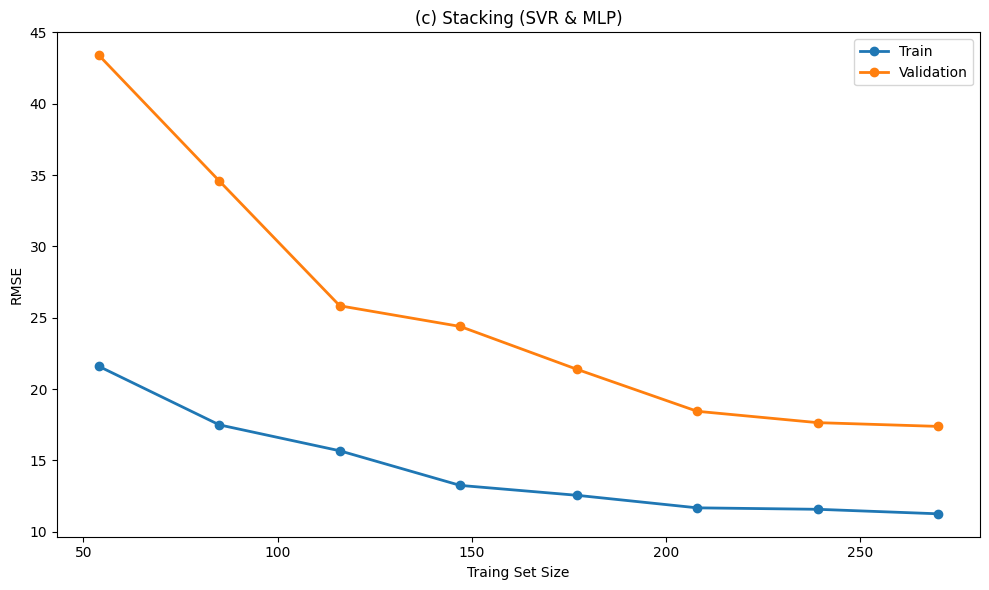


Learning-curve computation time: 206.31 seconds
Saved: stacking_learning_curve_cv.png
Saved: stacking_learning_curve_cv.csv


In [ ]:

# ============================================================
# 12. Learning Curve using 5-Fold Cross-Validation
# X-axis = total development samples used in each experiment
# Maximum development subset size = len(X_temp), e.g. 270
# ============================================================

print("\n========== Learning Curve: 5-Fold CV ==========")

LC_POINTS = 8
LC_REPEATS = 3
LC_SPLITS = 5

lc_start = time.time()

N_total = len(X_temp)

# Total number of development samples at each learning-curve point
# Includes the full development set as the final point.
train_sizes = np.unique(
    np.round(
        np.linspace(
            max(LC_SPLITS + 1, int(0.20 * N_total)),
            N_total,
            LC_POINTS
        )
    ).astype(int)
)

lc_results = {
    int(n): {
        "train_rmse": [],
        "val_rmse": [],
        "val_r2": []
    }
    for n in train_sizes
}

for repeat in range(LC_REPEATS):

    # Each repeat uses a different ordering of the development data.
    # Subsets are nested within a repeat as sample size increases.
    rng = np.random.RandomState(SEED + 5000 + repeat)
    permutation = rng.permutation(N_total)

    print(f"\n----- Learning-curve repeat {repeat + 1}/{LC_REPEATS} -----")

    for n_samples in train_sizes:

        selected_idx = permutation[:n_samples]

        X_subset = X_temp[selected_idx]
        y_subset = y_temp[selected_idx]

        # Five-fold CV on the selected development subset
        lc_kf = KFold(
            n_splits=LC_SPLITS,
            shuffle=True,
            random_state=SEED + 100 * repeat + int(n_samples)
        )

        for fold, (tr_idx, val_idx) in enumerate(
            lc_kf.split(X_subset), start=1
        ):

            X_tr = X_subset[tr_idx]
            y_tr = y_subset[tr_idx]

            X_val = X_subset[val_idx]
            y_val = y_subset[val_idx]

            # ------------------------------------------------
            # A. Train Ridge using leakage-free OOF meta-features
            # ------------------------------------------------
            meta_oof = generate_oof_meta_features(
                X_tr,
                y_tr,
                n_splits=LC_SPLITS,
                seed=SEED + 10000
                     + repeat * 1000
                     + int(n_samples) * 10
                     + fold
            )

            ridge_lc = Ridge(alpha=ridge_alpha)
            ridge_lc.fit(meta_oof, y_tr.ravel())

            # ------------------------------------------------
            # B. Fit the two base models on the outer train fold
            # ------------------------------------------------
            svr_lc, mlp_lc, xs_lc, ys_lc = fit_bases(
                X_tr,
                y_tr,
                seed=SEED + repeat * 1000
                     + int(n_samples) * 10
                     + fold
            )

            # ------------------------------------------------
            # C. Training predictions (in-sample)
            # ------------------------------------------------
            p_svr_tr, p_mlp_tr = predict_bases(
                svr_lc, mlp_lc,
                xs_lc, ys_lc,
                X_tr
            )

            meta_tr = np.column_stack([p_svr_tr, p_mlp_tr])
            pred_tr = ridge_lc.predict(meta_tr)

            rmse_tr = np.sqrt(
                mean_squared_error(y_tr.ravel(), pred_tr)
            )

            # ------------------------------------------------
            # D. Validation predictions
            # ------------------------------------------------
            p_svr_val, p_mlp_val = predict_bases(
                svr_lc, mlp_lc,
                xs_lc, ys_lc,
                X_val
            )

            meta_val = np.column_stack([p_svr_val, p_mlp_val])
            pred_val = ridge_lc.predict(meta_val)

            rmse_val = np.sqrt(
                mean_squared_error(y_val.ravel(), pred_val)
            )

            r2_val = r2_score(y_val.ravel(), pred_val)

            lc_results[int(n_samples)]["train_rmse"].append(rmse_tr)
            lc_results[int(n_samples)]["val_rmse"].append(rmse_val)
            lc_results[int(n_samples)]["val_r2"].append(r2_val)

        print(
            f"Total development samples = {n_samples:4d} | "
            f"Samples per training fold ~ "
            f"{int(round(n_samples * 0.8)):4d} | "
            f"Samples per validation fold ~ "
            f"{int(round(n_samples * 0.2)):3d}"
        )


# ============================================================
# 12.1. Mean and standard deviation across folds and repeats
# ============================================================

lc_rows = []

for n_samples in train_sizes:

    tr_values = np.asarray(
        lc_results[int(n_samples)]["train_rmse"]
    )

    val_values = np.asarray(
        lc_results[int(n_samples)]["val_rmse"]
    )

    r2_values = np.asarray(
        lc_results[int(n_samples)]["val_r2"]
    )

    lc_rows.append({
        "Development_Size": int(n_samples),
        "Train_RMSE_Mean": tr_values.mean(),
        "Train_RMSE_STD": tr_values.std(ddof=1),
        "Validation_RMSE_Mean": val_values.mean(),
        "Validation_RMSE_STD": val_values.std(ddof=1),
        "Validation_R2_Mean": r2_values.mean(),
        "Validation_R2_STD": r2_values.std(ddof=1)
    })

learning_curve_df = pd.DataFrame(lc_rows)

print("\n========== Learning Curve Summary ==========")
print(
    learning_curve_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


# ============================================================
# 12.2. Plot the learning curve
# ============================================================

x = learning_curve_df["Development_Size"].to_numpy()

train_mean = learning_curve_df["Train_RMSE_Mean"].to_numpy()
train_std = learning_curve_df["Train_RMSE_STD"].to_numpy()

val_mean = learning_curve_df["Validation_RMSE_Mean"].to_numpy()
val_std = learning_curve_df["Validation_RMSE_STD"].to_numpy()

plt.figure(figsize=(10, 6))

plt.plot(
    x, train_mean,
    "o-", linewidth=2,
    label="Train"
)


plt.plot(
    x, val_mean,
    "o-", linewidth=2,
    label= "Validation"
)

plt.title("(c) Stacking (SVR & MLP)")
plt.xlabel("Traing Set Size")
plt.ylabel("RMSE")
plt.legend()
plt.tight_layout()

plt.savefig("stacking_learning_curve_cv.png", dpi=300)
plt.show()


# ============================================================
# 12.3. Save results
# ============================================================

learning_curve_df.to_csv(
    "stacking_learning_curve_cv.csv",
    index=False
)

lc_time = time.time() - lc_start

print(f"\nLearning-curve computation time: {lc_time:.2f} seconds")
print("Saved: stacking_learning_curve_cv.png")
print("Saved: stacking_learning_curve_cv.csv")

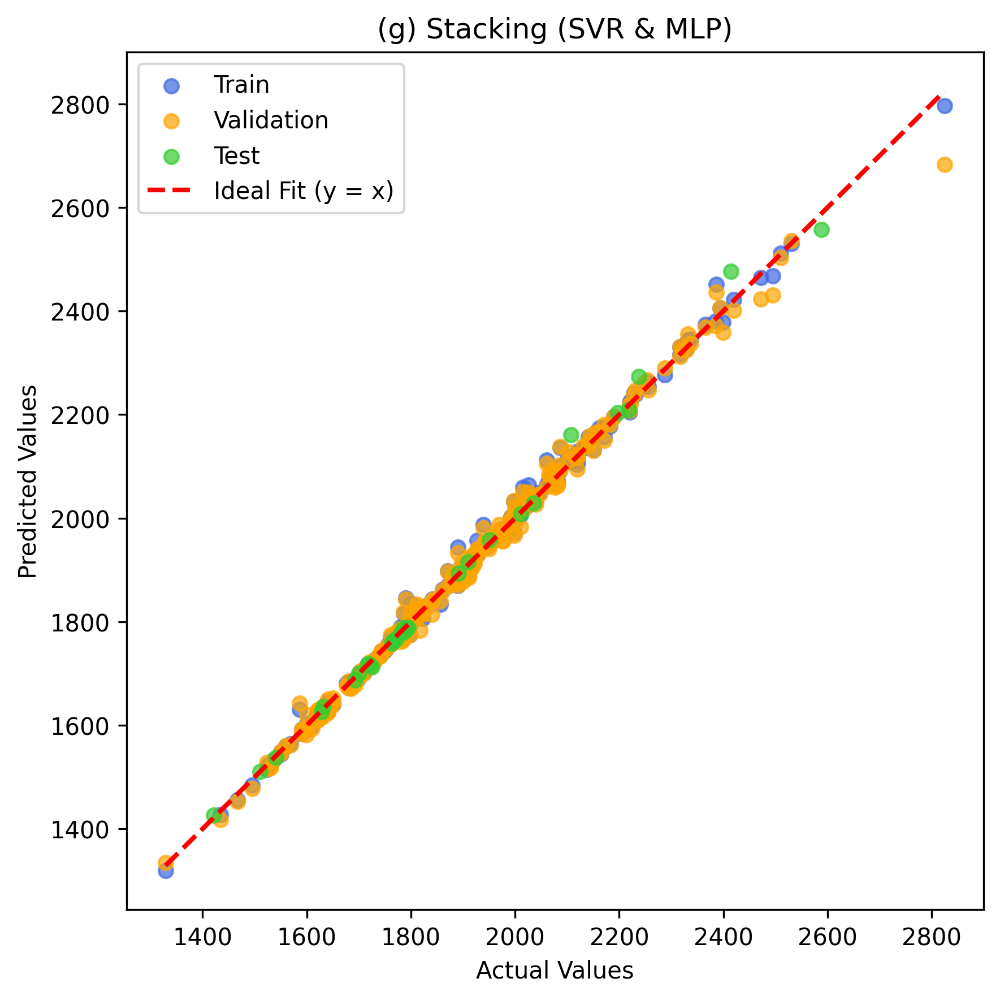

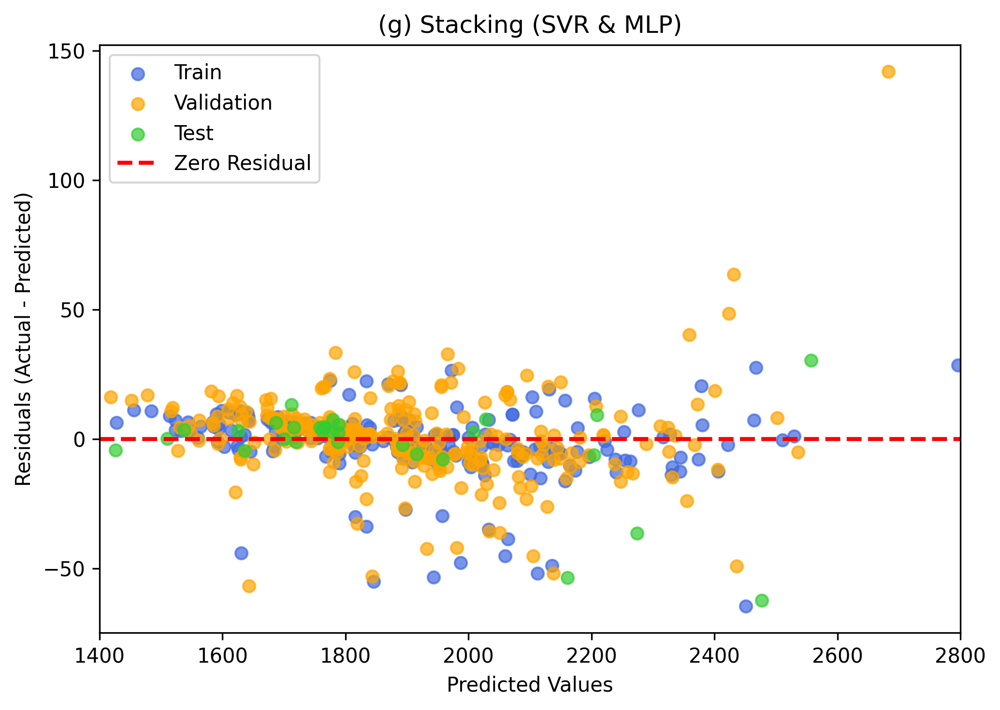

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


def plot_combined_predictions(
        y_true_train, y_pred_train,
        y_true_val, y_pred_val,
        y_true_test, y_pred_test):

    y_true_train, y_pred_train = (
        np.ravel(y_true_train),
        np.ravel(y_pred_train)
    )

    y_true_val, y_pred_val = (
        np.ravel(y_true_val),
        np.ravel(y_pred_val)
    )

    y_true_test, y_pred_test = (
        np.ravel(y_true_test),
        np.ravel(y_pred_test)
    )

    plt.figure(figsize=(6, 6), dpi=300)

    plt.scatter(
        y_true_train,
        y_pred_train,
        color='royalblue',
        alpha=0.7,
        label='Train'
    )

    plt.scatter(
        y_true_val,
        y_pred_val,
        color='orange',
        alpha=0.7,
        label='Validation'
    )

    plt.scatter(
        y_true_test,
        y_pred_test,
        color='limegreen',
        alpha=0.7,
        label='Test'
    )

    all_true = np.concatenate([
        y_true_train,
        y_true_val,
        y_true_test
    ])

    plt.plot(
        [all_true.min(), all_true.max()],
        [all_true.min(), all_true.max()],
        'r--',
        lw=2,
        label='Ideal Fit (y = x)'
    )

    plt.title("(g) Stacking (SVR & MLP)")

    plt.xlabel("Actual Values")
    plt.ylabel("Predicted Values")

    plt.legend()

    plt.grid(False)

    plt.tight_layout()

    plt.show()


# ============================================================
# Residuals (Train / Validation / Test)
# ============================================================

def plot_combined_residuals(
        y_true_train, y_pred_train,
        y_true_val, y_pred_val,
        y_true_test, y_pred_test):

    y_true_train, y_pred_train = (
        np.ravel(y_true_train),
        np.ravel(y_pred_train)
    )

    y_true_val, y_pred_val = (
        np.ravel(y_true_val),
        np.ravel(y_pred_val)
    )

    y_true_test, y_pred_test = (
        np.ravel(y_true_test),
        np.ravel(y_pred_test)
    )

    residuals_train = (
        y_true_train - y_pred_train
    )

    residuals_val = (
        y_true_val - y_pred_val
    )

    residuals_test = (
        y_true_test - y_pred_test
    )

    plt.figure(figsize=(7, 5), dpi=300)

    plt.scatter(
        y_pred_train,
        residuals_train,
        color='royalblue',
        alpha=0.7,
        label='Train'
    )

    plt.scatter(
        y_pred_val,
        residuals_val,
        color='orange',
        alpha=0.7,
        label='Validation'
    )

    plt.scatter(
        y_pred_test,
        residuals_test,
        color='limegreen',
        alpha=0.7,
        label='Test'
    )

    plt.xlim(1400, 2800)

    plt.axhline(
        0,
        color='red',
        linestyle='--',
        lw=2,
        label='Zero Residual'
    )

    plt.title(
        "(g) Stacking (SVR & MLP)"
    )

    plt.xlabel("Predicted Values")

    plt.ylabel(
        "Residuals (Actual - Predicted)"
    )

    plt.legend()

    plt.grid(False)

    plt.tight_layout()

    plt.show()


# ============================================================
# PLOT 1 — ACTUAL VS PREDICTED
# ============================================================

plot_combined_predictions(
    # Train
    y_temp,
    p_stack_train,

    # Validation (Pooled Out-of-Fold)
    y_temp,
    oof_predictions['Stacking'],

    # Independent Test
    y_test,
    p_stack_test
)


# ============================================================
# PLOT 2 — RESIDUALS
# ============================================================

plot_combined_residuals(
    # Train
    y_temp,
    p_stack_train,

    # Validation (Pooled Out-of-Fold)
    y_temp,
    oof_predictions['Stacking'],

    # Independent Test
    y_test,
    p_stack_test
)

Stacking (mlp+gpr)

In [ ]:

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import random
import time
import warnings

from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

warnings.filterwarnings("default")

# ============================================================
# 1. Reproducibility and data preparation
# ============================================================
SEED = 42

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(SEED)

X_temp = np.asarray(X_temp)
X_test = np.asarray(X_test)
y_temp = np.asarray(y_temp).reshape(-1, 1)
y_test = np.asarray(y_test).reshape(-1, 1)

assert len(X_temp) == len(y_temp)
assert len(X_test) == len(y_test)
assert len(X_temp) >= 5

print("X_temp samples:", len(X_temp))
print("X_test samples :", len(X_test))
print("Number of features:", X_temp.shape[1])


# ============================================================
# 2. Hyperparameters
# ============================================================

# MLP: unchanged from the previous code
best_lr = 0.01
best_alpha = 0.0001
epochs = 250

# GPR: requested parameters
gpr_alpha = 0.1
n_restarts_optimizer = 5
normalize_y = True

# Ridge meta-learner
ridge_alpha = 1.0

N_SPLITS = 5


# ============================================================
# 3. MLP architecture
# ============================================================
class MLP(nn.Module):
    def __init__(self, input_dim):
        super().__init__()

        self.model = nn.Sequential(
            nn.Linear(input_dim, 10),
            nn.ReLU(),
            nn.Linear(10, 10),
            nn.ReLU(),
            nn.Linear(10, 1)
        )

    def forward(self, x):
        return self.model(x)


def train_mlp(X_s, y_s, seed=42):
    set_seed(seed)

    model = MLP(X_s.shape[1])

    optimizer = optim.Adam(
        model.parameters(),
        lr=best_lr,
        weight_decay=best_alpha
    )

    criterion = nn.MSELoss()

    Xt = torch.tensor(X_s, dtype=torch.float32)
    yt = torch.tensor(y_s, dtype=torch.float32)

    for _ in range(epochs):
        model.train()
        optimizer.zero_grad()

        loss = criterion(model(Xt), yt)
        loss.backward()
        optimizer.step()

    model.eval()
    return model


def predict_mlp(model, X_s):
    with torch.no_grad():
        Xt = torch.tensor(X_s, dtype=torch.float32)
        return model(Xt).cpu().numpy()


# ============================================================
# 4. GPR kernel and base models
# ============================================================
def make_gpr(seed=42):
    # Equivalent kernel structure:
    # 1**2 * RBF(length_scale=5) + WhiteKernel(noise_level=5)
    kernel = (
        1.0**2 * RBF(length_scale=5.0)
        + WhiteKernel(noise_level=5.0)
    )

    return GaussianProcessRegressor(
        kernel=kernel,
        alpha=gpr_alpha,
        n_restarts_optimizer=n_restarts_optimizer,
        normalize_y=normalize_y,
        random_state=seed
    )


def fit_bases(X, y, seed=42):
    # Fit preprocessing only on the current training fold
    xs = StandardScaler().fit(X)
    ys = StandardScaler().fit(y)

    X_s = xs.transform(X)
    y_s = ys.transform(y)

    # GPR
    gpr = make_gpr(seed=seed)
    gpr.fit(X_s, y_s.ravel())

    # MLP
    mlp = train_mlp(X_s, y_s, seed=seed)

    return gpr, mlp, xs, ys


def predict_bases(gpr, mlp, xs, ys, X):
    X_s = xs.transform(X)

    p_gpr_s = gpr.predict(X_s).reshape(-1, 1)
    p_mlp_s = predict_mlp(mlp, X_s)

    # Convert both predictions to original target units
    p_gpr = ys.inverse_transform(p_gpr_s).ravel()
    p_mlp = ys.inverse_transform(p_mlp_s).ravel()

    return p_gpr, p_mlp


# ============================================================
# 5. Metrics
# ============================================================
def calc_metrics(y_true, y_pred):
    y_true = np.asarray(y_true).ravel()
    y_pred = np.asarray(y_pred).ravel()

    return {
        "MSE": mean_squared_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred)
    }


def evaluate_all(name, y_true, y_pred):
    metrics = calc_metrics(y_true, y_pred)

    print(f"\n{name}:")
    print(f"  MSE  = {metrics['MSE']:.4f}")
    print(f"  MAE  = {metrics['MAE']:.4f}")
    print(f"  RMSE = {metrics['RMSE']:.4f}")
    print(f"  R2   = {metrics['R2']:.4f}")

    return metrics


# ============================================================
# 6. Generate OOF meta-features for Ridge
# ============================================================
def generate_oof_meta_features(X, y, n_splits=5, seed=42):
    """
    Each sample's meta-features are generated by base models
    that did not train on that sample.
    """

    n_splits = min(n_splits, len(X))

    if n_splits < 2:
        raise ValueError("At least two samples are required.")

    oof_gpr = np.full(len(X), np.nan)
    oof_mlp = np.full(len(X), np.nan)

    kf = KFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=seed
    )

    for fold, (fit_idx, hold_idx) in enumerate(kf.split(X), start=1):
        X_fit, y_fit = X[fit_idx], y[fit_idx]
        X_hold = X[hold_idx]

        gpr, mlp, xs, ys = fit_bases(
            X_fit,
            y_fit,
            seed=seed + fold
        )

        p_gpr, p_mlp = predict_bases(
            gpr, mlp, xs, ys, X_hold
        )

        oof_gpr[hold_idx] = p_gpr
        oof_mlp[hold_idx] = p_mlp

    if np.isnan(oof_gpr).any() or np.isnan(oof_mlp).any():
        raise RuntimeError("OOF predictions are incomplete.")

    return np.column_stack([oof_gpr, oof_mlp])


# ============================================================
# 7. Outer 5-fold cross-validation
# ============================================================
outer_kf = KFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=SEED
)

model_names = ["GPR", "MLP", "Stacking"]

cv_results = {
    name: {"MSE": [], "RMSE": [], "MAE": [], "R2": []}
    for name in model_names
}

oof_predictions = {
    name: np.full(len(X_temp), np.nan)
    for name in model_names
}

fold_indices = []

print("\n========== 5-Fold Cross-Validation ==========")
cv_start = time.time()

for fold, (tr_idx, val_idx) in enumerate(
    outer_kf.split(X_temp), start=1
):
    X_tr, X_val = X_temp[tr_idx], X_temp[val_idx]
    y_tr, y_val = y_temp[tr_idx], y_temp[val_idx]

    # Train Ridge using OOF predictions from outer training data only
    meta_oof = generate_oof_meta_features(
        X_tr,
        y_tr,
        n_splits=N_SPLITS,
        seed=SEED + 100 * fold
    )

    ridge = Ridge(alpha=ridge_alpha)
    ridge.fit(meta_oof, y_tr.ravel())

    # Fit base models on the complete outer training fold
    gpr, mlp, xs, ys = fit_bases(
        X_tr,
        y_tr,
        seed=SEED + fold
    )

    # Validation predictions
    p_gpr_val, p_mlp_val = predict_bases(
        gpr, mlp, xs, ys, X_val
    )

    p_stack_val = ridge.predict(
        np.column_stack([p_gpr_val, p_mlp_val])
    )

    predictions = {
        "GPR": p_gpr_val,
        "MLP": p_mlp_val,
        "Stacking": p_stack_val
    }

    # Save outer OOF predictions
    for name, pred in predictions.items():
        oof_predictions[name][val_idx] = pred

        metrics = calc_metrics(y_val.ravel(), pred)

        for metric in ["MSE", "RMSE", "MAE", "R2"]:
            cv_results[name][metric].append(metrics[metric])

    fold_indices.append((tr_idx.copy(), val_idx.copy()))

    print(
        f"Fold {fold}: "
        f"GPR R2={cv_results['GPR']['R2'][-1]:.4f} | "
        f"MLP R2={cv_results['MLP']['R2'][-1]:.4f} | "
        f"Stacking R2={cv_results['Stacking']['R2'][-1]:.4f}"
    )

cv_time = time.time() - cv_start


# ============================================================
# 8. Mean and standard deviation across folds
# ============================================================
print("\n========== Mean 5-Fold CV Results ==========")

cv_summary_rows = []

for name in model_names:
    row = {"Model": name}

    for metric in ["RMSE", "MAE", "R2"]:
        values = np.asarray(cv_results[name][metric])

        row[f"{metric}_Mean"] = values.mean()
        row[f"{metric}_Std"] = values.std(ddof=1)

    cv_summary_rows.append(row)

cv_summary = pd.DataFrame(cv_summary_rows)

print(
    cv_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


# ============================================================
# 9. Pooled outer OOF evaluation
# ============================================================
print("\n========== Pooled Outer-OOF Results ==========")

pooled_oof_metrics = {}

for name in model_names:
    if np.isnan(oof_predictions[name]).any():
        raise RuntimeError(f"Incomplete OOF predictions for {name}.")

    pooled_oof_metrics[name] = evaluate_all(
        f"{name} - Pooled Outer OOF",
        y_temp.ravel(),
        oof_predictions[name]
    )


# ============================================================
# 10. Final training on all X_temp
# ============================================================
print("\n========== Final Model Training ==========")

final_start = time.time()

# Train meta-learner using OOF predictions from all development data
final_meta_oof = generate_oof_meta_features(
    X_temp,
    y_temp,
    n_splits=N_SPLITS,
    seed=SEED + 1000
)

final_ridge = Ridge(alpha=ridge_alpha)
final_ridge.fit(final_meta_oof, y_temp.ravel())

# Fit final base models on all development data
final_gpr, final_mlp, final_xs, final_ys = fit_bases(
    X_temp,
    y_temp,
    seed=SEED
)

final_train_time = time.time() - final_start


# ============================================================
# 11. In-sample training evaluation
# ============================================================
p_gpr_train, p_mlp_train = predict_bases(
    final_gpr, final_mlp,
    final_xs, final_ys,
    X_temp
)

p_stack_train = final_ridge.predict(
    np.column_stack([p_gpr_train, p_mlp_train])
)

print("\n========== Final Training Metrics ==========")

m_gpr_train = evaluate_all(
    "GPR Train (in-sample)",
    y_temp.ravel(), p_gpr_train
)

m_mlp_train = evaluate_all(
    "MLP Train (in-sample)",
    y_temp.ravel(), p_mlp_train
)

m_stack_train = evaluate_all(
    "Stacking Train (in-sample)",
    y_temp.ravel(), p_stack_train
)


# ============================================================
# 12. Independent test evaluation
# ============================================================
test_start = time.time()

p_gpr_test, p_mlp_test = predict_bases(
    final_gpr, final_mlp,
    final_xs, final_ys,
    X_test
)

p_stack_test = final_ridge.predict(
    np.column_stack([p_gpr_test, p_mlp_test])
)

test_time = time.time() - test_start

print("\n========== Independent Test Results ==========")

m_gpr_test = evaluate_all(
    "GPR Test",
    y_test.ravel(), p_gpr_test
)

m_mlp_test = evaluate_all(
    "MLP Test",
    y_test.ravel(), p_mlp_test
)

m_stack_test = evaluate_all(
    "Stacking Test",
    y_test.ravel(), p_stack_test
)


# ============================================================
# 13. Summary table
# ============================================================
train_metrics = {
    "GPR": m_gpr_train,
    "MLP": m_mlp_train,
    "Stacking": m_stack_train
}

test_metrics = {
    "GPR": m_gpr_test,
    "MLP": m_mlp_test,
    "Stacking": m_stack_test
}

summary_rows = []

for name in model_names:
    summary_rows.append({
        "Model": name,

        "Train_RMSE": train_metrics[name]["RMSE"],
        "Train_R2": train_metrics[name]["R2"],

        "CV_RMSE_Mean": np.mean(cv_results[name]["RMSE"]),
        "CV_RMSE_Std": np.std(
            cv_results[name]["RMSE"], ddof=1
        ),

        "CV_R2_Mean": np.mean(cv_results[name]["R2"]),
        "CV_R2_Std": np.std(
            cv_results[name]["R2"], ddof=1
        ),

        "Test_RMSE": test_metrics[name]["RMSE"],
        "Test_R2": test_metrics[name]["R2"]
    })

summary = pd.DataFrame(summary_rows)

print("\n========== FINAL SUMMARY TABLE ==========")
print(
    summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

summary.to_csv("gpr_mlp_stacking_summary.csv", index=False)
cv_summary.to_csv("gpr_mlp_stacking_cv_summary.csv", index=False)


# ============================================================
# 14. Computational time
# ============================================================
print("\n========== COMPUTATIONAL TIME ==========")
print(f"Outer CV time     : {cv_time:.2f} s")
print(f"Final training    : {final_train_time:.2f} s")
print(f"Test prediction   : {test_time:.4f} s")

print("\nSaved:")
print(" - gpr_mlp_stacking_summary.csv")
print(" - gpr_mlp_stacking_cv_summary.csv")
print("\nDone.")


X_temp samples: 270
X_test samples : 30
Number of features: 6

========== 5-Fold Cross-Validation ==========


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: Deprecat

Fold 1: GPR R2=0.9837 | MLP R2=0.9837 | Stacking R2=0.9882


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: Deprecat

Fold 2: GPR R2=0.9939 | MLP R2=0.9914 | Stacking R2=0.9948


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: Deprecat

... (4 outputs left out)

Fold 5: GPR R2=0.9906 | MLP R2=0.9964 | Stacking R2=0.9961

========== Mean 5-Fold CV Results ==========
   Model  RMSE_Mean  RMSE_Std  MAE_Mean  MAE_Std  R2_Mean  R2_Std
     GPR    22.2130    6.9603   15.9652   4.2844   0.9894  0.0040
     MLP    20.5058    8.2478   13.1888   4.2187   0.9907  0.0049
Stacking    18.0990    6.6848   12.4803   3.7549   0.9928  0.0037

========== Pooled Outer-OOF Results ==========

GPR - Pooled Outer OOF:
  MSE  = 532.1743
  MAE  = 15.9652
  RMSE = 23.0689
  R2   = 0.9892

MLP - Pooled Outer OOF:
  MSE  = 474.9100
  MAE  = 13.1888
  RMSE = 21.7924
  R2   = 0.9904

Stacking - Pooled Outer OOF:
  MSE  = 363.3232
  MAE  = 12.4803
  RMSE = 19.0610
  R2   = 0.9926

========== Final Model Training ==========


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: Deprecat


========== Final Training Metrics ==========

GPR Train (in-sample):
  MSE  = 325.1375
  MAE  = 13.3837
  RMSE = 18.0316
  R2   = 0.9934

MLP Train (in-sample):
  MSE  = 104.0348
  MAE  = 7.5485
  RMSE = 10.1997
  R2   = 0.9979

Stacking Train (in-sample):
  MSE  = 167.1447
  MAE  = 9.5225
  RMSE = 12.9284
  R2   = 0.9966

========== Independent Test Results ==========

GPR Test:
  MSE  = 305.5068
  MAE  = 12.0161
  RMSE = 17.4788
  R2   = 0.9955

MLP Test:
  MSE  = 262.2994
  MAE  = 11.4462
  RMSE = 16.1957
  R2   = 0.9961

Stacking Test:
  MSE  = 234.5262
  MAE  = 9.0324
  RMSE = 15.3142
  R2   = 0.9966

========== FINAL SUMMARY TABLE ==========
   Model  Train_RMSE  Train_R2  CV_RMSE_Mean  CV_RMSE_Std  CV_R2_Mean  CV_R2_Std  Test_RMSE  Test_R2
     GPR     18.0316    0.9934       22.2130       6.9603      0.9894     0.0040    17.4788   0.9955
     MLP     10.1997    0.9979       20.5058       8.2478      0.9907     0.0049    16.1957   0.9961
Stacking     12.9284    0.9966       18.

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


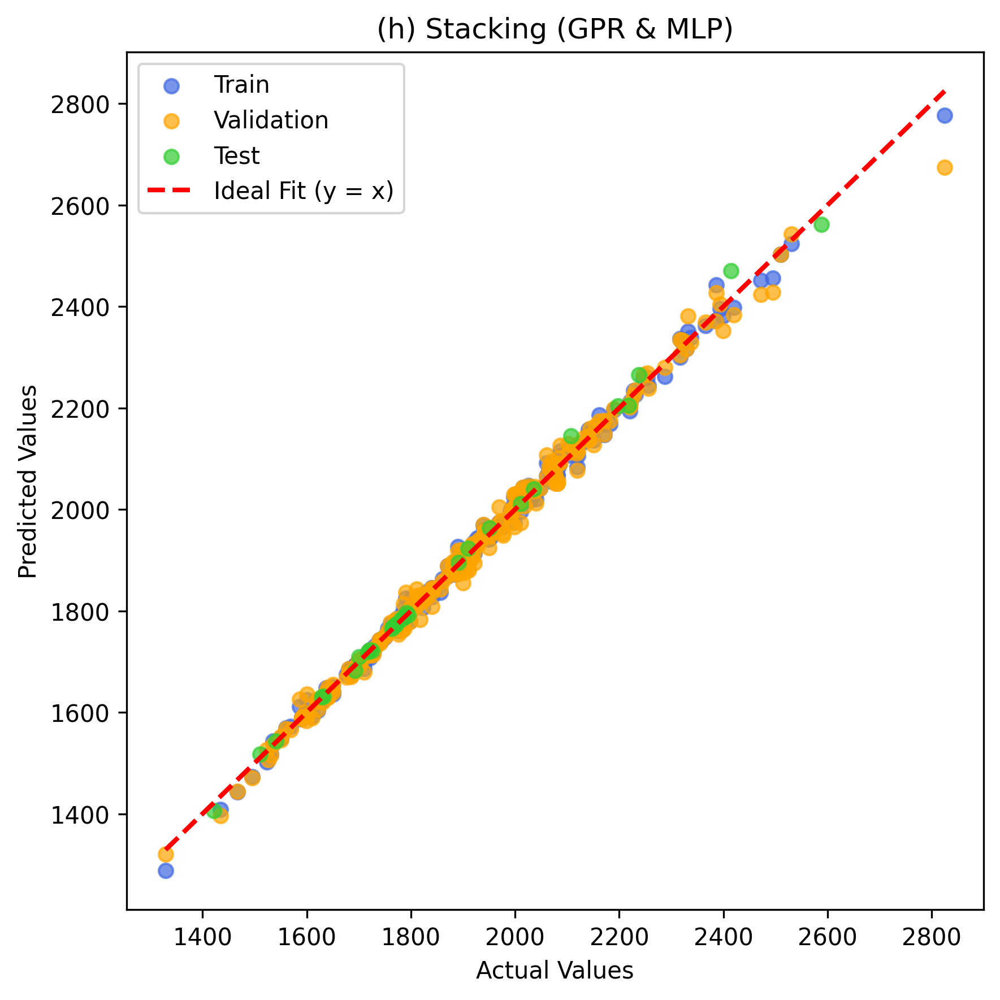

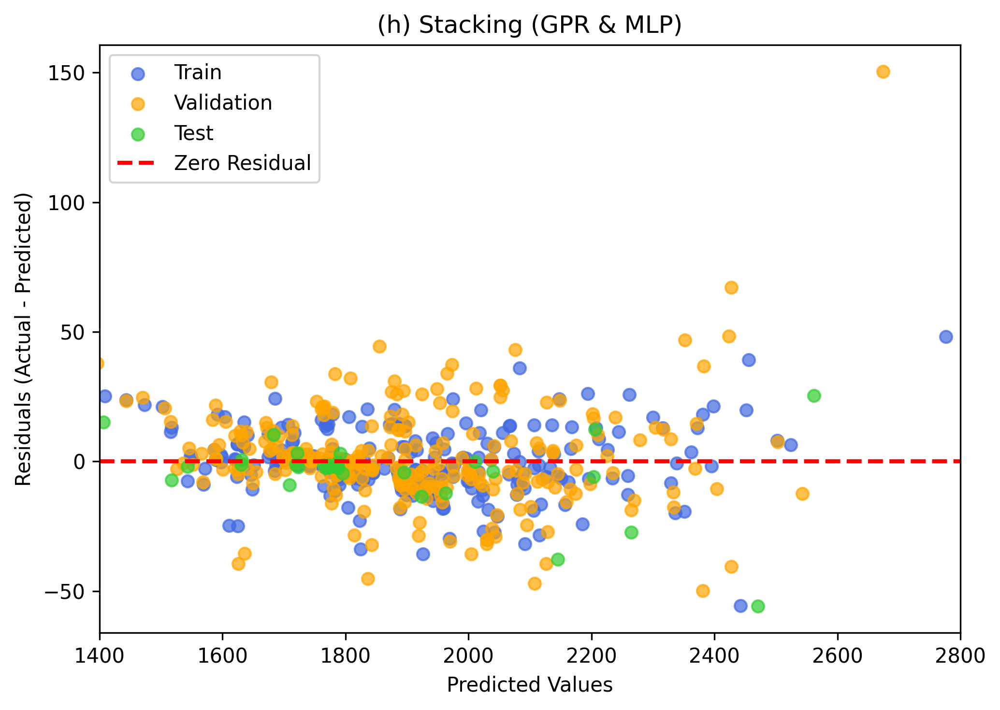

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


def plot_combined_predictions(
        y_true_train, y_pred_train,
        y_true_val, y_pred_val,
        y_true_test, y_pred_test):

    y_true_train, y_pred_train = (
        np.ravel(y_true_train),
        np.ravel(y_pred_train)
    )

    y_true_val, y_pred_val = (
        np.ravel(y_true_val),
        np.ravel(y_pred_val)
    )

    y_true_test, y_pred_test = (
        np.ravel(y_true_test),
        np.ravel(y_pred_test)
    )

    plt.figure(figsize=(6, 6), dpi=300)

    plt.scatter(
        y_true_train,
        y_pred_train,
        color='royalblue',
        alpha=0.7,
        label='Train'
    )

    plt.scatter(
        y_true_val,
        y_pred_val,
        color='orange',
        alpha=0.7,
        label='Validation'
    )

    plt.scatter(
        y_true_test,
        y_pred_test,
        color='limegreen',
        alpha=0.7,
        label='Test'
    )

    all_true = np.concatenate([
        y_true_train,
        y_true_val,
        y_true_test
    ])

    plt.plot(
        [all_true.min(), all_true.max()],
        [all_true.min(), all_true.max()],
        'r--',
        lw=2,
        label='Ideal Fit (y = x)'
    )

    plt.title("(h) Stacking (GPR & MLP)")

    plt.xlabel("Actual Values")
    plt.ylabel("Predicted Values")

    plt.legend()

    plt.grid(False)

    plt.tight_layout()

    plt.show()


# ============================================================
# Residuals (Train / Validation / Test)
# ============================================================

def plot_combined_residuals(
        y_true_train, y_pred_train,
        y_true_val, y_pred_val,
        y_true_test, y_pred_test):

    y_true_train, y_pred_train = (
        np.ravel(y_true_train),
        np.ravel(y_pred_train)
    )

    y_true_val, y_pred_val = (
        np.ravel(y_true_val),
        np.ravel(y_pred_val)
    )

    y_true_test, y_pred_test = (
        np.ravel(y_true_test),
        np.ravel(y_pred_test)
    )

    residuals_train = (
        y_true_train - y_pred_train
    )

    residuals_val = (
        y_true_val - y_pred_val
    )

    residuals_test = (
        y_true_test - y_pred_test
    )

    plt.figure(figsize=(7, 5), dpi=300)

    plt.scatter(
        y_pred_train,
        residuals_train,
        color='royalblue',
        alpha=0.7,
        label='Train'
    )

    plt.scatter(
        y_pred_val,
        residuals_val,
        color='orange',
        alpha=0.7,
        label='Validation'
    )

    plt.scatter(
        y_pred_test,
        residuals_test,
        color='limegreen',
        alpha=0.7,
        label='Test'
    )

    plt.xlim(1400, 2800)

    plt.axhline(
        0,
        color='red',
        linestyle='--',
        lw=2,
        label='Zero Residual'
    )

    plt.title(
        "(h) Stacking (GPR & MLP)"
    )

    plt.xlabel("Predicted Values")

    plt.ylabel(
        "Residuals (Actual - Predicted)"
    )

    plt.legend()

    plt.grid(False)

    plt.tight_layout()

    plt.show()


# ============================================================
# PLOT 1 — ACTUAL VS PREDICTED
# ============================================================

plot_combined_predictions(
    # Train
    y_temp,
    p_stack_train,

    # Validation (Pooled Out-of-Fold)
    y_temp,
    oof_predictions['Stacking'],

    # Independent Test
    y_test,
    p_stack_test
)


# ============================================================
# PLOT 2 — RESIDUALS
# ============================================================

plot_combined_residuals(
    # Train
    y_temp,
    p_stack_train,

    # Validation (Pooled Out-of-Fold)
    y_temp,
    oof_predictions['Stacking'],

    # Independent Test
    y_test,
    p_stack_test
)


========== Learning Curve: GPR + MLP Stacking ==========

----- Learning-curve repeat 1/3 -----


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: Deprecat

Total development samples =   54 | Training samples/fold ~   43 | Validation samples/fold ~  11


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: Deprecat

Total development samples =   85 | Training samples/fold ~   68 | Validation samples/fold ~  17


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: Deprecat

... (40 outputs left out)

Total development samples =  239 | Training samples/fold ~  191 | Validation samples/fold ~  48


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: Deprecat

Total development samples =  270 | Training samples/fold ~  216 | Validation samples/fold ~  54

========== Learning Curve Summary ==========
 Development_Size  Train_RMSE_Mean  Train_RMSE_STD  Validation_RMSE_Mean  Validation_RMSE_STD  Validation_R2_Mean  Validation_R2_STD
               54          22.1281          6.9441               37.9511              14.0787              0.9610             0.0300
               85          18.7009          4.3435               30.7186              13.0182              0.9757             0.0138
              116          17.8542          3.8141               25.5928               9.9230              0.9857             0.0071
              147          14.2469          2.5049               23.2315               8.2003              0.9884             0.0049
              177          13.8901          1.8285               21.9849               5.2490              0.9884             0.0055
              208          12.5916          1.5871          

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


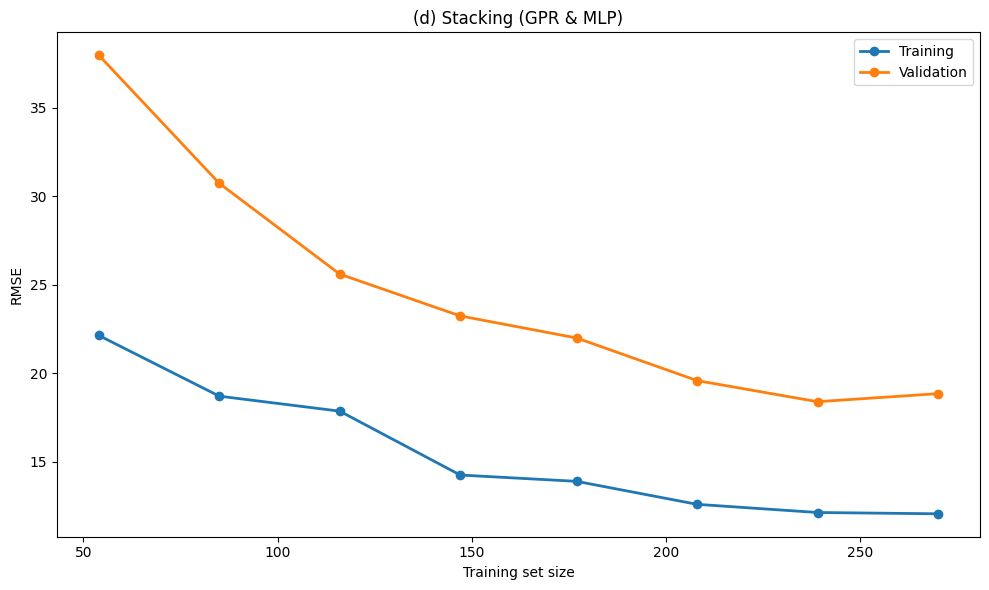


Learning-curve computation time: 621.50 seconds


In [ ]:

# ============================================================
# 12. Learning Curve using 5-Fold Cross-Validation
# Stacking: GPR + MLP + Ridge
# X-axis = total development samples in each experiment
# Maximum development subset size = len(X_temp), e.g. 270
# ============================================================

print("\n========== Learning Curve: GPR + MLP Stacking ==========")

LC_POINTS = 8
LC_REPEATS = 3
LC_SPLITS = 5

lc_start = time.time()
N_total = len(X_temp)

# Total development subset sizes, including the full X_temp
train_sizes = np.unique(
    np.round(
        np.linspace(
            max(LC_SPLITS + 1, int(0.20 * N_total)),
            N_total,
            LC_POINTS
        )
    ).astype(int)
)

lc_results = {
    int(n): {
        "train_rmse": [],
        "val_rmse": [],
        "val_r2": []
    }
    for n in train_sizes
}

for repeat in range(LC_REPEATS):

    # Different nested sample ordering for each repeat
    rng = np.random.RandomState(SEED + 5000 + repeat)
    permutation = rng.permutation(N_total)

    print(
        f"\n----- Learning-curve repeat "
        f"{repeat + 1}/{LC_REPEATS} -----"
    )

    for n_samples in train_sizes:

        selected_idx = permutation[:n_samples]

        X_subset = X_temp[selected_idx]
        y_subset = y_temp[selected_idx]

        # Five-fold CV on this development subset
        lc_kf = KFold(
            n_splits=LC_SPLITS,
            shuffle=True,
            random_state=(
                SEED + 100 * repeat + int(n_samples)
            )
        )

        for fold, (tr_idx, val_idx) in enumerate(
            lc_kf.split(X_subset), start=1
        ):

            X_tr = X_subset[tr_idx]
            y_tr = y_subset[tr_idx]

            X_val = X_subset[val_idx]
            y_val = y_subset[val_idx]

            # ------------------------------------------------
            # A. Generate leakage-free OOF meta-features
            #    using GPR and MLP on the outer training fold
            # ------------------------------------------------
            meta_oof = generate_oof_meta_features(
                X_tr,
                y_tr,
                n_splits=LC_SPLITS,
                seed=(
                    SEED + 10000
                    + repeat * 1000
                    + int(n_samples) * 10
                    + fold
                )
            )

            # Train Ridge meta-model using OOF predictions
            ridge_lc = Ridge(alpha=ridge_alpha)
            ridge_lc.fit(meta_oof, y_tr.ravel())

            # ------------------------------------------------
            # B. Fit GPR and MLP on the outer training fold
            # ------------------------------------------------
            gpr_lc, mlp_lc, xs_lc, ys_lc = fit_bases(
                X_tr,
                y_tr,
                seed=(
                    SEED + repeat * 1000
                    + int(n_samples) * 10
                    + fold
                )
            )

            # ------------------------------------------------
            # C. Training predictions (in-sample)
            # ------------------------------------------------
            p_gpr_tr, p_mlp_tr = predict_bases(
                gpr_lc,
                mlp_lc,
                xs_lc,
                ys_lc,
                X_tr
            )

            meta_tr = np.column_stack([
                p_gpr_tr.ravel(),
                p_mlp_tr.ravel()
            ])

            pred_tr = ridge_lc.predict(meta_tr)

            rmse_tr = np.sqrt(
                mean_squared_error(
                    y_tr.ravel(),
                    pred_tr
                )
            )

            # ------------------------------------------------
            # D. Validation predictions
            # ------------------------------------------------
            p_gpr_val, p_mlp_val = predict_bases(
                gpr_lc,
                mlp_lc,
                xs_lc,
                ys_lc,
                X_val
            )

            meta_val = np.column_stack([
                p_gpr_val.ravel(),
                p_mlp_val.ravel()
            ])

            pred_val = ridge_lc.predict(meta_val)

            rmse_val = np.sqrt(
                mean_squared_error(
                    y_val.ravel(),
                    pred_val
                )
            )

            r2_val = r2_score(
                y_val.ravel(),
                pred_val
            )

            lc_results[int(n_samples)]["train_rmse"].append(
                rmse_tr
            )
            lc_results[int(n_samples)]["val_rmse"].append(
                rmse_val
            )
            lc_results[int(n_samples)]["val_r2"].append(
                r2_val
            )

        # Report total subset size versus actual fold sizes
        print(
            f"Total development samples = {n_samples:4d} | "
            f"Training samples/fold ~ "
            f"{int(round(n_samples * 0.8)):4d} | "
            f"Validation samples/fold ~ "
            f"{int(round(n_samples * 0.2)):3d}"
        )


# ============================================================
# 12.1. Mean and standard deviation across folds and repeats
# ============================================================

lc_rows = []

for n_samples in train_sizes:

    tr_values = np.asarray(
        lc_results[int(n_samples)]["train_rmse"]
    )

    val_values = np.asarray(
        lc_results[int(n_samples)]["val_rmse"]
    )

    r2_values = np.asarray(
        lc_results[int(n_samples)]["val_r2"]
    )

    lc_rows.append({
        "Development_Size": int(n_samples),
        "Train_RMSE_Mean": tr_values.mean(),
        "Train_RMSE_STD": tr_values.std(ddof=1),
        "Validation_RMSE_Mean": val_values.mean(),
        "Validation_RMSE_STD": val_values.std(ddof=1),
        "Validation_R2_Mean": r2_values.mean(),
        "Validation_R2_STD": r2_values.std(ddof=1)
    })

learning_curve_df = pd.DataFrame(lc_rows)

print("\n========== Learning Curve Summary ==========")
print(
    learning_curve_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


# ============================================================
# 12.2. Plot the learning curve
# ============================================================

x = learning_curve_df["Development_Size"].to_numpy()

train_mean = learning_curve_df["Train_RMSE_Mean"].to_numpy()
val_mean = learning_curve_df["Validation_RMSE_Mean"].to_numpy()

plt.figure(figsize=(10, 6))

plt.plot(
    x,
    train_mean,
    "o-",
    linewidth=2,
    label="Training"
)

plt.plot(
    x,
    val_mean,
    "o-",
    linewidth=2,
    label="Validation"
)

plt.title("(d) Stacking (GPR & MLP)")
plt.xlabel("Training set size")
plt.ylabel("RMSE")
plt.legend()
plt.tight_layout()

plt.savefig(
    "gpr_mlp_stacking_learning_curve_cv.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 12.3. Save results
# ============================================================

learning_curve_df.to_csv(
    "gpr_mlp_stacking_learning_curve_cv.csv",
    index=False
)

lc_time = time.time() - lc_start

print(
    f"\nLearning-curve computation time: "
    f"{lc_time:.2f} seconds"
)

In [ ]:
# Complete prediction output

train_results = pd.DataFrame({
    "Dataset": "Train",
    "Actual": y_temp.ravel(),
    "Predicted": p_stack_train.ravel()
})

test_results = pd.DataFrame({
    "Dataset": "Test",
    "Actual": y_test.ravel(),
    "Predicted": p_stack_test.ravel()
})

all_predictions = pd.concat(
    [train_results, test_results],
    ignore_index=True
)

all_predictions["Error"] = (
    all_predictions["Actual"] -
    all_predictions["Predicted"]
)

all_predictions["Absolute_Error"] = (
    np.abs(all_predictions["Error"])
)

all_predictions.to_excel(
    "Stacking_All_Predictions.xlsx",
    index=False
)

print("All predictions exported successfully.")

All predictions exported successfully.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
import platform
import psutil
import os
import torch

# CPU information
print("========== CPU INFORMATION ==========")
print("Processor:", platform.processor())
print("CPU Cores (Physical):", psutil.cpu_count(logical=False))
print("CPU Cores (Logical):", psutil.cpu_count(logical=True))

# RAM information
print("\n========== RAM INFORMATION ==========")
ram = psutil.virtual_memory()
print(f"Total RAM: {ram.total / (1024**3):.2f} GB")

# GPU information
print("\n========== GPU INFORMATION ==========")
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA Version:", torch.version.cuda)
    print("GPU Memory:",
          torch.cuda.get_device_properties(0).total_memory / (1024**3),
          "GB")
else:
    print("No GPU available")

# Operating system
print("\n========== SYSTEM INFORMATION ==========")
print("OS:", platform.platform())
print("Python Version:", platform.python_version())
print("PyTorch Version:", torch.__version__)

========== CPU INFORMATION ==========
Processor: x86_64
CPU Cores (Physical): 1
CPU Cores (Logical): 2

========== RAM INFORMATION ==========
Total RAM: 12.67 GB

========== GPU INFORMATION ==========
No GPU available

========== SYSTEM INFORMATION ==========
OS: Linux-6.6.159+-x86_64-with-glibc2.39
Python Version: 3.13.18
PyTorch Version: 2.11.0+cpu


In [ ]:
!lscpu

Architecture:                x86_64
  CPU op-mode(s):            32-bit, 64-bit
  Address sizes:             46 bits physical, 48 bits virtual
  Byte Order:                Little Endian
CPU(s):                      2
  On-line CPU(s) list:       0,1
Vendor ID:                   GenuineIntel
  Model name:                Intel(R) Xeon(R) CPU @ 2.20GHz
    CPU family:              6
    Model:                   79
    Thread(s) per core:      2
    Core(s) per socket:      1
    Socket(s):               1
    Stepping:                0
    BogoMIPS:                4399.99
    Flags:                   fpu vme de pse tsc msr pae mce cx8 apic sep mtrr pg
                             e mca cmov pat pse36 clflush mmx fxsr sse sse2 ss h
                             t syscall nx pdpe1gb rdtscp lm constant_tsc rep_goo
                             d nopl xtopology nonstop_tsc cpuid tsc_known_freq p
                             ni pclmulqdq ssse3 fma cx16 pcid sse4_1 sse4_2 x2ap
                   

In [ ]:
!free -h

               total        used        free      shared  buff/cache   available
Mem:            12Gi       1.9Gi       8.6Gi       4.3Mi       2.5Gi        10Gi
Swap:             0B          0B          0B


In [ ]:
import sklearn
import numpy
import pandas
import xgboost
import torch

print("Scikit-learn:", sklearn.__version__)
print("NumPy:", numpy.__version__)
print("Pandas:", pandas.__version__)
print("XGBoost:", xgboost.__version__)
print("PyTorch:", torch.__version__)

Scikit-learn: 1.6.1
NumPy: 2.1.3
Pandas: 2.2.3
XGBoost: 3.4.1
PyTorch: 2.11.0+cpu
